# Phase 1 — Complexity measure of extreme events

**Dhiman Das, Arnob Ray, Chittaranjan Hens, Dibakar Ghosh,
Md. Kamrul Hassan, Artur Dabrowski, Tomasz Kapitaniak, and Syamal K. Dana (2024).**
*Complexity measure of extreme events*, Chaos **34**, 121104.
DOI: [10.1063/5.0232645](https://doi.org/10.1063/5.0232645).

The primary source is the supplied [original paper](../paper/11%20Complexity%20measure%20of%20extreme%20events.pdf),
especially Section II, Section III.A, Eqs. (1)–(4), and the captions of Figs. 1–2
(journal pages 3–5). No separate research summary is required.

**Objective:** verify the probability-based complexity measure, implement the forced
Liénard oscillator, and examine three representative dynamical conditions.
Workflow: integrate the equations, discard a transient, collect local maxima of
**y**, construct amplitude probabilities, calculate S, D, C, and inspect time series
and distributions. The significant-height marker is calculated separately.

This notebook completes **Phase 1 only**. Selected Fig. 2 panels are compared
qualitatively; Fig. 1 parameter sweeps, complete figure reproduction, other models,
and methodological extensions are outside scope. Saved outputs document the
executed configuration rather than the authors' original data.

## 1. Setup and provenance

The paper reports the model parameters, 50 equal-width amplitude bins, two
transition frequencies, Fig. 2 frequencies, and T = mean + 6 × standard deviation.
It does **not specify** initial conditions, forcing start phase, solver, tolerances,
sampling interval, transient duration, or full record length in Sections II/III.A.
The visible Fig. 2 time axes span about 5,000–20,000 time units; this does not
determine the length used for its probability distributions.

In [1]:
import platform
from time import perf_counter

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
from IPython.display import Markdown, display
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks

plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print(f"Python {platform.python_version()}")
print(f"NumPy {np.__version__}; SciPy {scipy.__version__}")
print(f"Matplotlib {matplotlib.__version__}")

Python 3.12.10
NumPy 2.5.3; SciPy 1.18.1
Matplotlib 3.11.2


In [2]:
# Reported in Sections II and III.A.
MODEL = {"alpha": 0.45, "beta": 0.50, "gamma": -0.50, "force": 0.2}
N_BINS = 50
HEIGHT_FACTOR = 6.0

# Implementation assumptions, in the model's time units.
NUMERICS = {
    "initial_state": (1.0, 0.0),
    "transient": 5_000.0,
    "duration": 50_000.0,
    "sample_dt": 0.05,
    "method": "DOP853",
    "rtol": 1e-9,
    "atol": 1e-11,
    "max_step": 0.5,
}
REGIMES = {
    "periodic": {"omega": 0.642, "label": "Before PM onset"},
    "pm": {"omega": 0.642236, "label": "PM intermittency"},
    "crisis": {"omega": 0.731693, "label": "Interior crisis"},
}
print("Deterministic equations: no random numbers or random seed are used.")
print(NUMERICS)

Deterministic equations: no random numbers or random seed are used.
{'initial_state': (1.0, 0.0), 'transient': 5000.0, 'duration': 50000.0, 'sample_dt': 0.05, 'method': 'DOP853', 'rtol': 1e-09, 'atol': 1e-11, 'max_step': 0.5}


The two extreme-event frequencies are reported in **Fig. 2(a,b)** and **Fig. 2(e,f)**.
The periodic reference, ω = 0.642, is selected from the pre-onset range in Fig. 1(a),
below the reported PM transition ω ≈ 0.642212; it is not a Fig. 2 frequency.
The interior-crisis transition is reported near ω ≈ 0.73242, with the extreme-event
side at lower ω. Each run starts independently at t = 0 with (x, y) = (1, 0),
uses the forcing sin(ωt) with zero phase, removes [0, 5000), and retains
[5000, 55000]. No parameter continuation or attractor search is performed.

The output interval Δt = 0.05 and the adaptive solver's maximum internal step 0.5
are different settings. Primary peak amplitudes are evaluated at downward zeros
of dy/dt using the solver's event interpolation; independently sampled peaks
check that the uniform output resolves those events. All are implementation
choices. Rare-event frequencies and basin dependence remain finite-record limitations.

## 2. Complexity measure — Section II

For local-extrema amplitudes, form **m = 50 equal-width bins between their minimum
and maximum** and set pᵢ = countᵢ / number of extrema, including empty bins.
Edges are chosen independently for each record as described in the paper.

\[
S=-\frac{\sum_{i=1}^{m}p_i\log_2p_i}{\log_2m},\qquad
D=\frac{m}{m-1}\sum_{i=1}^{m}\left(p_i-\frac1m\right)^2,
\qquad C=SD.
\]

The convention 0 log₂ 0 = 0 avoids logarithms of zero. Exactly constant peak
sequences occupy one bin, giving (S, D, C) = (0, 1, 0); NumPy supplies a finite
display range when min = max. A constant *raw signal* has no isolated extrema and
is rejected at the histogram stage rather than assigned fabricated peaks.
No peaks are removed with a prominence or height filter.

In [3]:
def local_extrema(time, values, kind="max"):
    """Extract interior sampled extrema; flat peaks use their midpoint."""
    time = np.asarray(time, dtype=float)
    values = np.asarray(values, dtype=float)
    if (
        time.ndim != 1
        or values.ndim != 1
        or time.size != values.size
        or time.size < 3
        or not np.all(np.isfinite(time))
        or not np.all(np.isfinite(values))
        or np.any(np.diff(time) <= 0)
    ):
        raise ValueError(
            "Provide matching finite series and increasing times."
        )
    if kind not in {"max", "min"}:
        raise ValueError("kind must be 'max' or 'min'.")
    indices, _ = find_peaks(values if kind == "max" else -values)
    return time[indices], values[indices]


def amplitude_histogram(extrema, bins=N_BINS):
    """Return probabilities and equal-width amplitude-bin edges."""
    extrema = np.asarray(extrema, dtype=float)
    if extrema.ndim != 1 or extrema.size == 0:
        raise ValueError("At least one extremum is required.")
    if not np.all(np.isfinite(extrema)):
        raise ValueError("Extrema must be finite.")
    if not isinstance(bins, (int, np.integer)) or bins < 2:
        raise ValueError("Use an integer number of bins greater than one.")
    counts, edges = np.histogram(extrema, bins=bins)
    return counts / extrema.size, edges

In [4]:
def complexity_measures(probabilities):
    """Calculate normalized entropy, disequilibrium, and complexity."""
    p = np.asarray(probabilities, dtype=float)
    if (
        p.ndim != 1
        or p.size < 2
        or not np.all(np.isfinite(p))
        or np.any(p < 0)
        or not np.isclose(p.sum(), 1.0, rtol=1e-10, atol=1e-12)
    ):
        raise ValueError(
            "Provide a normalized, nonnegative probability vector."
        )
    positive = p[p > 0]
    entropy = -np.sum(positive * np.log2(positive)) / np.log2(p.size)
    disequilibrium = p.size / (p.size - 1) * np.sum((p - 1 / p.size) ** 2)
    return (
        float(entropy),
        float(disequilibrium),
        float(entropy * disequilibrium),
    )

## 3. Mathematical validation

The concentrated and uniform distributions verify both normalization constants
and the two zero-complexity limits. An intermediate distribution checks the
product independently. Signal and histogram checks verify that the estimated
probabilities describe extrema amplitudes, including constant and empty cases.
These tests validate the estimator; they cannot establish a dynamical mechanism.

In [5]:
concentrated = np.zeros(N_BINS)
concentrated[0] = 1.0
uniform = np.full(N_BINS, 1.0 / N_BINS)
np.testing.assert_allclose(
    complexity_measures(concentrated), (0, 1, 0), atol=1e-14
)
np.testing.assert_allclose(complexity_measures(uniform), (1, 0, 0), atol=1e-14)

intermediate = np.zeros(N_BINS)
intermediate[:2] = (0.75, 0.25)
expected_s = -(0.75 * np.log2(0.75) + 0.25 * np.log2(0.25)) / np.log2(N_BINS)
expected_d = (N_BINS * (0.75**2 + 0.25**2) - 1) / (N_BINS - 1)
np.testing.assert_allclose(
    complexity_measures(intermediate),
    (expected_s, expected_d, expected_s * expected_d),
)
assert np.all(
    (np.array(complexity_measures(intermediate)) > 0)
    & (np.array(complexity_measures(intermediate)) < 1)
)

p_test, edges_test = amplitude_histogram([0, 0, 0, 1, 2, 3])
np.testing.assert_allclose(p_test.sum(), 1.0)
np.testing.assert_allclose(np.diff(edges_test), np.diff(edges_test)[0])
p_constant, _ = amplitude_histogram(np.full(20, 5.0))
np.testing.assert_allclose(
    complexity_measures(p_constant), (0, 1, 0), atol=1e-14
)

test_time = np.arange(9.0)
test_signal = np.array([0, 1, 0, -1, 0, 1, 0, -1, 0])
np.testing.assert_array_equal(local_extrema(test_time, test_signal)[0], [1, 5])
np.testing.assert_array_equal(
    local_extrema(test_time, test_signal, "min")[0], [3, 7]
)
assert local_extrema(test_time, np.ones(9))[0].size == 0
for invalid in ([], [np.nan]):
    try:
        amplitude_histogram(invalid)
    except ValueError:
        pass
    else:
        raise AssertionError("Invalid extrema were accepted.")
print(
    "All analytical limits, intermediate values, and extraction checks passed."
)

All analytical limits, intermediate values, and extraction checks passed.


## 4. Forced Liénard model — Eq. (4)

\[
\dot x=y,\qquad
\dot y=-\alpha xy-\gamma x-\beta x^3+F\sin(\omega t).
\]

The observable is **y**, so its maxima satisfy dy/dt = 0 with downward crossing.
Maxima of x would instead satisfy y = 0 and would not reproduce the observable
in Figs. 1–2. Event roots refine amplitudes without changing the equation or
selecting peaks by amplitude. The finite maximum step still needs checking:
event detection cannot guarantee finding multiple crossings within one step.

In [6]:
def lienard(time, state, omega):
    """Forced Liénard system, Eq. (4)."""
    x, y = state
    alpha, beta = MODEL["alpha"], MODEL["beta"]
    gamma, force = MODEL["gamma"], MODEL["force"]
    return y, -alpha * x * y - gamma * x - beta * x**3 + force * np.sin(
        omega * time
    )


def y_maximum(time, state, omega):
    """Locate local maxima of y from downward crossings of dy/dt."""
    return lienard(time, state, omega)[1]


y_maximum.direction = -1
y_maximum.terminal = False

In [7]:
def simulate_lienard(omega, settings):
    """Integrate from t=0 and return the retained signal and refined maxima."""
    transient = settings["transient"]
    duration = settings["duration"]
    dt = settings["sample_dt"]
    intervals = round(duration / dt)
    if not np.isclose(intervals * dt, duration):
        raise ValueError(
            "The retained duration must be divisible by sample_dt."
        )
    times = transient + dt * np.arange(intervals + 1)
    start = perf_counter()
    solution = solve_ivp(
        lienard,
        (0.0, float(times[-1])),
        settings["initial_state"],
        args=(omega,),
        t_eval=times,
        events=y_maximum,
        method=settings["method"],
        rtol=settings["rtol"],
        atol=settings["atol"],
        max_step=settings["max_step"],
    )
    if not solution.success:
        raise RuntimeError(solution.message)
    if solution.t.size != times.size or not np.all(np.isfinite(solution.y)):
        raise RuntimeError(
            "Integration did not return a complete finite record."
        )
    keep = (solution.t_events[0] > times[0]) & (
        solution.t_events[0] < times[-1]
    )
    return {
        "omega": omega,
        "time": solution.t,
        "state": solution.y,
        "peak_time": solution.t_events[0][keep],
        "peaks": solution.y_events[0][keep, 1],
        "nfev": solution.nfev,
        "seconds": perf_counter() - start,
    }

## 5. Representative dynamics

Only the three fixed frequencies declared above are simulated. The retained
50,000 time units aim to collect multiple rare bursts, not to estimate converged
rare-event probabilities. Each probability histogram uses every retained refined
maximum, including negative maxima and peaks below the significant-height marker.

In [8]:
results = {}
for name, regime in REGIMES.items():
    result = simulate_lienard(regime["omega"], NUMERICS)
    p, edges = amplitude_histogram(result["peaks"])
    result.update(
        {
            "probabilities": p,
            "edges": edges,
            "measures": complexity_measures(p),
        }
    )
    results[name] = result
    print(
        f"{name}: omega={result['omega']:.6f}; {result['peaks'].size} maxima; "
        f"{result['nfev']:,} RHS evaluations; {result['seconds']:.1f} s"
    )

periodic: omega=0.642000; 5109 maxima; 2,858,264 RHS evaluations; 16.9 s


pm: omega=0.642236; 5319 maxima; 2,874,563 RHS evaluations; 17.2 s


crisis: omega=0.731693; 5872 maxima; 2,745,275 RHS evaluations; 16.9 s


**Separate reference marker.** For this implementation μ and σ are calculated
from the retained local maxima, and σ uses the population convention (ddof = 0).
The paper refers to event heights and does not state a ddof convention. The
marker T = μ + 6σ identifies sample exceedances; it is not an input to the
histogram, entropy, disequilibrium, or complexity. An exceedance alone does not
prove PM intermittency, an interior crisis, or a universal definition of extremes.

In [9]:
rows = [
    "| Condition | omega | Maxima | S | D | C | T | Peaks > T | Fraction |",
    "|---|---:|---:|---:|---:|---:|---:|---:|---:|",
]
for name, result in results.items():
    peaks = result["peaks"]
    threshold = peaks.mean() + HEIGHT_FACTOR * peaks.std(ddof=0)
    count = int(np.count_nonzero(peaks > threshold))
    result.update({"threshold": threshold, "exceedances": count})
    s, d, c = result["measures"]
    rows.append(
        f"| {REGIMES[name]['label']} | {result['omega']:.6f} | {peaks.size} | "
        f"{s:.6f} | {d:.6f} | {c:.6f} | {threshold:.6f} | {count} | "
        f"{count / peaks.size:.4%} |"
    )
display(Markdown("\n".join(rows)))

| Condition | omega | Maxima | S | D | C | T | Peaks > T | Fraction |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Before PM onset | 0.642000 | 5109 | 0.791154 | 0.042777 | 0.033843 | 0.420921 | 0 | 0.0000% |
| PM intermittency | 0.642236 | 5319 | 0.284104 | 0.552935 | 0.157091 | 2.194481 | 42 | 0.7896% |
| Interior crisis | 0.731693 | 5872 | 0.425881 | 0.230823 | 0.098303 | 1.700511 | 29 | 0.4939% |

### 5.1 Periodic reference and the numerical histogram problem

The paper's ideal period-1 state has a single peak amplitude. Numerically distinct
values separated by integration roundoff can nevertheless fill many bins when
the histogram rescales to their tiny min–max range. The primary estimator below
keeps those unaltered values. A clearly labeled rounding diagnostic tests whether
the apparent dispersion survives an amplitude resolution of 10⁻⁶; it does not
replace the reported probabilities or introduce a height filter.

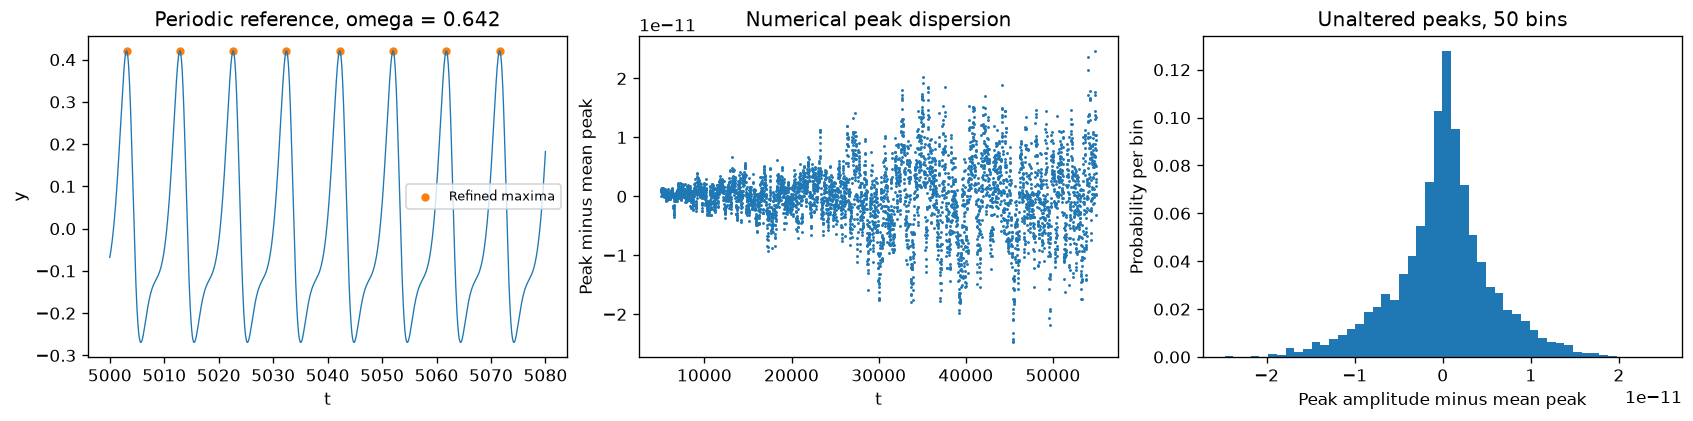

In [10]:
periodic = results["periodic"]
mean_peak = periodic["peaks"].mean()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), layout="constrained")
window = periodic["time"] <= periodic["time"][0] + 80
peak_window = periodic["peak_time"] <= periodic["time"][0] + 80
axes[0].plot(periodic["time"][window], periodic["state"][1, window], lw=0.8)
axes[0].scatter(
    periodic["peak_time"][peak_window],
    periodic["peaks"][peak_window],
    color="tab:orange",
    s=16,
    label="Refined maxima",
)
axes[0].set(xlabel="t", ylabel="y", title="Periodic reference, omega = 0.642")
axes[0].legend(fontsize=8)
axes[1].plot(periodic["peak_time"], periodic["peaks"] - mean_peak, ".", ms=1.5)
axes[1].set(
    xlabel="t",
    ylabel="Peak minus mean peak",
    title="Numerical peak dispersion",
)
axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
axes[2].bar(
    (periodic["edges"][:-1] + periodic["edges"][1:]) / 2 - mean_peak,
    periodic["probabilities"],
    width=np.diff(periodic["edges"]),
)
axes[2].set(
    xlabel="Peak amplitude minus mean peak",
    ylabel="Probability per bin",
    title="Unaltered peaks, 50 bins",
)
axes[2].ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
plt.show()

**Diagnostic purpose and result:** compare the stable oscillation with the much
smaller numerical spread of its refined maxima. Rescaling 50 bins to that spread
can yield nonzero entropy and complexity despite periodic motion. This is a
numerical limitation of literal per-record min–max binning, so the unaltered
periodic S, D, C must not be interpreted as physical chaos or a quantitative match
to Fig. 1(c,e). The next cell measures the spread and tests an explicit resolution.

In [11]:
rounded_peaks = np.round(periodic["peaks"], decimals=6)
p_rounded, _ = amplitude_histogram(rounded_peaks)
print(f"Unaltered periodic peak range: {np.ptp(periodic['peaks']):.3e}")
print("Unaltered S, D, C:", periodic["measures"])
print(
    "Diagnostic only, peaks rounded to 1e-6:", complexity_measures(p_rounded)
)
print("Distinct rounded amplitudes:", np.unique(rounded_peaks))

Unaltered periodic peak range: 4.946e-11
Unaltered S, D, C: (0.7911537481245882, 0.042776860035645764, 0.033843073150202053)
Diagnostic only, peaks rounded to 1e-6: (-0.0, 0.9999999999999998, -0.0)
Distinct rounded amplitudes: [0.420921]


### 5.2 Selected extreme-event conditions

The next plots compare only Fig. 2(a,b) and (e,f). The additional middle panel
shows **all** extracted peak amplitudes over time. For rendering the raw trace,
every fifth output sample is drawn (display spacing 0.25); all refined maxima
remain overlaid. Analysis uses the full record and is independent of this display
choice. Histogram probabilities pᵢ are converted to PDF heights pᵢ / bin width
for the semi-log plot; empty bins are omitted without adding pseudocounts.

In [12]:
def plot_extreme_condition(result, title):
    """Plot retained dynamics, extracted maxima, and amplitude density."""
    fig, axes = plt.subplots(
        1, 3, figsize=(15, 3.6), width_ratios=(2, 1.3, 1), layout="constrained"
    )
    axes[0].plot(result["time"][::5], result["state"][1, ::5], lw=0.5)
    axes[0].scatter(
        result["peak_time"],
        result["peaks"],
        s=2,
        color="tab:orange",
        label="Refined maxima",
        zorder=3,
    )
    axes[0].axhline(result["threshold"], color="tab:red", ls="--", label="T")
    axes[0].set(xlabel="t", ylabel="y", title=title)
    axes[0].legend(fontsize=8)
    axes[1].plot(result["peak_time"], result["peaks"], ".", ms=1.8)
    axes[1].axhline(result["threshold"], color="tab:red", ls="--")
    axes[1].set(
        xlabel="t", ylabel="y maxima", title="Every retained local maximum"
    )
    widths = np.diff(result["edges"])
    centers = result["edges"][:-1] + widths / 2
    occupied = result["probabilities"] > 0
    axes[2].bar(
        centers[occupied],
        result["probabilities"][occupied] / widths[occupied],
        width=widths[occupied],
    )
    axes[2].axvline(result["threshold"], color="tab:red", ls="--")
    axes[2].set(
        yscale="log",
        xlabel="y maxima",
        ylabel="Probability density",
        title="50 equal-width bins",
    )
    s, d, c = result["measures"]
    fig.suptitle(f"S = {s:.4f}, D = {d:.4f}, C = {c:.4f}")
    plt.show()

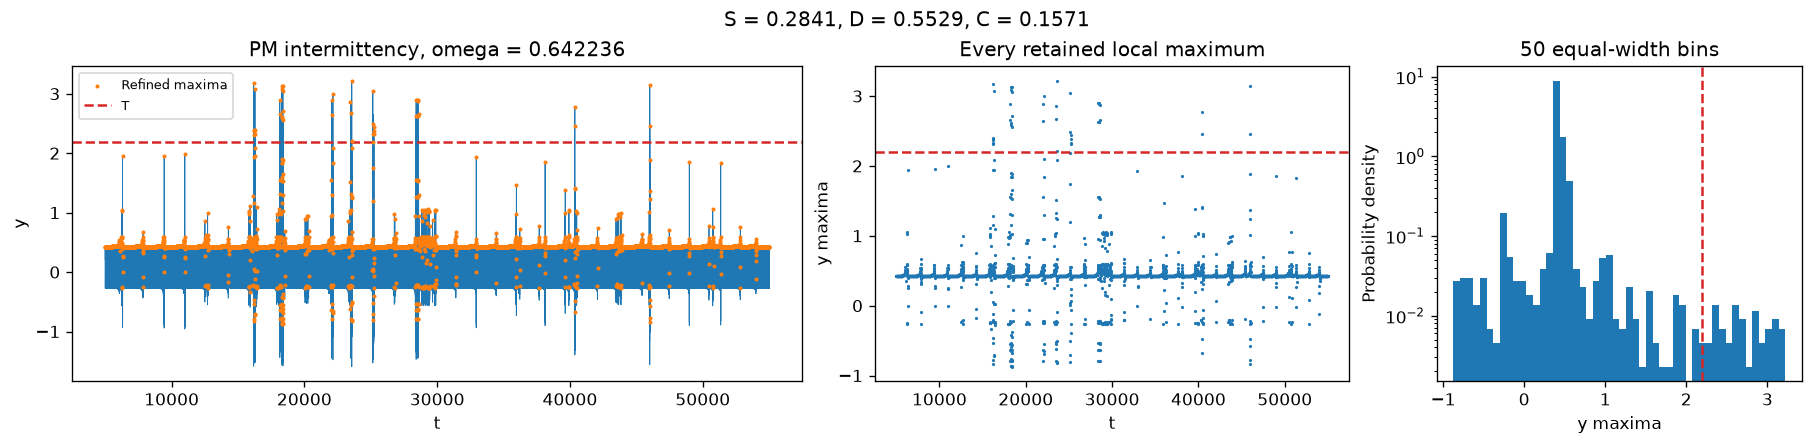

In [13]:
plot_extreme_condition(results["pm"], "PM intermittency, omega = 0.642236")

**Figure:** comparison with Fig. 2(a,b); the peak sequence is an added diagnostic.
**Observation:** the executed record contains long intervals of nearly repeated
peaks interrupted by large bursts, with the exceedance count reported above.
**Scientific meaning:** infrequent peaks populate a low-probability amplitude
tail while the laminar peaks dominate the probability distribution, consistent
with the reported intermittency setting.
**Reproduction status:** **partially matched**; dynamics and threshold crossings
are compared, but neither the original trajectory nor converged PDF probabilities
are available, and the bifurcation mechanism is not independently established.

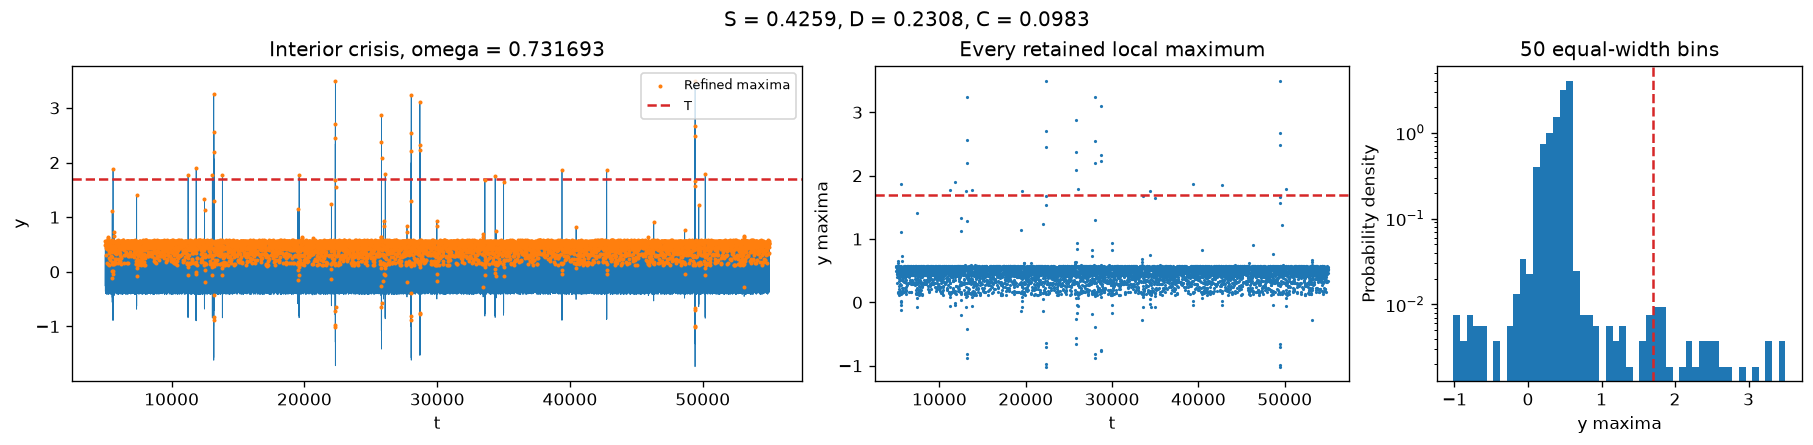

In [14]:
plot_extreme_condition(results["crisis"], "Interior crisis, omega = 0.731693")

**Figure:** comparison with Fig. 2(e,f); the peak sequence is an added diagnostic.
**Observation:** the retained signal has occasional large excursions and a
low-probability peak-amplitude tail, with sample exceedances tabulated above.
**Scientific meaning:** this is compatible with the paper's post-crisis excursions
outside a normally bounded part of the attractor; complexity uses every peak,
independently of whether it exceeds T.
**Reproduction status:** **partially matched**; the reported frequency is used,
but one time series cannot demonstrate an interior crisis or match the authors'
unknown numerical protocol and event statistics.

## 6. Preliminary validation and numerical limitations

### 6.1 Does uniform sampling resolve the refined extrema?

Compare sampled maxima against event-refined maxima throughout each retained
record. A one-sample margin excludes boundary peaks that a discrete detector
cannot bracket. Matching counts and times test event completeness at this
resolution, while amplitude differences quantify the downward bias from sampling.
The event-refined amplitudes remain the input to the primary estimator.

In [15]:
rows = [
    "| Condition | Paired maxima | Max time error | Max amplitude error |",
    "|---|---:|---:|---:|",
]
for name, result in results.items():
    time, y = result["time"], result["state"][1]
    sample_time, sample_peaks = local_extrema(time, y)
    lower, upper = (
        time[0] + NUMERICS["sample_dt"],
        time[-1] - NUMERICS["sample_dt"],
    )
    sample_keep = (sample_time > lower) & (sample_time < upper)
    event_keep = (result["peak_time"] > lower) & (result["peak_time"] < upper)
    sample_time, sample_peaks = (
        sample_time[sample_keep],
        sample_peaks[sample_keep],
    )
    event_time, event_peaks = (
        result["peak_time"][event_keep],
        result["peaks"][event_keep],
    )
    assert sample_peaks.size == event_peaks.size > 0
    time_error = np.max(np.abs(sample_time - event_time))
    amplitude_error = np.max(np.abs(sample_peaks - event_peaks))
    assert time_error <= NUMERICS["sample_dt"]
    assert np.all(sample_peaks <= event_peaks + 1e-8)
    rows.append(
        f"| {name} | {event_peaks.size} | {time_error:.3e} | "
        f"{amplitude_error:.3e} |"
    )
display(Markdown("\n".join(rows)))

| Condition | Paired maxima | Max time error | Max amplitude error |
|---|---:|---:|---:|
| periodic | 5109 | 2.509e-02 | 1.450e-04 |
| pm | 5319 | 2.521e-02 | 7.050e-04 |
| crisis | 5872 | 2.511e-02 | 7.806e-04 |

### 6.2 Local solver and sampling refinement near the largest burst

For each condition, restart a short interval from the **same state and absolute
forcing time**, about 20 time units before its largest peak. Compare the original
tolerances and maximum step with rtol = 10⁻¹¹, atol = 10⁻¹³, max_step = 0.25.
Also compare sampled peaks at Δt = 0.05 and 0.025 on the tighter solution.
This is a local accuracy check around a burst, not proof of global statistical
convergence: long chaotic trajectories need not remain pointwise close.

In [16]:
rows = [
    (
        "| Condition | Max state difference | Max refined-peak difference | "
        "Sampling error 0.05 | Sampling error 0.025 |"
    ),
    "|---|---:|---:|---:|---:|",
]
for name, result in results.items():
    peak_time = result["peak_time"][np.argmax(result["peaks"])]
    index = np.searchsorted(
        result["time"], max(result["time"][0], peak_time - 20)
    )
    start = result["time"][index]
    fine_time = start + np.arange(1601) * (NUMERICS["sample_dt"] / 2)
    span = (float(fine_time[0]), float(fine_time[-1]))
    initial = result["state"][:, index]
    solutions = []
    for rtol, atol, step in ((1e-9, 1e-11, 0.5), (1e-11, 1e-13, 0.25)):
        solution = solve_ivp(
            lienard,
            span,
            initial,
            args=(result["omega"],),
            method="DOP853",
            t_eval=fine_time,
            events=y_maximum,
            rtol=rtol,
            atol=atol,
            max_step=step,
        )
        if not solution.success:
            raise RuntimeError(solution.message)
        solutions.append(solution)
    baseline, refined = solutions
    assert baseline.t_events[0].size == refined.t_events[0].size > 0
    state_error = np.max(np.abs(baseline.y - refined.y))
    peak_error = np.max(
        np.abs(baseline.y_events[0][:, 1] - refined.y_events[0][:, 1])
    )
    assert state_error < 1e-4, "Investigate the local integration discrepancy."
    sample_errors = []
    for stride in (2, 1):
        ts, ys = local_extrema(refined.t[::stride], refined.y[1, ::stride])
        event_times = refined.t_events[0]
        nearest = np.argmin(np.abs(ts[:, None] - event_times[None, :]), axis=1)
        assert ts.size == event_times.size
        sample_errors.append(
            np.max(np.abs(ys - refined.y_events[0][nearest, 1]))
        )
    rows.append(
        f"| {name} | {state_error:.3e} | {peak_error:.3e} | "
        f"{sample_errors[0]:.3e} | {sample_errors[1]:.3e} |"
    )
display(Markdown("\n".join(rows)))

| Condition | Max state difference | Max refined-peak difference | Sampling error 0.05 | Sampling error 0.025 |
|---|---:|---:|---:|---:|
| periodic | 6.274e-10 | 1.846e-10 | 1.402e-04 | 3.092e-05 |
| pm | 4.282e-08 | 9.538e-09 | 3.550e-04 | 1.313e-04 |
| crisis | 3.093e-08 | 4.552e-09 | 5.376e-04 | 1.102e-04 |

### 6.3 Bounds, normalization, and finite-record sensitivity

The following checks verify all computed measures and the PDF normalization.
Two nonoverlapping halves provide a simple finite-record diagnostic. Each half
gets its own amplitude-bin range and significant-height marker by the same
procedure, so changes reflect both finite sampling and the adaptive bin range.
The halves are not independent replicates and these differences are not error
bars. No equality or ordering of complexities is imposed to imitate the paper.

In [17]:
rows = [
    "| Condition | Part | Maxima | C | Peaks > part-specific T |",
    "|---|---|---:|---:|---:|",
]
for name, result in results.items():
    p, edges = result["probabilities"], result["edges"]
    np.testing.assert_allclose(p.sum(), 1.0, atol=1e-14)
    np.testing.assert_allclose(
        np.sum((p / np.diff(edges)) * np.diff(edges)), 1.0
    )
    assert np.all(np.isfinite(result["measures"]))
    assert np.all(np.array(result["measures"]) >= -1e-14)
    assert np.all(np.array(result["measures"]) <= 1 + 1e-14)
    np.testing.assert_allclose(
        result["measures"][2], np.prod(result["measures"][:2])
    )
    midpoint = (result["time"][0] + result["time"][-1]) / 2
    for label, keep in (
        ("first half", result["peak_time"] < midpoint),
        ("second half", result["peak_time"] >= midpoint),
    ):
        peaks = result["peaks"][keep]
        part_p, _ = amplitude_histogram(peaks)
        c = complexity_measures(part_p)[2]
        threshold = peaks.mean() + HEIGHT_FACTOR * peaks.std(ddof=0)
        count = np.count_nonzero(peaks > threshold)
        rows.append(f"| {name} | {label} | {peaks.size} | {c:.6f} | {count} |")
display(Markdown("\n".join(rows)))
print("All retained records passed normalization and measure-bound checks.")

| Condition | Part | Maxima | C | Peaks > part-specific T |
|---|---|---:|---:|---:|
| periodic | first half | 2555 | 0.038155 | 0 |
| periodic | second half | 2554 | 0.015999 | 0 |
| pm | first half | 2712 | 0.164142 | 17 |
| pm | second half | 2607 | 0.134936 | 10 |
| crisis | first half | 2948 | 0.099881 | 16 |
| crisis | second half | 2924 | 0.096788 | 11 |

All retained records passed normalization and measure-bound checks.


### 6.4 Evidence from this execution

The next report is computed from the current outputs so that a changed record
length cannot silently retain a claim that rare events were observed. Threshold
crossings in an almost constant periodic peak sequence can be roundoff artifacts;
inspect the amplitude-spread diagnostic before giving such counts physical meaning.

In [18]:
for name in ("pm", "crisis"):
    result = results[name]
    count = result["exceedances"]
    if count:
        print(
            f"{name}: {count}/{result['peaks'].size} maxima exceed T; "
            "qualitative extreme-event signature observed."
        )
    else:
        print(
            f"{name}: no exceedance observed; "
            "rare-event reproduction is unconfirmed."
        )
    print(
        f"  Peak range [{result['peaks'].min():.6f}, "
        f"{result['peaks'].max():.6f}]; "
        f"T = {result['threshold']:.6f}; C = {result['measures'][2]:.6f}."
    )
print("periodic: numerical peak range =", f"{np.ptp(periodic['peaks']):.3e}")

pm: 42/5319 maxima exceed T; qualitative extreme-event signature observed.
  Peak range [-0.873307, 3.222832]; T = 2.194481; C = 0.157091.
crisis: 29/5872 maxima exceed T; qualitative extreme-event signature observed.
  Peak range [-1.014810, 3.501603]; T = 1.700511; C = 0.098303.
periodic: numerical peak range = 4.946e-11


### Phase 1 conclusions and Phase 2 handoff

- **Validated:** Eqs. (1)–(3), analytical limiting distributions, constant peak
  sequences, histogram/PDF normalization, maxima/minima extraction, and the
  working Eq. (4) solver. Sampling and local solver refinements quantify the
  numerical errors instead of judging only visual similarity.
- **Observed:** the periodic reference is examined through its peak dispersion;
  the PM and post-crisis records are evaluated for rare excursions using the
  counts and distributions above. These observations are consistent with the
  reported regimes where exceedances occur, but do not prove either bifurcation
  mechanism. Selected Fig. 2 comparisons remain **partially matched**.
- **Numerical assumptions:** independent (1, 0) initial conditions, zero forcing
  phase, DOP853 with the declared tolerances, 5,000 discarded and 50,000 retained
  time units, uniform output every 0.05, event-refined peaks, and ddof = 0 for T.
  No undocumented setting is attributed to the authors.
- **Differences and uncertainty:** there is no original trajectory or tabulated
  reference S, D, C for these records. Literal min–max histograms resolve tiny
  numerical variations in period-1 peaks and can produce spurious nonzero S and C;
  rounding is shown only as a diagnostic. Long-record event rates, transient
  adequacy, basin selection, and global statistical convergence remain uncertain.
- **Phase 2 tasks:** establish a justified amplitude-resolution convention for
  periodic data, check longer records and more than one initial condition, then
  design controlled frequency continuation and the Fig. 1 sweeps. Add the two
  non-extreme Fig. 2 conditions (0.643 and 0.73007) and assess distributions and
  rare-event rates across record lengths before claiming full reproduction.

All interpretation remains inside this notebook. No separate summary file,
external model module, parameter sweep, or additional dynamical system is created.

# Phase 2 — Main figure reproduction

The preceding 36 cells preserve the Phase 1 experiment and its original numerical
findings. Phase 2 continues below using its verified equations and estimators;
the old Phase 1 scope statement and rounding example are historical, not the
conventions adopted for the new figures.

**Sources:** the supplied original PDF, Sections II–III.B and Figs. 1–4, is the
primary source; the existing [research discussion](../sumarize_paper/Das_2024_discussion.md)
was read as supporting context. All new conclusions are recorded here; no new
summary file is needed. Reported parameters are retained exactly. Solver choices,
lengths, initial conditions, amplitude resolution, sweep grids, and computational
bracketing criteria below are **implementation assumptions**.

We first investigate numerical resolution, record length, and initial conditions.
Only then do we inspect coarse sweeps and refine near transitions. Main results
are qualitative comparisons with quantified finite-grid transition brackets,
not claims to reproduce unknown author trajectories or tabulated complexity values.

## 7. Stage A — Focused numerical validation

### 7.1 Cache and numerical configuration

The Liénard reference configuration remains DOP853, rtol = 10⁻⁹, atol = 10⁻¹¹,
max_step = 0.5, zero forcing phase, and 5,000 discarded time units. Main sweep
records retain 50,000 time units. The length study retains 100,000 and examines
nested 25,000 / 50,000 / 100,000 prefixes; these are not independent replicates.
The initial-condition study uses (1, 0), (0, 0), and (−1, 0), each at absolute t = 0.
This small deterministic sample is not a basin survey.

`das_2024_cache/` stores compressed extrema arrays and optional fixed display
segments, not full sweep trajectories. Every entry contains canonical JSON with
model parameters, all numerical settings, library versions, and a hash of the
actual model/integration source. The filename derives from that metadata; a
metadata mismatch raises an error instead of returning stale data. Changing
binning or plotting recomputes statistics without repeating unchanged integrations.
Cache files may be deleted; a top-to-bottom run will regenerate them.

In [19]:
import hashlib
import inspect
import json
from pathlib import Path

CACHE_DIR = Path("das_2024_cache")
CACHE_DIR.mkdir(exist_ok=True)
LIENARD_SETTINGS = {**NUMERICS, "trace_duration": 0.0}
INITIAL_STATES = ((1.0, 0.0), (0.0, 0.0), (-1.0, 0.0))
LENGTHS = (25_000.0, 50_000.0, 100_000.0)
CACHE_ACTIVITY = {"hits": 0, "computed": 0}


def show_table(headers, rows):
    """Render a compact scientific results table."""
    lines = ["| " + " | ".join(headers) + " |"]
    lines.append("|" + "|".join("---" for _ in headers) + "|")
    lines.extend("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown("\n".join(lines)))


CACHE_USED = set()

In [20]:
def run_lienard_peaks(omega, settings):
    """Reuse Eq. (4) and event refinement, retaining only needed outputs."""
    start = perf_counter()
    transient = settings["transient"]
    stop = transient + settings["duration"]
    trace_duration = settings["trace_duration"]
    if trace_duration:
        intervals = round(trace_duration / settings["sample_dt"])
        times = transient + settings["sample_dt"] * np.arange(intervals + 1)
        if times[-1] > stop:
            raise ValueError("Display segment exceeds the retained record.")
    else:
        times = [stop]
    solution = solve_ivp(
        lienard,
        (0.0, stop),
        settings["initial_state"],
        args=(omega,),
        events=y_maximum,
        t_eval=times,
        method=settings["method"],
        rtol=settings["rtol"],
        atol=settings["atol"],
        max_step=settings["max_step"],
    )
    if not solution.success or not np.all(np.isfinite(solution.y)):
        raise RuntimeError(f"omega={omega}: {solution.message}")
    keep = (solution.t_events[0] > transient) & (solution.t_events[0] < stop)
    return {
        "extrema_time": solution.t_events[0][keep],
        "extrema": solution.y_events[0][keep, 1],
        "trace_time": solution.t if trace_duration else np.array([]),
        "trace_y": solution.y[1] if trace_duration else np.array([]),
        "seconds": np.array(perf_counter() - start),
    }

In [21]:
def cached_simulation(model, parameter, settings):
    """Load an exactly matching cache entry or compute it atomically."""
    if model == "lienard":
        if y_maximum.direction != -1 or y_maximum.terminal:
            raise ValueError("Liénard requires nonterminal y maxima.")
        functions = (lienard, y_maximum, run_lienard_peaks)
        parameters, runner = MODEL, run_lienard_peaks
    elif model == "ikeda":
        functions = (ikeda_real, local_extrema, run_ikeda)
        parameters, runner = IKEDA, run_ikeda
    else:
        raise ValueError("Unknown model.")
    source = "\n".join(inspect.getsource(func) for func in functions)
    metadata = {
        "schema": 1,
        "model": model,
        "parameter": float(parameter),
        "parameters": parameters,
        "settings": settings,
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "python": platform.python_version(),
        "source_sha256": hashlib.sha256(source.encode()).hexdigest(),
        "extremum": "y maximum" if model == "lienard" else "y minimum",
    }
    serialized = json.dumps(metadata, sort_keys=True)
    key = hashlib.sha256(serialized.encode()).hexdigest()[:20]
    path = CACHE_DIR / f"{model}_{parameter:.9f}_{key}.npz"
    if path.exists():
        with np.load(path, allow_pickle=False) as saved:
            if saved["metadata"].item() != serialized:
                raise RuntimeError(f"Cache metadata mismatch: {path}")
            record = {
                name: saved[name].copy()
                for name in saved.files
                if name != "metadata"
            }
        CACHE_ACTIVITY["hits"] += 1
    else:
        record = runner(parameter, settings)
        if record["extrema"].size == 0:
            raise RuntimeError("The retained record contains no extrema.")
        if not np.all(np.isfinite(record["extrema"])):
            raise RuntimeError("Nonfinite extrema cannot be cached.")
        temporary = path.with_suffix(".tmp")
        with temporary.open("wb") as stream:
            np.savez_compressed(stream, metadata=serialized, **record)
        temporary.replace(path)
        CACHE_ACTIVITY["computed"] += 1
    CACHE_USED.add(path.name)
    return record

### 7.2 Calibrating the amplitude-resolution criterion

Literal min–max binning amplifies the *relative* spread even if the whole spread
is integration noise. We estimate a numerical amplitude scale by repeating the
40-time-unit intervals surrounding the largest peak of each Phase 1 condition
from identical states and forcing times, with tighter tolerances (10⁻¹¹, 10⁻¹³)
and half the maximum step. Let e be the largest paired peak-amplitude difference
and f = 100 × machine epsilon × max(1, observed amplitude scale).

The declared empirical resolution is **δ = 10 × max(e, f)**. Only when the
**entire** peak range is ≤ δ is the sequence treated as a single unresolved
amplitude level. Otherwise the original histogram and every peak remain exactly
unchanged; there is no rounding, clipping, removal of outliers, or merging of
individual bins. A rare excursion wider than δ therefore cannot be erased by
this rule. This is an implementation convention, not a modification claimed to
be in the paper, nor a certified error bound at every sweep frequency. A truly
physical variation below δ remains unresolved rather than proven periodic.

In [22]:
calibration_errors = []
for result in results.values():
    largest_time = result["peak_time"][np.argmax(result["peaks"])]
    index = np.searchsorted(
        result["time"], max(result["time"][0], largest_time - 20)
    )
    start = float(result["time"][index])
    pair = []
    for rtol, atol, step in (
        (NUMERICS["rtol"], NUMERICS["atol"], NUMERICS["max_step"]),
        (1e-11, 1e-13, NUMERICS["max_step"] / 2),
    ):
        solution = solve_ivp(
            lienard,
            (start, start + 40),
            result["state"][:, index],
            args=(result["omega"],),
            method=NUMERICS["method"],
            events=y_maximum,
            rtol=rtol,
            atol=atol,
            max_step=step,
            t_eval=[start + 40],
        )
        if not solution.success:
            raise RuntimeError(solution.message)
        pair.append(solution.y_events[0][:, 1])
    assert pair[0].size == pair[1].size > 0
    calibration_errors.append(float(np.max(np.abs(pair[0] - pair[1]))))
scale = max(1.0, *(np.max(np.abs(r["peaks"])) for r in results.values()))
floor = 100 * np.finfo(float).eps * scale
AMPLITUDE_RESOLUTION = 10 * max(floor, *calibration_errors)
print("Peak-refinement discrepancies:", calibration_errors)
print(f"Empirical amplitude resolution delta = {AMPLITUDE_RESOLUTION:.3e}")

Peak-refinement discrepancies: [1.845572028535969e-10, 9.538068113101872e-09, 4.551546695097386e-09]
Empirical amplitude resolution delta = 9.538e-08


In [23]:
def resolved_histogram(peaks, resolution=0.0):
    """Collapse wholly unresolved ranges; keep all other amplitudes literal."""
    peaks = np.asarray(peaks, dtype=float)
    if resolution < 0:
        raise ValueError("Amplitude resolution must be nonnegative.")
    collapsed = np.ptp(peaks) <= resolution
    values = np.full_like(peaks, peaks.mean()) if collapsed else peaks
    probabilities, edges = amplitude_histogram(values)
    return probabilities, edges, bool(collapsed)


def peak_statistics(peaks, duration, *, resolution=0.0, lower_tail=False):
    """Compute complexity independently from the significant-height marker."""
    p, edges, collapsed = resolved_histogram(peaks, resolution)
    s, d, c = complexity_measures(p)
    literal_p, _ = amplitude_histogram(peaks)
    factor = -5.0 if lower_tail else HEIGHT_FACTOR
    threshold = peaks.mean() + factor * peaks.std(ddof=0)
    count = np.count_nonzero(
        peaks < threshold if lower_tail else peaks > threshold
    )
    return {
        "s": s,
        "d": d,
        "c": c,
        "raw_c": complexity_measures(literal_p)[2],
        "threshold": float(threshold),
        "count": int(count),
        "rate": count / duration,
        "n": peaks.size,
        "probabilities": p,
        "edges": edges,
        "collapsed": collapsed,
        "span": float(np.ptp(peaks)),
    }

In [24]:
resolution_rows = []
for name, result in results.items():
    raw = complexity_measures(amplitude_histogram(result["peaks"])[0])
    p, _, collapsed = resolved_histogram(result["peaks"], AMPLITUDE_RESOLUTION)
    adjusted = complexity_measures(p)
    resolution_rows.append(
        [
            name,
            f"{np.ptp(result['peaks']):.3e}",
            str(collapsed),
            ", ".join(f"{value:.6f}" for value in raw),
            ", ".join(f"{value:.6f}" for value in adjusted),
        ]
    )
    if not collapsed:
        np.testing.assert_array_equal(
            p, amplitude_histogram(result["peaks"])[0]
        )
    for multiplier in (0.1, 10.0):
        alternative = resolved_histogram(
            result["peaks"], multiplier * AMPLITUDE_RESOLUTION
        )[0]
        np.testing.assert_allclose(complexity_measures(alternative), adjusted)
show_table(
    [
        "Condition",
        "Peak range",
        "Unresolved?",
        "Literal S, D, C",
        "Resolved S, D, C",
    ],
    resolution_rows,
)

rare_sequence = np.append(np.ones(999), 1 + 2 * AMPLITUDE_RESOLUTION)
rare_p, _, rare_collapsed = resolved_histogram(
    rare_sequence, AMPLITUDE_RESOLUTION
)
assert not rare_collapsed
np.testing.assert_array_equal(rare_p, amplitude_histogram(rare_sequence)[0])
assert np.count_nonzero(rare_p) == 2
print("A single resolvable rare excursion is preserved without filtering.")

| Condition | Peak range | Unresolved? | Literal S, D, C | Resolved S, D, C |
|---|---|---|---|---|
| periodic | 4.946e-11 | True | 0.791154, 0.042777, 0.033843 | -0.000000, 1.000000, -0.000000 |
| pm | 4.096e+00 | False | 0.284104, 0.552935, 0.157091 | 0.284104, 0.552935, 0.157091 |
| crisis | 4.516e+00 | False | 0.425881, 0.230823, 0.098303 | 0.425881, 0.230823, 0.098303 |

A single resolvable rare excursion is preserved without filtering.


For these calibration sequences the rule is required to leave the nonperiodic
histograms exactly unchanged, and the conclusion must survive δ / 10 and 10δ.
The table documents whether this actually happens. The full sweep will retain
literal C as a separate comparison rather than hiding the periodic artifact.
Thresholds are always calculated from unmodified extrema. A threshold crossing
in a wholly unresolved sequence has no established physical significance.

### 7.3 Retained-length sensitivity

For each of the same three frequencies, integrate a single longer record and
compare nested prefixes. The full-record bin edges define a **common partition**
for a distribution-stability diagnostic: total variation from the longest-record
probabilities, ½ Σ|p_short − p_long|. This partition is used only for comparing
distributions; S, D, C still use each prefix's own min–max bins and the stated
resolution rule. Both prefix-specific and common full-record thresholds are
counted, since moving T can hide or create apparent event-rate differences.
Rates count exceeding **peaks**, not independently identified burst episodes.

In [25]:
long_records = {}
length_rows, stability_rows = [], []
for name, regime in REGIMES.items():
    settings = {**LIENARD_SETTINGS, "duration": max(LENGTHS)}
    record = cached_simulation("lienard", regime["omega"], settings)
    long_records[name] = record
    full = peak_statistics(
        record["extrema"], max(LENGTHS), resolution=AMPLITUDE_RESOLUTION
    )
    common_edges = amplitude_histogram(record["extrema"])[1]
    full_p = np.histogram(record["extrema"], bins=common_edges)[0]
    full_p = full_p / full_p.sum()
    for length in LENGTHS:
        keep = record["extrema_time"] < settings["transient"] + length
        peaks = record["extrema"][keep]
        stats = peak_statistics(peaks, length, resolution=AMPLITUDE_RESOLUTION)
        common_p = np.histogram(peaks, bins=common_edges)[0] / peaks.size
        variation = 0.5 * np.sum(np.abs(common_p - full_p))
        common_count = np.count_nonzero(peaks > full["threshold"])
        length_rows.append(
            [
                name,
                int(length),
                stats["n"],
                f"{stats['s']:.4f}",
                f"{stats['d']:.4f}",
                f"{stats['c']:.4f}",
                stats["count"],
                f"{1_000 * stats['rate']:.3f}",
            ]
        )
        stability_rows.append(
            [
                name,
                int(length),
                f"{variation:.4f}",
                f"{stats['threshold']:.5f}",
                common_count,
                f"{1_000 * common_count / length:.3f}",
            ]
        )
    print(
        f"Length study: {name}, {record['extrema'].size} retained peaks",
        flush=True,
    )
show_table(
    [
        "Condition",
        "Duration",
        "Peaks",
        "S",
        "D",
        "C",
        "Peaks > T",
        "Rate / 1000 t",
    ],
    length_rows,
)
show_table(
    [
        "Condition",
        "Duration",
        "Common-bin TV",
        "Own T",
        "Peaks > longest T",
        "Common-T rate / 1000 t",
    ],
    stability_rows,
)

Length study: periodic, 10218 retained peaks


Length study: pm, 10569 retained peaks


Length study: crisis, 11752 retained peaks


| Condition | Duration | Peaks | S | D | C | Peaks > T | Rate / 1000 t |
|---|---|---|---|---|---|---|---|
| periodic | 25000 | 2555 | -0.0000 | 1.0000 | -0.0000 | 0 | 0.000 |
| periodic | 50000 | 5109 | -0.0000 | 1.0000 | -0.0000 | 0 | 0.000 |
| periodic | 100000 | 10218 | -0.0000 | 1.0000 | -0.0000 | 0 | 0.000 |
| pm | 25000 | 2712 | 0.3396 | 0.4834 | 0.1641 | 17 | 0.680 |
| pm | 50000 | 5319 | 0.2841 | 0.5529 | 0.1571 | 42 | 0.840 |
| pm | 100000 | 10569 | 0.2626 | 0.5813 | 0.1527 | 68 | 0.680 |
| crisis | 25000 | 2948 | 0.4369 | 0.2286 | 0.0999 | 16 | 0.640 |
| crisis | 50000 | 5872 | 0.4259 | 0.2308 | 0.0983 | 29 | 0.580 |
| crisis | 100000 | 11752 | 0.4267 | 0.2300 | 0.0982 | 67 | 0.670 |

| Condition | Duration | Common-bin TV | Own T | Peaks > longest T | Common-T rate / 1000 t |
|---|---|---|---|---|---|
| periodic | 25000 | 0.3968 | 0.42092 | 0 | 0.000 |
| periodic | 50000 | 0.1769 | 0.42092 | 0 | 0.000 |
| periodic | 100000 | 0.0000 | 0.42092 | 0 | 0.000 |
| pm | 25000 | 0.0739 | 2.70583 | 43 | 1.720 |
| pm | 50000 | 0.0226 | 2.19448 | 47 | 0.940 |
| pm | 100000 | 0.0000 | 1.98206 | 68 | 0.680 |
| crisis | 25000 | 0.0196 | 1.89009 | 19 | 0.760 |
| crisis | 50000 | 0.0084 | 1.70051 | 25 | 0.500 |
| crisis | 100000 | 0.0000 | 1.76825 | 67 | 0.670 |

### 7.4 Initial-condition sensitivity

Use the first 50,000 retained time units from each length-study reference and
simulate two additional initial states at each frequency. We compare statistics
rather than expecting chaotic trajectories to coincide. Persistent differences
could reflect finite sampling, long transients, or multistability; this experiment
alone cannot discriminate those explanations. Any integration failure is raised,
not silently omitted from a selected set of successful trajectories.

In [26]:
initial_rows = []
initial_records = {}
for name, regime in REGIMES.items():
    for initial in INITIAL_STATES:
        if initial == INITIAL_STATES[0]:
            source = long_records[name]
            keep = source["extrema_time"] < (
                LIENARD_SETTINGS["transient"] + LIENARD_SETTINGS["duration"]
            )
            peaks = source["extrema"][keep]
        else:
            settings = {**LIENARD_SETTINGS, "initial_state": initial}
            record = cached_simulation("lienard", regime["omega"], settings)
            initial_records[(name, initial)] = record
            peaks = record["extrema"]
        stats = peak_statistics(
            peaks,
            LIENARD_SETTINGS["duration"],
            resolution=AMPLITUDE_RESOLUTION,
        )
        initial_rows.append(
            [
                name,
                str(initial),
                stats["n"],
                f"{stats['span']:.3e}",
                f"{stats['s']:.4f}",
                f"{stats['d']:.4f}",
                f"{stats['c']:.4f}",
                stats["count"],
                f"{1_000 * stats['rate']:.3f}",
            ]
        )
        print(f"Initial-state study: {name}, {initial}", flush=True)
show_table(
    [
        "Condition",
        "Initial (x, y)",
        "Peaks",
        "Peak range",
        "S",
        "D",
        "C",
        "Peaks > own T",
        "Rate / 1000 t",
    ],
    initial_rows,
)

Initial-state study: periodic, (1.0, 0.0)


Initial-state study: periodic, (0.0, 0.0)


Initial-state study: periodic, (-1.0, 0.0)


Initial-state study: pm, (1.0, 0.0)


Initial-state study: pm, (0.0, 0.0)


Initial-state study: pm, (-1.0, 0.0)


Initial-state study: crisis, (1.0, 0.0)


Initial-state study: crisis, (0.0, 0.0)


Initial-state study: crisis, (-1.0, 0.0)


| Condition | Initial (x, y) | Peaks | Peak range | S | D | C | Peaks > own T | Rate / 1000 t |
|---|---|---|---|---|---|---|---|---|
| periodic | (1.0, 0.0) | 5109 | 4.946e-11 | -0.0000 | 1.0000 | -0.0000 | 0 | 0.000 |
| periodic | (0.0, 0.0) | 5109 | 4.791e-11 | -0.0000 | 1.0000 | -0.0000 | 0 | 0.000 |
| periodic | (-1.0, 0.0) | 5109 | 4.969e-11 | -0.0000 | 1.0000 | -0.0000 | 0 | 0.000 |
| pm | (1.0, 0.0) | 5319 | 4.096e+00 | 0.2841 | 0.5529 | 0.1571 | 42 | 0.840 |
| pm | (0.0, 0.0) | 5257 | 4.083e+00 | 0.1899 | 0.7471 | 0.1418 | 30 | 0.600 |
| pm | (-1.0, 0.0) | 5253 | 4.028e+00 | 0.2057 | 0.7008 | 0.1441 | 31 | 0.620 |
| crisis | (1.0, 0.0) | 5872 | 4.516e+00 | 0.4259 | 0.2308 | 0.0983 | 29 | 0.580 |
| crisis | (0.0, 0.0) | 5876 | 4.527e+00 | 0.4246 | 0.2339 | 0.0993 | 34 | 0.680 |
| crisis | (-1.0, 0.0) | 5927 | 4.528e+00 | 0.4538 | 0.2172 | 0.0986 | 55 | 1.100 |

### 7.5 Validation gate before the sweeps

The analytical estimator remains unchanged; δ is used only to label wholly
unresolved Liénard peak ranges. The length and initial-state tables are the
evidence for choosing 50,000 retained time units for each main Liénard condition,
with the 100,000-time-unit records as a sensitivity check. A finite record near an
onset can miss rare excursions even when its local solver error is small.

Main sweeps will use independent (1, 0) starts, 5,000 discarded time units,
DOP853 and the declared tolerances, event maxima, m = 50, population σ, and both
literal and resolution-aware S/D/C. They are not continuation experiments, and
the grid direction is a direction of interpretation rather than transfer of the
previous trajectory's final state. Confidence is **qualitative with finite-grid
bracketing**, conditional on these settings; long-time statistical convergence,
transient adequacy, and complete basin structure remain unproven. Numerical
uncertainty will be retained in the final audit instead of tuning model parameters.

**Observed at this gate:** all three initial conditions give the same unresolved
period-1 amplitude range (about 5 × 10⁻¹¹). PM complexity spans approximately
0.142–0.157 across initial states and 0.153–0.164 across record lengths; interior-
crisis complexity is more stable (about 0.098–0.100), although threshold-crossing
rates still vary. Thus the physical regime signatures persist in these tests,
while PM event statistics are not quantitatively converged. These differences
do not establish multistability. The periodic common-bin TV in the raw table
measures rescaled integration noise; it is not evidence of an unstable physical
distribution, which is a single unresolved amplitude level under the stated rule.

## 8. Stage B — Figure 1: coarse sweep inspection

First simulate **17 uniformly spaced frequencies per interval**, with independent
starts and 50,000 retained time units per frequency. The intervals are exactly
[0.642, 0.643] for PM intermittency and [0.727, 0.735] for interior crisis.
PM is read toward increasing ω; the crisis is read toward **decreasing** ω.
The table exposes the actual peak range, S, D, C, and threshold counts before
any local refinement or claim about the transition.

For finite-record bracketing, an auxiliary expansion flag is max(y maxima) > 2,
which separates the laminar/small attractor heights (about 0.4–0.6) from the large
excursions (about 3) visible in the coarse records. This flag is **not** the paper's
significant-height marker and is never used in C. Adjacent records with different
expansion flags bracket the **first observed large excursions**, not a proven
bifurcation or a statistical confidence interval. Missing rare excursions can
shift this observed bracket. All candidate brackets are retained and printed.

In [27]:
def run_sweep(model, parameters, settings):
    """Cache requested conditions and report finite-record statistics."""
    records = {}
    lower_tail = model == "ikeda"
    resolution = 0.0 if lower_tail else AMPLITUDE_RESOLUTION
    duration = settings["retained"] if lower_tail else settings["duration"]
    for index, parameter in enumerate(parameters, 1):
        parameter = float(parameter)
        record = cached_simulation(model, parameter, settings)
        stats = peak_statistics(
            record["extrema"],
            duration,
            resolution=resolution,
            lower_tail=lower_tail,
        )
        assert np.all(np.isfinite([stats["s"], stats["d"], stats["c"]]))
        assert all(
            -1e-14 <= stats[key] <= 1 + 1e-14 for key in ("s", "d", "c")
        )
        records[parameter] = record
        print(
            f"{model} sweep {index}/{len(parameters)}: {parameter:.9f}; "
            f"{stats['n']} extrema; C={stats['c']:.5f}; "
            f"{stats['count']} threshold crossings",
            flush=True,
        )
    return records


def expansion_brackets(records, model, decreasing=False):
    """Find bounded-to-expanded brackets in the stated sweep direction."""
    parameters = sorted(records, reverse=decreasing)
    if model == "lienard":
        expanded = [np.max(records[p]["extrema"]) > 2 for p in parameters]
    else:
        expanded = [np.min(records[p]["extrema"]) < -0.8 for p in parameters]
    return [
        tuple(sorted((parameters[i], parameters[i + 1])))
        for i in range(len(parameters) - 1)
        if not expanded[i] and expanded[i + 1]
    ]

In [28]:
PM_COARSE = np.linspace(0.642, 0.643, 17)
CRISIS_COARSE = np.linspace(0.727, 0.735, 17)
pm_coarse = run_sweep("lienard", PM_COARSE, LIENARD_SETTINGS)
crisis_coarse = run_sweep("lienard", CRISIS_COARSE, LIENARD_SETTINGS)
coarse_brackets = {
    "pm": expansion_brackets(pm_coarse, "lienard"),
    "crisis": expansion_brackets(crisis_coarse, "lienard", decreasing=True),
}
print("Observed coarse expansion brackets:", coarse_brackets)

lienard sweep 1/17: 0.642000000; 5109 extrema; C=-0.00000; 0 threshold crossings


lienard sweep 2/17: 0.642062500; 5110 extrema; C=-0.00000; 0 threshold crossings


lienard sweep 3/17: 0.642125000; 5110 extrema; C=-0.00000; 0 threshold crossings


lienard sweep 4/17: 0.642187500; 5111 extrema; C=-0.00000; 0 threshold crossings


lienard sweep 5/17: 0.642250000; 5317 extrema; C=0.14046; 45 threshold crossings


...

lienard sweep 14/17: 0.733500000; 5837 extrema; C=0.01711; 0 threshold crossings


lienard sweep 15/17: 0.734000000; 5841 extrema; C=0.01967; 0 threshold crossings


lienard sweep 16/17: 0.734500000; 5844 extrema; C=0.02098; 0 threshold crossings


lienard sweep 17/17: 0.735000000; 5849 extrema; C=0.01928; 0 threshold crossings


Observed coarse expansion brackets: {'pm': [(0.6421875, 0.64225)], 'crisis': [(0.732, 0.7324999999999999)]}


In [29]:
coarse_rows = []
for label, records in (("PM", pm_coarse), ("Crisis", crisis_coarse)):
    for omega, record in sorted(records.items()):
        stats = peak_statistics(
            record["extrema"],
            LIENARD_SETTINGS["duration"],
            resolution=AMPLITUDE_RESOLUTION,
        )
        coarse_rows.append(
            [
                label,
                f"{omega:.7f}",
                stats["n"],
                f"{record['extrema'].min():.4f}",
                f"{record['extrema'].max():.4f}",
                f"{stats['s']:.4f}",
                f"{stats['d']:.4f}",
                f"{stats['c']:.4f}",
                stats["count"],
                str(stats["collapsed"]),
            ]
        )
show_table(
    [
        "Route",
        "omega",
        "Peaks",
        "Lowest peak",
        "Highest peak",
        "S",
        "D",
        "C",
        "Peaks > T",
        "Unresolved?",
    ],
    coarse_rows,
)

| Route | omega | Peaks | Lowest peak | Highest peak | S | D | C | Peaks > T | Unresolved? |
|---|---|---|---|---|---|---|---|---|---|
| PM | 0.6420000 | 5109 | 0.4209 | 0.4209 | -0.0000 | 1.0000 | -0.0000 | 0 | True |
| PM | 0.6420625 | 5110 | 0.4222 | 0.4222 | -0.0000 | 1.0000 | -0.0000 | 0 | True |
| PM | 0.6421250 | 5110 | 0.4238 | 0.4238 | -0.0000 | 1.0000 | -0.0000 | 0 | True |
| PM | 0.6421875 | 5111 | 0.4263 | 0.4263 | -0.0000 | 1.0000 | -0.0000 | 0 | True |
| PM | 0.6422500 | 5317 | -0.8295 | 3.1133 | 0.3261 | 0.4308 | 0.1405 | 45 | False |
| PM | 0.6423125 | 5496 | -0.8764 | 3.2605 | 0.3667 | 0.4778 | 0.1752 | 23 | False |
| PM | 0.6423750 | 5489 | -0.8784 | 3.2493 | 0.3947 | 0.4054 | 0.1600 | 36 | False |
| PM | 0.6424375 | 5433 | -0.8334 | 3.1256 | 0.4240 | 0.2991 | 0.1268 | 44 | False |
| PM | 0.6425000 | 5458 | -0.8563 | 3.2495 | 0.3732 | 0.4573 | 0.1707 | 35 | False |
| PM | 0.6425625 | 5502 | -0.8505 | 3.2157 | 0.4088 | 0.3792 | 0.1550 | 44 | False |
| PM | 0.6426250 | 5623 | -0.8734 | 3.2336 | 0.4830 | 0.2803 | 0.1354 | 6 | False |
| PM | 0.6426875 | 5647 | -0.8760 | 3.2550 | 0.4890 | 0.2788 | 0.1363 | 13 | False |
| PM | 0.6427500 | 5678 | -0.8806 | 3.2565 | 0.5036 | 0.2591 | 0.1305 | 7 | False |
| PM | 0.6428125 | 5600 | -0.8406 | 3.2499 | 0.4427 | 0.3520 | 0.1558 | 34 | False |
| PM | 0.6428750 | 5659 | -0.8794 | 3.2619 | 0.4959 | 0.2737 | 0.1357 | 7 | False |
| PM | 0.6429375 | 5631 | -0.8497 | 3.2262 | 0.4804 | 0.2931 | 0.1408 | 18 | False |
| PM | 0.6430000 | 5702 | -0.8766 | 3.2522 | 0.5203 | 0.2382 | 0.1240 | 2 | False |
| Crisis | 0.7270000 | 6525 | -1.0398 | 3.4989 | 0.6020 | 0.1504 | 0.0905 | 0 | False |
| Crisis | 0.7275000 | 6455 | -1.0563 | 3.5000 | 0.5745 | 0.1845 | 0.1060 | 0 | False |
| Crisis | 0.7280000 | 6428 | -1.0510 | 3.5375 | 0.5801 | 0.1736 | 0.1007 | 0 | False |
| Crisis | 0.7285000 | 6555 | -1.0657 | 3.5390 | 0.6106 | 0.1638 | 0.1000 | 0 | False |
| Crisis | 0.7290000 | 6376 | -1.0577 | 3.5454 | 0.5673 | 0.1857 | 0.1053 | 0 | False |
| Crisis | 0.7295000 | 6493 | -1.0631 | 3.5063 | 0.5959 | 0.1841 | 0.1097 | 0 | False |
| Crisis | 0.7300000 | 6315 | -1.0689 | 3.5483 | 0.5524 | 0.2043 | 0.1129 | 0 | False |
| Crisis | 0.7305000 | 6171 | -1.0549 | 3.5099 | 0.5107 | 0.2312 | 0.1180 | 0 | False |
| Crisis | 0.7310000 | 6092 | -1.0697 | 3.5476 | 0.4776 | 0.2486 | 0.1187 | 30 | False |
| Crisis | 0.7315000 | 5883 | -1.0214 | 3.5096 | 0.4301 | 0.2377 | 0.1022 | 36 | False |
| Crisis | 0.7320000 | 5838 | -0.6512 | 2.7588 | 0.4212 | 0.2428 | 0.1023 | 13 | False |
| Crisis | 0.7325000 | 5829 | 0.1170 | 0.5750 | 0.9015 | 0.0199 | 0.0180 | 0 | False |
| Crisis | 0.7330000 | 5833 | 0.1170 | 0.5743 | 0.9062 | 0.0188 | 0.0171 | 0 | False |
| Crisis | 0.7335000 | 5837 | 0.1170 | 0.5742 | 0.9073 | 0.0189 | 0.0171 | 0 | False |
| Crisis | 0.7340000 | 5841 | 0.1169 | 0.5741 | 0.8945 | 0.0220 | 0.0197 | 0 | False |
| Crisis | 0.7345000 | 5844 | 0.1169 | 0.5739 | 0.8933 | 0.0235 | 0.0210 | 0 | False |
| Crisis | 0.7350000 | 5849 | 0.1169 | 0.5738 | 0.9010 | 0.0214 | 0.0193 | 0 | False |

The coarse table is the numerical inspection gate: model parameters have not
been adjusted to force an onset, records remain at their declared lengths, and
all retained extrema enter the estimator. A nonzero threshold count denotes
sample exceedances; zero counts may mean no extremes or an insufficient record.
Only observed bounded-to-expanded intervals will be refined. If none is found,
that route is reported as unbracketed instead of inventing a transition location.

### 8.1 Local refinement and quantitative transition comparison

Subdivide every observed coarse expansion bracket into eight intervals (nine
points, with cached endpoints). Keep the rest of the coarse grid unchanged.
The transition table compares each refined finite-record bracket and its midpoint
with the paper's ω ≈ 0.642212 and 0.73242. Its width is parameter resolution,
**not** a confidence interval; a midpoint discrepancy is a numerical comparison,
not an estimate of the authors' parameter error. The crisis is always classified
in the direction of decreasing ω.

In [30]:
def refine_sweep(model, records, settings, *, decreasing=False):
    """Refine observed expansion brackets and preserve coarse data."""
    brackets = expansion_brackets(records, model, decreasing)
    if not brackets:
        print(f"{model}: no observed onset bracket; no refinement invented.")
        return dict(records)
    parameters = np.unique(
        np.concatenate([np.linspace(low, high, 9) for low, high in brackets])
    )
    return {**records, **run_sweep(model, parameters, settings)}


def report_brackets(label, records, model, reference, *, decreasing=False):
    """Print finite-record expansion brackets against a reported location."""
    brackets = expansion_brackets(records, model, decreasing)
    rows = []
    for low, high in brackets:
        midpoint = (low + high) / 2
        rows.append(
            [
                label,
                f"{low:.10f}",
                f"{high:.10f}",
                f"{high - low:.3e}",
                f"{midpoint - reference:+.3e}",
                str(low <= reference <= high),
            ]
        )
    if rows:
        show_table(
            [
                "Route",
                "Lower",
                "Upper",
                "Width",
                "Midpoint - paper",
                "Paper inside?",
            ],
            rows,
        )
    else:
        print(f"{label}: no observed bounded-to-expanded bracket.")
    return brackets

In [31]:
pm_sweep = refine_sweep("lienard", pm_coarse, LIENARD_SETTINGS)
crisis_sweep = refine_sweep(
    "lienard", crisis_coarse, LIENARD_SETTINGS, decreasing=True
)
transition_brackets = {
    "PM": report_brackets("PM", pm_sweep, "lienard", 0.642212),
    "Liénard crisis": report_brackets(
        "Liénard crisis", crisis_sweep, "lienard", 0.73242, decreasing=True
    ),
}

lienard sweep 1/9: 0.642187500; 5111 extrema; C=-0.00000; 0 threshold crossings


lienard sweep 2/9: 0.642195313; 5111 extrema; C=0.07030; 0 threshold crossings


lienard sweep 3/9: 0.642203125; 5126 extrema; C=0.02585; 10 threshold crossings


lienard sweep 4/9: 0.642210938; 5193 extrema; C=0.09683; 23 threshold crossings


lienard sweep 5/9: 0.642218750; 5240 extrema; C=0.12741; 32 threshold crossings


...

lienard sweep 7/9: 0.732375000; 5828 extrema; C=0.07556; 0 threshold crossings


lienard sweep 8/9: 0.732437500; 5847 extrema; C=0.09664; 16 threshold crossings


lienard sweep 9/9: 0.732500000; 5829 extrema; C=0.01796; 0 threshold crossings


| Route | Lower | Upper | Width | Midpoint - paper | Paper inside? |
|---|---|---|---|---|---|
| PM | 0.6421953125 | 0.6422031250 | 7.812e-06 | -1.278e-05 | False |

| Route | Lower | Upper | Width | Midpoint - paper | Paper inside? |
|---|---|---|---|---|---|
| Liénard crisis | 0.7324375000 | 0.7325000000 | 6.250e-05 | +4.875e-05 | False |
| Liénard crisis | 0.7321875000 | 0.7322500000 | 6.250e-05 | -2.013e-04 | False |

### 8.2 Follow-up on the observed fine-grid discrepancies

The fine grid, rather than the paper's reference location, motivates these checks.
For the first four inserted PM frequencies, compare discarding 5,000 versus
50,000 time units while retaining 50,000 in both cases. This keeps the equations,
initial state, tolerances, and frequency unchanged. A longer discard is a
sensitivity test, not a replacement selected to make the published onset match.

For crisis frequencies 0.732375 and 0.7324375, compare the three initial states;
at 0.732375 also repeat the entire integration with rtol = 10⁻¹¹, atol = 10⁻¹³,
max_step = 0.25. These distinguish a robust bounded observation from a simple
step-size artifact, while leaving long-time attractor selection unresolved.

In [32]:
transient_rows = []
for omega in np.linspace(0.6421875, 0.64225, 9)[1:5]:
    for discarded in (5_000.0, 50_000.0):
        if discarded == 5_000.0:
            record = pm_sweep[float(omega)]
        else:
            settings = {**LIENARD_SETTINGS, "transient": discarded}
            record = cached_simulation("lienard", float(omega), settings)
        stats = peak_statistics(
            record["extrema"], 50_000, resolution=AMPLITUDE_RESOLUTION
        )
        transient_rows.append(
            [
                f"{omega:.10f}",
                int(discarded),
                stats["n"],
                f"{stats['span']:.3e}",
                f"{record['extrema'].max():.6f}",
                f"{stats['c']:.6f}",
                stats["count"],
            ]
        )
show_table(
    [
        "omega",
        "Discarded t",
        "Maxima",
        "Peak range",
        "Highest peak",
        "C",
        "Peaks > T",
    ],
    transient_rows,
)

| omega | Discarded t | Maxima | Peak range | Highest peak | C | Peaks > T |
|---|---|---|---|---|---|---|
| 0.6421953125 | 5000 | 5111 | 1.218e-07 | 0.426937 | 0.070296 | 0 |
| 0.6421953125 | 50000 | 5110 | 1.687e-10 | 0.426937 | -0.000000 | 0 |
| 0.6422031250 | 5000 | 5126 | 3.342e+00 | 2.806298 | 0.025853 | 10 |
| 0.6422031250 | 50000 | 5138 | 4.069e+00 | 3.231722 | 0.032711 | 20 |
| 0.6422109375 | 5000 | 5193 | 3.926e+00 | 3.078790 | 0.096829 | 23 |
| 0.6422109375 | 50000 | 5180 | 3.840e+00 | 3.018959 | 0.092581 | 15 |
| 0.6422187500 | 5000 | 5240 | 4.027e+00 | 3.190477 | 0.127407 | 32 |
| 0.6422187500 | 50000 | 5267 | 4.057e+00 | 3.204282 | 0.145048 | 38 |

In [33]:
crisis_check_rows = []
for omega in (0.732375, 0.7324375):
    for initial in INITIAL_STATES:
        if initial == INITIAL_STATES[0]:
            nearest = min(crisis_sweep, key=lambda p: abs(p - omega))
            assert abs(nearest - omega) < 1e-12
            record = crisis_sweep[nearest]
        else:
            settings = {**LIENARD_SETTINGS, "initial_state": initial}
            record = cached_simulation("lienard", omega, settings)
        stats = peak_statistics(
            record["extrema"], 50_000, resolution=AMPLITUDE_RESOLUTION
        )
        crisis_check_rows.append(
            [
                omega,
                str(initial),
                "baseline",
                f"{record['extrema'].max():.6f}",
                f"{stats['c']:.6f}",
                stats["count"],
            ]
        )
settings = {**LIENARD_SETTINGS, "rtol": 1e-11, "atol": 1e-13, "max_step": 0.25}
record = cached_simulation("lienard", 0.732375, settings)
stats = peak_statistics(
    record["extrema"], 50_000, resolution=AMPLITUDE_RESOLUTION
)
crisis_check_rows.append(
    [
        0.732375,
        str(INITIAL_STATES[0]),
        "tighter solver",
        f"{record['extrema'].max():.6f}",
        f"{stats['c']:.6f}",
        stats["count"],
    ]
)
show_table(
    ["omega", "Initial (x,y)", "Protocol", "Highest peak", "C", "Peaks > T"],
    crisis_check_rows,
)

| omega | Initial (x,y) | Protocol | Highest peak | C | Peaks > T |
|---|---|---|---|---|---|
| 0.732375 | (1.0, 0.0) | baseline | 0.563505 | 0.075565 | 0 |
| 0.732375 | (0.0, 0.0) | baseline | 0.563505 | 0.075565 | 0 |
| 0.732375 | (-1.0, 0.0) | baseline | 0.574381 | 0.079652 | 0 |
| 0.7324375 | (1.0, 0.0) | baseline | 3.253749 | 0.096638 | 16 |
| 0.7324375 | (0.0, 0.0) | baseline | 3.261163 | 0.098733 | 11 |
| 0.7324375 | (-1.0, 0.0) | baseline | 3.049042 | 0.086697 | 14 |
| 0.732375 | (1.0, 0.0) | tighter solver | 0.563505 | 0.075565 | 0 |

**Observed follow-up:** the longer PM discard removes the tiny drift at
ω = 0.6421953125, but large excursions persist at the other checked frequencies;
the discrepancy with the paper's onset is not eliminated by this change.
The bounded observation at ω = 0.732375 persists under the tighter solver and
all three initial states, although its peak distribution depends on the state;
ω = 0.7324375 retains large excursions for these starts. This supports reporting
the narrow bounded interval and multiple candidate brackets rather than smoothing
it away. Neither these checks nor a threshold count proves basin structure,
multistability, or a crisis mechanism.

### 8.3 Figure 1(a–f) — Main Liénard comparison

The two columns use all retained maxima and the significant-height reference
T = μ + 6σ. Rows show the bifurcation samples, S and D, then C. Black curves
use the explicitly calibrated resolution convention; pale gray curves retain
literal min–max estimates as a numerical reference. D is dashed. Vertical dotted
lines mark the paper's reported transitions and do not control the computation.
Each parameter condition retains 50,000 time units; no full trajectories are held
for this sweep. A scatter column is a finite sample of extrema, not proof of a
complete attractor or of the transition mechanism.

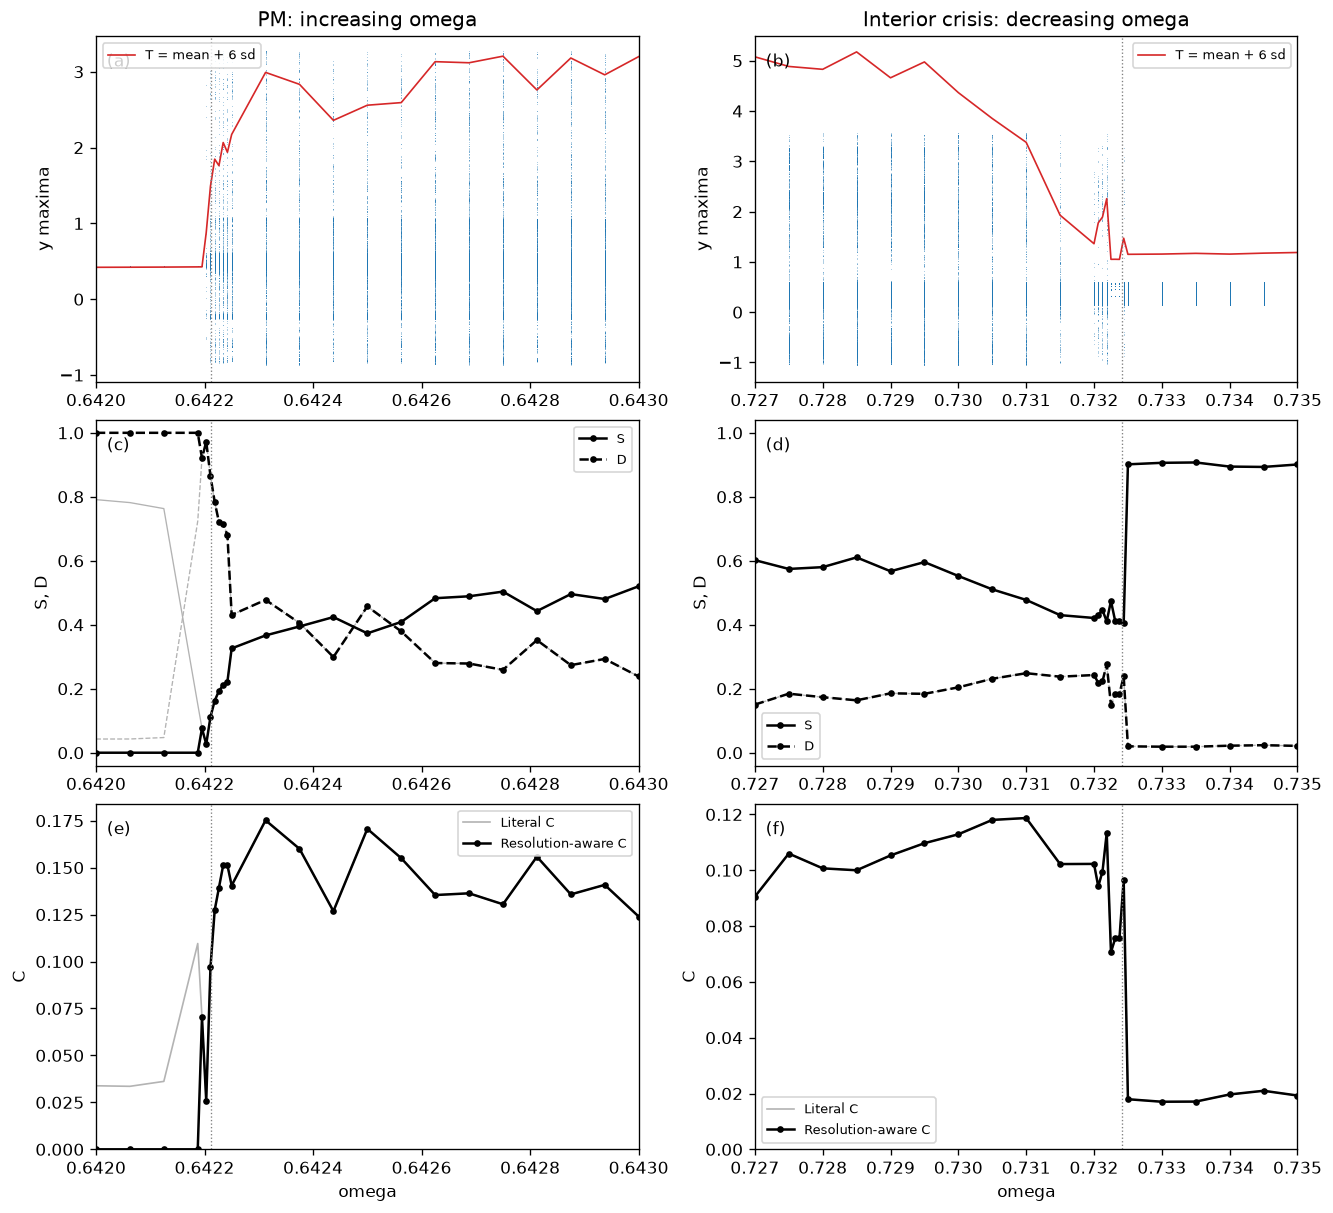

In [34]:
def plot_lienard_figure(pm_records, crisis_records):
    """Draw Fig. 1, keeping literal estimates visible."""
    fig, axes = plt.subplots(3, 2, figsize=(11, 10), layout="constrained")
    for col, (records, title, reference) in enumerate(
        (
            (pm_records, "PM: increasing omega", 0.642212),
            (crisis_records, "Interior crisis: decreasing omega", 0.73242),
        )
    ):
        parameters = np.array(sorted(records))
        stats, literal = [], []
        for omega in parameters:
            peaks = records[omega]["extrema"]
            stats.append(
                peak_statistics(
                    peaks,
                    LIENARD_SETTINGS["duration"],
                    resolution=AMPLITUDE_RESOLUTION,
                )
            )
            literal.append(complexity_measures(amplitude_histogram(peaks)[0]))
            axes[0, col].plot(
                np.full(peaks.size, omega),
                peaks,
                ",",
                color="tab:blue",
                alpha=0.35,
            )
        literal = np.asarray(literal)
        axes[0, col].plot(
            parameters,
            [s["threshold"] for s in stats],
            color="tab:red",
            lw=1,
            label="T = mean + 6 sd",
        )
        axes[0, col].set(title=title, ylabel="y maxima")
        axes[0, col].legend(fontsize=8)
        axes[1, col].plot(parameters, literal[:, 0], color="0.7", lw=0.8)
        axes[1, col].plot(
            parameters, literal[:, 1], color="0.7", lw=0.8, ls="--"
        )
        axes[1, col].plot(
            parameters, [s["s"] for s in stats], "k.-", label="S"
        )
        axes[1, col].plot(
            parameters, [s["d"] for s in stats], "k.--", label="D"
        )
        axes[1, col].set(ylabel="S, D", ylim=(-0.04, 1.04))
        axes[1, col].legend(fontsize=8)
        axes[2, col].plot(
            parameters, literal[:, 2], color="0.7", lw=1, label="Literal C"
        )
        axes[2, col].plot(
            parameters,
            [s["c"] for s in stats],
            "k.-",
            label="Resolution-aware C",
        )
        axes[2, col].set(xlabel="omega", ylabel="C", ylim=(0, None))
        axes[2, col].legend(fontsize=8)
        for row in range(3):
            axes[row, col].axvline(reference, color="0.5", ls=":", lw=0.8)
            axes[row, col].ticklabel_format(axis="x", useOffset=False)
            axes[row, col].set_xlim(parameters[0], parameters[-1])
            panel = "abcdef"[2 * row + col]
            axes[row, col].text(
                0.02,
                0.95,
                f"({panel})",
                transform=axes[row, col].transAxes,
                va="top",
            )
    plt.show()


plot_lienard_figure(pm_sweep, crisis_sweep)

**Figure:** Fig. 1(a–f), including literal estimates for comparison.
**Observation:** both routes show broad attractor expansion and a rise then fall
of C, but the independent-start fine grid also contains a pre-onset drift artifact
and a narrow bounded interval on the crisis branch.
**Scientific meaning:** S responds differently across the two routes, while C
combines spread and concentration; sharp changes also require transient and
resolution checks before receiving a dynamical interpretation.
**Reproduction status:** **partially reproduced**; the observed brackets do not
contain the printed transition values, and the curves remain less smooth than
the published results under the declared finite-record protocol.

In [35]:
trend_rows, sparse_rows = [], []
for label, records, decreasing in (
    ("PM", pm_sweep, False),
    ("Crisis", crisis_sweep, True),
):
    parameters = sorted(records, reverse=decreasing)
    stats = [
        peak_statistics(
            records[p]["extrema"],
            LIENARD_SETTINGS["duration"],
            resolution=AMPLITUDE_RESOLUTION,
        )
        for p in parameters
    ]
    c = np.array([s["c"] for s in stats])
    maximum = int(np.argmax(c))
    trend_rows.append(
        [
            label,
            len(parameters),
            sum(s["n"] for s in stats),
            f"{c[0]:.5f}",
            f"{c[maximum]:.5f}",
            f"{parameters[maximum]:.8f}",
            f"{c[-1]:.5f}",
            f"{c[maximum] - c[-1]:.5f}",
        ]
    )
    for p, summary in zip(parameters, stats, strict=True):
        if 0 < summary["count"] < 20:
            sparse_rows.append(
                [
                    label,
                    f"{p:.8f}",
                    summary["count"],
                    f"{1_000 * summary['rate']:.3f}",
                ]
            )
show_table(
    [
        "Route",
        "Conditions",
        "Total maxima",
        "Start C",
        "Max C",
        "omega at max",
        "End C",
        "Max minus end",
    ],
    trend_rows,
)
show_table(
    ["Route", "omega", "Sparse threshold crossings (<20)", "Rate / 1000 t"],
    sparse_rows,
)
print("Zero-count conditions do not establish absence of rare extremes.")
print("Positive max-minus-end supports a decline only over this sampled grid.")

| Route | Conditions | Total maxima | Start C | Max C | omega at max | End C | Max minus end |
|---|---|---|---|---|---|---|---|
| PM | 24 | 129149 | -0.00000 | 0.17520 | 0.64231250 | 0.12396 | 0.05123 |
| Crisis | 24 | 145171 | 0.01928 | 0.11872 | 0.73100000 | 0.09052 | 0.02819 |

| Route | omega | Sparse threshold crossings (<20) | Rate / 1000 t |
|---|---|---|---|
| PM | 0.64220312 | 10 | 0.200 |
| PM | 0.64262500 | 6 | 0.120 |
| PM | 0.64268750 | 13 | 0.260 |
| PM | 0.64275000 | 7 | 0.140 |
| PM | 0.64287500 | 7 | 0.140 |
| PM | 0.64293750 | 18 | 0.360 |
| PM | 0.64300000 | 2 | 0.040 |
| Crisis | 0.73243750 | 16 | 0.320 |
| Crisis | 0.73200000 | 13 | 0.260 |

Zero-count conditions do not establish absence of rare extremes.
Positive max-minus-end supports a decline only over this sampled grid.


## 9. Stage C — Figure 2: four fixed Liénard conditions

Use exactly ω = 0.642236, 0.643, 0.731693, and 0.73007. The two Phase 1
extreme-event records are reused without changing their initial conditions;
the two frequent-large-event conditions use the same settings. Statistical
estimates use the full **50,000** retained time units. All display segments are
fixed in advance at **t = 5,000–20,000**, as in the published temporal range;
segments are never shifted to select a favorable burst.

PDF heights are probabilities divided by their bin widths and integrate to one;
S, D, C use bin probabilities, not density heights. Negative local maxima are
retained: the paper's displayed PDF axes do not show that support, but no positive-
height filter is specified in Section II. This is a possible display/protocol
mismatch, not a reason to remove extrema. The marker is estimated from the full
peak record, independently of the plotted segment and complexity calculation.

In [36]:
figure2 = []
for label, omega, phase1_name in (
    ("PM: rare extremes", 0.642236, "pm"),
    ("PM: frequent large events", 0.643, None),
    ("Crisis: rare extremes", 0.731693, "crisis"),
    ("Crisis: frequent large events", 0.73007, None),
):
    if phase1_name:
        source = results[phase1_name]
        window = source["time"] <= 20_000
        record = {
            "extrema_time": source["peak_time"],
            "extrema": source["peaks"],
            "trace_time": source["time"][window],
            "trace_y": source["state"][1, window],
        }
    else:
        settings = {**LIENARD_SETTINGS, "trace_duration": 15_000.0}
        record = cached_simulation("lienard", omega, settings)
    stats = peak_statistics(
        record["extrema"],
        LIENARD_SETTINGS["duration"],
        resolution=AMPLITUDE_RESOLUTION,
    )
    figure2.append(
        {"label": label, "parameter": omega, "record": record, "stats": stats}
    )
show_table(
    [
        "Condition",
        "omega",
        "Duration",
        "Maxima",
        "S",
        "D",
        "C",
        "T",
        "Peaks > T",
        "Rate / 1000 t",
    ],
    [
        [
            item["label"],
            item["parameter"],
            50_000,
            item["stats"]["n"],
            *(
                f"{item['stats'][key]:.5f}"
                for key in ("s", "d", "c", "threshold")
            ),
            item["stats"]["count"],
            f"{1_000 * item['stats']['rate']:.3f}",
        ]
        for item in figure2
    ],
)

| Condition | omega | Duration | Maxima | S | D | C | T | Peaks > T | Rate / 1000 t |
|---|---|---|---|---|---|---|---|---|---|
| PM: rare extremes | 0.642236 | 50000 | 5319 | 0.28410 | 0.55294 | 0.15709 | 2.19448 | 42 | 0.840 |
| PM: frequent large events | 0.643 | 50000 | 5702 | 0.52031 | 0.23825 | 0.12396 | 3.19942 | 2 | 0.040 |
| Crisis: rare extremes | 0.731693 | 50000 | 5872 | 0.42588 | 0.23082 | 0.09830 | 1.70051 | 29 | 0.580 |
| Crisis: frequent large events | 0.73007 | 50000 | 6356 | 0.55556 | 0.20954 | 0.11641 | 4.48528 | 0 | 0.000 |

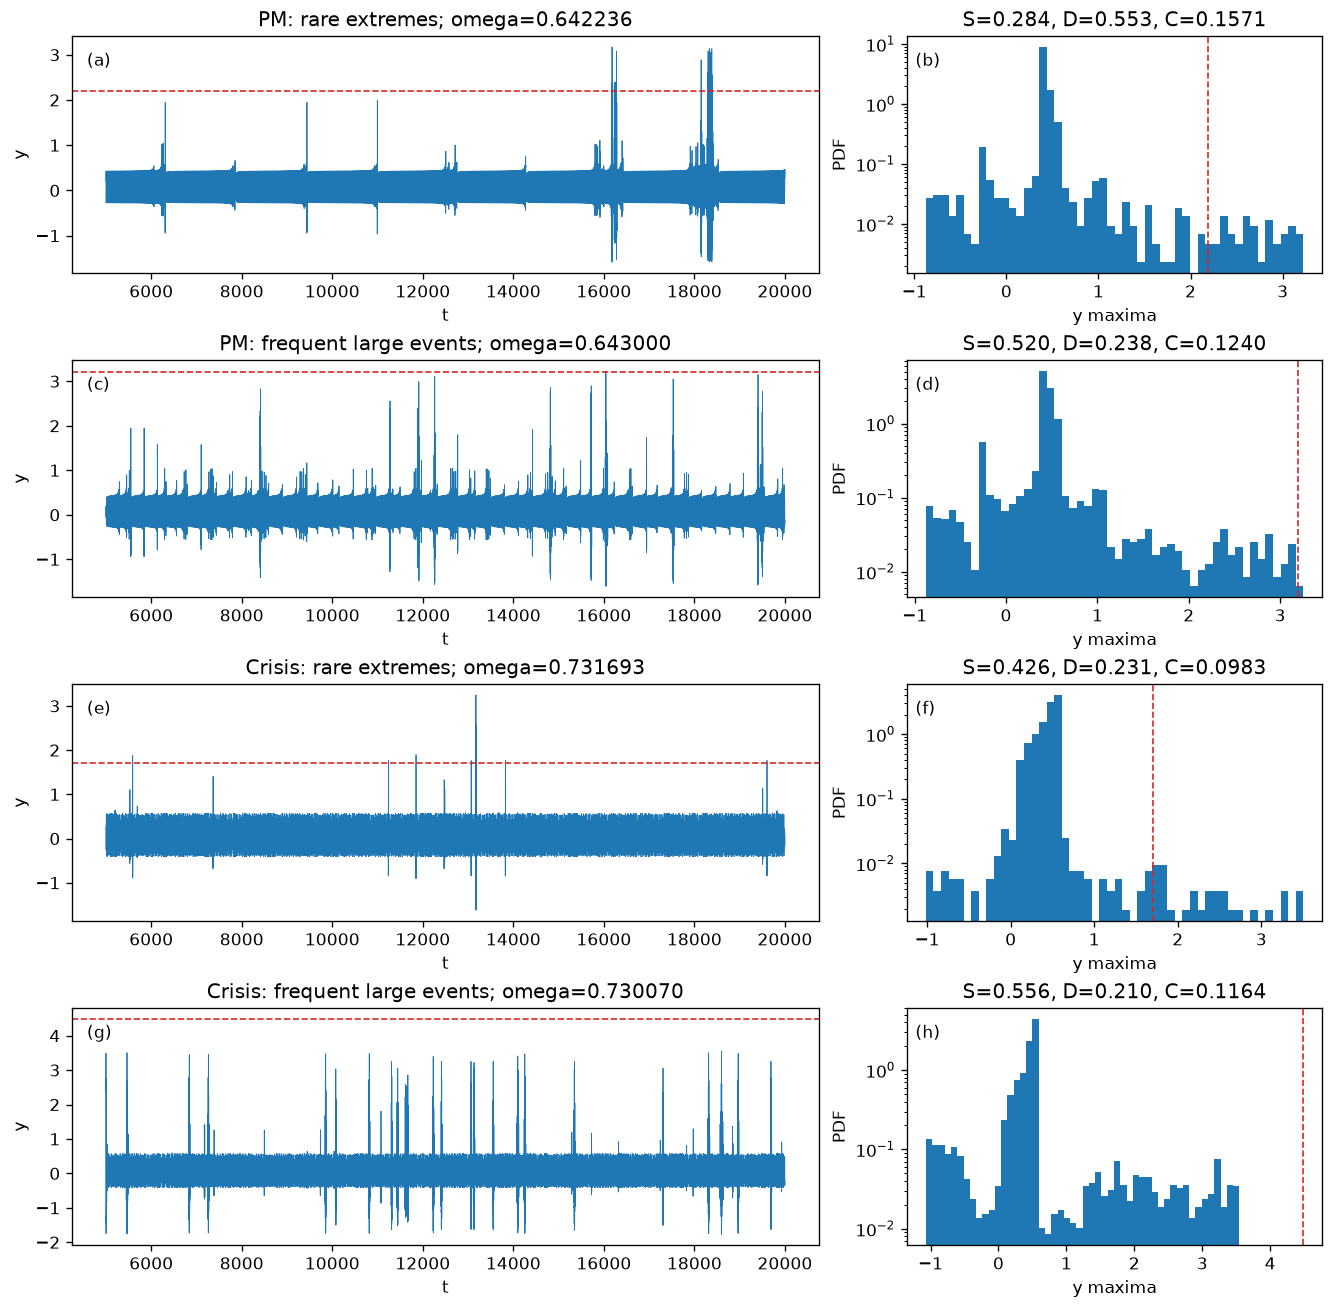

In [37]:
def plot_temporal_pdfs(conditions, parameter_name, time_label):
    """Draw fixed temporal segments alongside full-record peak densities."""
    fig, axes = plt.subplots(
        len(conditions),
        2,
        figsize=(11, 2.7 * len(conditions)),
        width_ratios=(1.8, 1),
        layout="constrained",
    )
    for row, item in enumerate(conditions):
        record, stats = item["record"], item["stats"]
        axes[row, 0].plot(
            record["trace_time"], record["trace_y"], color="tab:blue", lw=0.5
        )
        axes[row, 0].axhline(
            stats["threshold"], color="tab:red", ls="--", lw=1
        )
        axes[row, 0].set(
            xlabel=time_label,
            ylabel="y",
            title=f"{item['label']}; {parameter_name}={item['parameter']:.6f}",
        )
        widths = np.diff(stats["edges"])
        centers = stats["edges"][:-1] + widths / 2
        occupied = stats["probabilities"] > 0
        density = stats["probabilities"] / widths
        np.testing.assert_allclose(np.sum(density * widths), 1.0)
        axes[row, 1].bar(
            centers[occupied], density[occupied], width=widths[occupied]
        )
        axes[row, 1].axvline(
            stats["threshold"], color="tab:red", ls="--", lw=1
        )
        axes[row, 1].set(
            xlabel="y minima" if parameter_name == "p" else "y maxima",
            ylabel="PDF",
            yscale="log",
            title=(
                f"S={stats['s']:.3f}, D={stats['d']:.3f}, C={stats['c']:.4f}"
            ),
        )
        for col in range(2):
            axes[row, col].text(
                0.02,
                0.93,
                f"({'abcdefgh'[2 * row + col]})",
                transform=axes[row, col].transAxes,
                va="top",
            )
    plt.show()


plot_temporal_pdfs(figure2, "omega", "t")

**Figure:** Fig. 2(a–h), with fixed segments and full-record PDFs.
**Observation:** the two rare-event conditions have 42 and 29 threshold crossings;
ω = 0.643 has 2 rather than zero, and ω = 0.73007 has none in the full records.
**Scientific meaning:** PM C decreases from 0.1571 to 0.1240 between the selected
conditions, whereas the crisis pair gives 0.0983 and 0.1164, so these four records
do not establish a universal ordering of rare versus frequent-event complexity.
**Reproduction status:** **partially reproduced**; representative regimes are
visible, but finite statistics, negative-peak support, and absolute distributions
differ from the published panels.

## 10. Stage D — Ikeda map, Eqs. (5)–(6)

With zₙ = xₙ + i yₙ and wₙ = 1 + xₙ² + yₙ²,
\[
 z_{n+1}=A+Bz_n\exp\!\left[i\left(k-\frac{p}{1+|z_n|^2}\right)\right],
\]
\[
 x_{n+1}=A+B[x_n\cos\theta_n-y_n\sin\theta_n],\qquad
 y_{n+1}=B[x_n\sin\theta_n+y_n\cos\theta_n],\quad
 \theta_n=k-p/w_n.
\]
Reported parameters: A = 0.85, B = 0.9, k = 0.4; control parameter p.
The published crisis is near p_c = 7.26884894. The map uses **local minima of y**
and **T = μ − 5σ** (Section III.B), with σ from all retained minima and ddof = 0.
It has no time integrator or event interpolation: extrema are neighboring-iterate
comparisons on the discrete y sequence.

Implementation assumptions: independent (x₀, y₀) = (0, 0), discard 5,000 iterates,
retain 200,000 for the main sweep, and use m = 50 with literal min–max bins.
No Liénard amplitude-resolution correction is applied to these chaotic map
records. The first 2,500 retained iterates are displayed without downsampling,
matching the published approximate n = 5,000–7,500 range.

In [38]:
from math import cos, sin

IKEDA = {"a": 0.85, "b": 0.9, "k": 0.4}
IKEDA_SETTINGS = {
    "initial_state": (0.0, 0.0),
    "transient": 5_000,
    "retained": 200_000,
    "trace_length": 2_500,
}
IKEDA_PC = 7.26884894


def ikeda_real(state, p):
    """Real-valued Ikeda map, Eq. (6)."""
    x, y = state
    theta = IKEDA["k"] - p / (1 + x * x + y * y)
    cosine, sine = cos(theta), sin(theta)
    return (
        IKEDA["a"] + IKEDA["b"] * (x * cosine - y * sine),
        IKEDA["b"] * (x * sine + y * cosine),
    )


def ikeda_complex(z, p):
    """Complex-valued Ikeda map, Eq. (5), used for verification."""
    theta = IKEDA["k"] - p / (1 + abs(z) ** 2)
    return IKEDA["a"] + IKEDA["b"] * z * np.exp(1j * theta)

In [39]:
for p in (7.265, IKEDA_PC, 7.295):
    for state in ((0.0, 0.0), (-1.0, 0.25), (0.4, -0.8), (1.2, 0.7)):
        real = ikeda_real(state, p)
        complex_value = ikeda_complex(complex(*state), p)
        np.testing.assert_allclose(
            real,
            (complex_value.real, complex_value.imag),
            rtol=1e-13,
            atol=1e-13,
        )
real_state, complex_state = (0.2, -0.1), complex(0.2, -0.1)
for _ in range(12):
    real_state = ikeda_real(real_state, 7.275)
    complex_state = ikeda_complex(complex_state, 7.275)
    np.testing.assert_allclose(
        real_state,
        (complex_state.real, complex_state.imag),
        rtol=1e-10,
        atol=1e-10,
    )
print("Real/complex one-step and short-trajectory equivalence passed.")

Real/complex one-step and short-trajectory equivalence passed.


In [40]:
def run_ikeda(p, settings):
    """Discard transient iterates and extract retained local y minima."""
    start = perf_counter()
    state = settings["initial_state"]
    for _ in range(settings["transient"]):
        state = ikeda_real(state, p)
    values = np.empty(settings["retained"])
    for index in range(settings["retained"]):
        state = ikeda_real(state, p)
        values[index] = state[1]
    if not np.all(np.isfinite(values)):
        raise RuntimeError(f"Nonfinite Ikeda trajectory at p={p}.")
    iterations = settings["transient"] + 1 + np.arange(values.size)
    extrema_time, extrema = local_extrema(iterations, values, kind="min")
    display_length = settings["trace_length"]
    return {
        "extrema_time": extrema_time,
        "extrema": extrema,
        "trace_time": iterations[:display_length],
        "trace_y": values[:display_length],
        "seconds": np.array(perf_counter() - start),
    }


ikeda_examples = {
    p: cached_simulation("ikeda", p, IKEDA_SETTINGS)
    for p in (7.265, 7.275, 7.295)
}
show_table(
    [
        "p",
        "Retained iterates",
        "Minima",
        "Lowest minimum",
        "S",
        "D",
        "C",
        "T",
        "Minima < T",
        "Rate / 1000 iterates",
    ],
    [
        [
            p,
            IKEDA_SETTINGS["retained"],
            record["extrema"].size,
            f"{record['extrema'].min():.6f}",
            *(f"{stats[key]:.6f}" for key in ("s", "d", "c", "threshold")),
            stats["count"],
            f"{1_000 * stats['rate']:.3f}",
        ]
        for p, record in ikeda_examples.items()
        for stats in [
            peak_statistics(
                record["extrema"], IKEDA_SETTINGS["retained"], lower_tail=True
            )
        ]
    ],
)

| p | Retained iterates | Minima | Lowest minimum | S | D | C | T | Minima < T | Rate / 1000 iterates |
|---|---|---|---|---|---|---|---|---|---|
| 7.265 | 200000 | 60461 | -0.416244 | 0.947389 | 0.008352 | 0.007912 | -1.123853 | 0 | 0.000 |
| 7.275 | 200000 | 60753 | -1.418953 | 0.754384 | 0.041970 | 0.031662 | -1.165169 | 67 | 0.335 |
| 7.295 | 200000 | 62175 | -1.428214 | 0.801634 | 0.034482 | 0.027642 | -1.499887 | 0 | 0.000 |

## 11. Stage E — Figure 3: Ikeda coarse-to-fine sweep

Start with 21 equally spaced p values over [7.25, 7.30], the displayed Fig. 3
range. After inspecting its finite-record expansion brackets, refine each bracket
three times with nine points per level. The diagnostic expansion flag min(y minima)
< −0.8 separates the pre-crisis bounded support (about −0.4) from the far negative
excursions (about −1.4); it does **not** replace T = μ − 5σ or enter C.
The map is interpreted toward increasing p. Every main-grid record has the same
200,000 retained iterates; longer targeted checks below are reported separately
and never mixed into this curve as if all conditions had the same record length.

In [41]:
ikeda_coarse = run_sweep("ikeda", np.linspace(7.25, 7.30, 21), IKEDA_SETTINGS)
print(
    "Ikeda coarse expansion brackets:",
    expansion_brackets(ikeda_coarse, "ikeda"),
)
rows = []
for p, record in sorted(ikeda_coarse.items()):
    stats = peak_statistics(
        record["extrema"], IKEDA_SETTINGS["retained"], lower_tail=True
    )
    rows.append(
        [f"{p:.7f}", f"{record['extrema'].min():.5f}", f"{stats['c']:.6f}"]
    )
show_table(["p", "Lowest minimum", "C"], rows)

ikeda sweep 1/21: 7.250000000; 59667 extrema; C=0.00792; 0 threshold crossings


ikeda sweep 2/21: 7.252500000; 59746 extrema; C=0.00789; 0 threshold crossings


ikeda sweep 3/21: 7.255000000; 59820 extrema; C=0.00793; 0 threshold crossings


ikeda sweep 4/21: 7.257500000; 60126 extrema; C=0.00797; 0 threshold crossings


ikeda sweep 5/21: 7.260000000; 60373 extrema; C=0.00769; 0 threshold crossings


...

ikeda sweep 19/21: 7.295000000; 62175 extrema; C=0.02764; 0 threshold crossings


ikeda sweep 20/21: 7.297500000; 62135 extrema; C=0.02744; 0 threshold crossings


ikeda sweep 21/21: 7.300000000; 62168 extrema; C=0.02739; 0 threshold crossings


Ikeda coarse expansion brackets: [(7.2675, 7.27)]


| p | Lowest minimum | C |
|---|---|---|
| 7.2500000 | -0.41676 | 0.007922 |
| 7.2525000 | -0.41652 | 0.007892 |
| 7.2550000 | -0.41656 | 0.007925 |
| 7.2575000 | -0.41637 | 0.007973 |
| 7.2600000 | -0.41645 | 0.007687 |
| 7.2625000 | -0.41603 | 0.007488 |
| 7.2650000 | -0.41624 | 0.007912 |
| 7.2675000 | -0.41645 | 0.008021 |
| 7.2700000 | -1.41173 | 0.031063 |
| 7.2725000 | -1.41922 | 0.031517 |
| 7.2750000 | -1.41895 | 0.031662 |
| 7.2775000 | -1.42760 | 0.031814 |
| 7.2800000 | -1.42189 | 0.031518 |
| 7.2825000 | -1.42605 | 0.031144 |
| 7.2850000 | -1.42692 | 0.030707 |
| 7.2875000 | -1.42226 | 0.029951 |
| 7.2900000 | -1.42805 | 0.029255 |
| 7.2925000 | -1.42839 | 0.028543 |
| 7.2950000 | -1.42821 | 0.027642 |
| 7.2975000 | -1.42982 | 0.027439 |
| 7.3000000 | -1.42991 | 0.027387 |

In [42]:
ikeda_sweep = dict(ikeda_coarse)
for level in range(3):
    print(f"Ikeda refinement level {level + 1}")
    ikeda_sweep = refine_sweep("ikeda", ikeda_sweep, IKEDA_SETTINGS)
transition_brackets["Ikeda"] = report_brackets(
    "Ikeda", ikeda_sweep, "ikeda", IKEDA_PC
)

Ikeda refinement level 1


ikeda sweep 1/9: 7.267500000; 60359 extrema; C=0.00802; 0 threshold crossings


ikeda sweep 2/9: 7.267812500; 60264 extrema; C=0.00804; 0 threshold crossings


ikeda sweep 3/9: 7.268125000; 60346 extrema; C=0.00765; 0 threshold crossings


ikeda sweep 4/9: 7.268437500; 60117 extrema; C=0.00805; 0 threshold crossings


...

ikeda sweep 24/27: 7.269321289; 60248 extrema; C=0.02927; 1 threshold crossings


ikeda sweep 25/27: 7.269326172; 60268 extrema; C=0.03077; 12 threshold crossings


ikeda sweep 26/27: 7.269331055; 60215 extrema; C=0.00811; 0 threshold crossings


ikeda sweep 27/27: 7.269335938; 60289 extrema; C=0.02999; 18 threshold crossings


| Route | Lower | Upper | Width | Midpoint - paper | Paper inside? |
|---|---|---|---|---|---|
| Ikeda | 7.2690625000 | 7.2690673828 | 4.883e-06 | +2.160e-04 | False |
| Ikeda | 7.2690966797 | 7.2691015625 | 4.883e-06 | +2.502e-04 | False |
| Ikeda | 7.2691796875 | 7.2691845703 | 4.883e-06 | +3.332e-04 | False |
| Ikeda | 7.2692041016 | 7.2692089844 | 4.883e-06 | +3.576e-04 | False |
| Ikeda | 7.2692968750 | 7.2693017578 | 4.883e-06 | +4.504e-04 | False |
| Ikeda | 7.2693310547 | 7.2693359375 | 4.883e-06 | +4.846e-04 | False |

### 11.1 Figure 3(a,b) — Bifurcation support and complexity

The top panel uses every local minimum, with the lower-tail marker calculated
separately at each p. The bottom panel uses the identical 50-bin complexity
estimator as the Liénard model. The vertical line marks the reported crisis;
the transition comparison table gives the independent finite-record bracket.

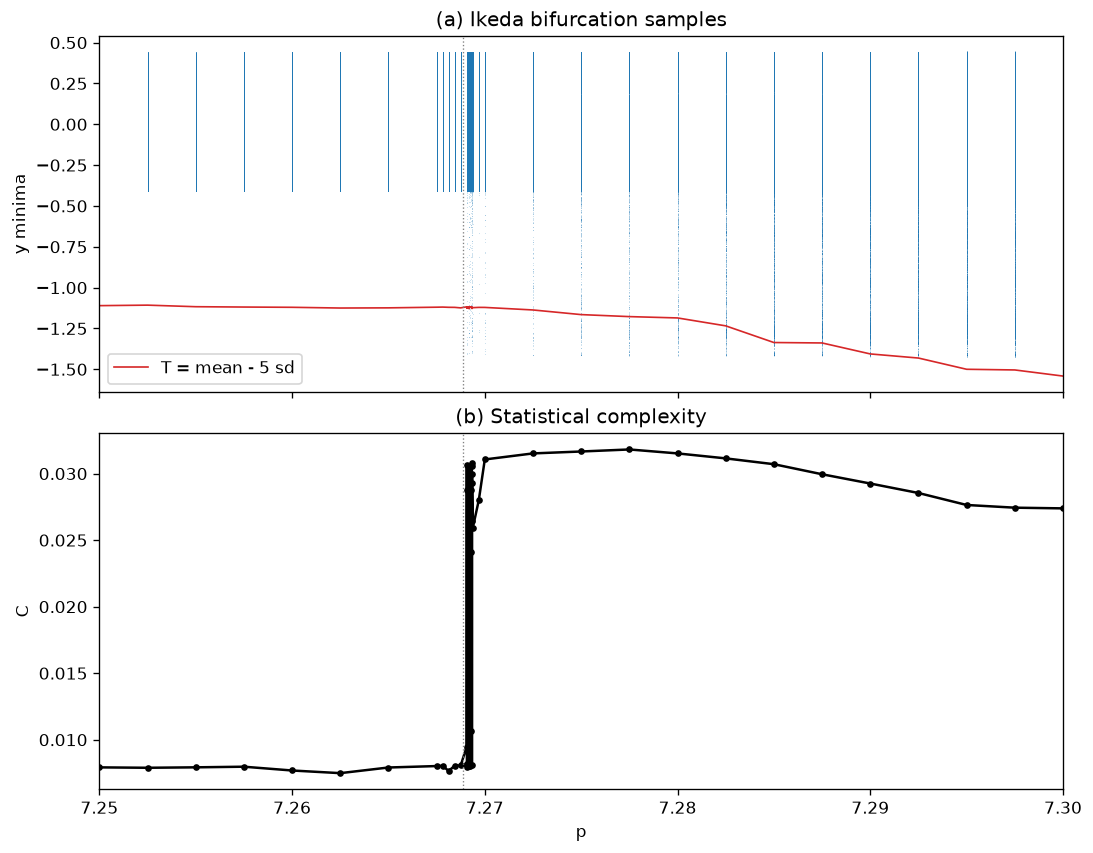

In [43]:
fig, axes = plt.subplots(
    2, 1, figsize=(9, 7), sharex=True, layout="constrained"
)
ikeda_parameters = np.array(sorted(ikeda_sweep))
ikeda_stats = []
for p in ikeda_parameters:
    peaks = ikeda_sweep[p]["extrema"]
    stats = peak_statistics(peaks, IKEDA_SETTINGS["retained"], lower_tail=True)
    ikeda_stats.append(stats)
    axes[0].plot(
        np.full(peaks.size, p), peaks, ",", color="tab:blue", alpha=0.22
    )
axes[0].plot(
    ikeda_parameters,
    [s["threshold"] for s in ikeda_stats],
    color="tab:red",
    lw=1,
    label="T = mean - 5 sd",
)
axes[0].set(ylabel="y minima", title="(a) Ikeda bifurcation samples")
axes[0].legend()
axes[1].plot(ikeda_parameters, [s["c"] for s in ikeda_stats], "k.-")
axes[1].set(xlabel="p", ylabel="C", title="(b) Statistical complexity")
for ax in axes:
    ax.axvline(IKEDA_PC, color="0.5", ls=":", lw=0.8)
    ax.set_xlim(7.25, 7.30)
plt.show()

**Figure:** Fig. 3(a,b).
**Observation:** the coarse curve rises from about 0.008 to 0.032 and then falls,
but fine records near the crisis alternate between detected and undetected
negative excursions instead of giving one stable transition bracket.
**Scientific meaning:** one newly sampled tail event can substantially change
min–max bins and C, so a narrow parameter mesh cannot compensate for an
insufficient observation length.
**Reproduction status:** **partially reproduced**; the broad trend agrees
qualitatively, while the reported p_c = 7.26884894 is not quantitatively located
by the main finite-record sweep or the longer check below.

### 11.2 Ikeda record length, initial states, and transient checks

For each Fig. 4 condition, compare nested 50,000 / 200,000 / 500,000-iterate
records with the same fixed initial state. Repeat p = 7.275 from two additional
initial states and with a longer discarded transient. These tests assess whether
the rare-tail signature and complexity persist; event counts remain correlated
and are not treated as independent Poisson samples.

In [44]:
ikeda_length_rows, ikeda_initial_rows = [], []
for p in (7.265, 7.275, 7.295):
    settings = {**IKEDA_SETTINGS, "retained": 500_000}
    record = cached_simulation("ikeda", p, settings)
    full_edges = amplitude_histogram(record["extrema"])[1]
    full_p = np.histogram(record["extrema"], bins=full_edges)[0]
    full_p = full_p / full_p.sum()
    for length in (50_000, 200_000, 500_000):
        keep = record["extrema_time"] < settings["transient"] + length
        peaks = record["extrema"][keep]
        stats = peak_statistics(peaks, length, lower_tail=True)
        common_p = np.histogram(peaks, bins=full_edges)[0] / peaks.size
        variation = 0.5 * np.sum(np.abs(common_p - full_p))
        ikeda_length_rows.append(
            [
                p,
                length,
                stats["n"],
                f"{stats['s']:.5f}",
                f"{stats['d']:.5f}",
                f"{stats['c']:.5f}",
                stats["count"],
                f"{1_000 * stats['rate']:.3f}",
                f"{variation:.4f}",
            ]
        )
for initial, transient in (
    ((0.0, 0.0), 5_000),
    ((1.0, 1.0), 5_000),
    ((-1.0, 0.0), 5_000),
    ((0.0, 0.0), 20_000),
):
    settings = {
        **IKEDA_SETTINGS,
        "initial_state": initial,
        "transient": transient,
    }
    record = cached_simulation("ikeda", 7.275, settings)
    stats = peak_statistics(
        record["extrema"], settings["retained"], lower_tail=True
    )
    ikeda_initial_rows.append(
        [
            str(initial),
            transient,
            stats["n"],
            f"{stats['c']:.6f}",
            stats["count"],
            f"{1_000 * stats['rate']:.3f}",
        ]
    )
show_table(
    [
        "p",
        "Retained",
        "Minima",
        "S",
        "D",
        "C",
        "Minima < own T",
        "Rate / 1000",
        "Common-bin TV",
    ],
    ikeda_length_rows,
)
show_table(
    ["Initial state", "Discarded", "Minima", "C", "Minima < T", "Rate / 1000"],
    ikeda_initial_rows,
)

| p | Retained | Minima | S | D | C | Minima < own T | Rate / 1000 | Common-bin TV |
|---|---|---|---|---|---|---|---|---|
| 7.265 | 50000 | 15103 | 0.94643 | 0.00850 | 0.00805 | 0 | 0.000 | 0.0227 |
| 7.265 | 200000 | 60461 | 0.94739 | 0.00835 | 0.00791 | 0 | 0.000 | 0.0078 |
| 7.265 | 500000 | 150997 | 0.94659 | 0.00843 | 0.00798 | 0 | 0.000 | 0.0000 |
| 7.275 | 50000 | 15212 | 0.75258 | 0.04218 | 0.03174 | 16 | 0.320 | 0.0126 |
| 7.275 | 200000 | 60753 | 0.75438 | 0.04197 | 0.03166 | 67 | 0.335 | 0.0042 |
| 7.275 | 500000 | 152157 | 0.75362 | 0.04200 | 0.03165 | 161 | 0.322 | 0.0000 |
| 7.295 | 50000 | 15517 | 0.79965 | 0.03498 | 0.02797 | 0 | 0.000 | 0.0158 |
| 7.295 | 200000 | 62175 | 0.80163 | 0.03448 | 0.02764 | 0 | 0.000 | 0.0072 |
| 7.295 | 500000 | 155801 | 0.80298 | 0.03440 | 0.02763 | 0 | 0.000 | 0.0000 |

| Initial state | Discarded | Minima | C | Minima < T | Rate / 1000 |
|---|---|---|---|---|---|
| (0.0, 0.0) | 5000 | 60753 | 0.031662 | 67 | 0.335 |
| (1.0, 1.0) | 5000 | 61011 | 0.031352 | 44 | 0.220 |
| (-1.0, 0.0) | 5000 | 60934 | 0.031632 | 49 | 0.245 |
| (0.0, 0.0) | 20000 | 60701 | 0.031678 | 56 | 0.280 |

### 11.3 Longer targeted observations near the reported map crisis

At p_c ± 10⁻⁵ and p_c ± 10⁻⁶, retain 2,000,000 iterates each from the same
(0, 0) start. This explicitly tests finite-record detection near the literature
location; it is not an independent derivation of all eight decimal places.
Report the lowest minimum, lower-tail threshold crossings, and the auxiliary
expansion flag even if no extreme is detected. These longer records are kept
separate from the equal-length main sweep.

**Observed limitation:** the main-grid flags alternate near p ≈ 7.2691–7.2693.
These candidate intervals are not interpreted as multiple physical crises.
At 2,000,000 retained iterates, no large excursion is seen at p_c + 10⁻⁶, and
only one threshold-crossing minimum is seen at p_c + 10⁻⁵. Absence over a finite
record is not evidence that the attractor cannot expand there. The table reports
this lack of rare-tail sampling without shifting the model parameters.


In [45]:
ikeda_near_records = {}
near_rows = []
for offset in (-1e-5, -1e-6, 1e-6, 1e-5):
    p = IKEDA_PC + offset
    settings = {**IKEDA_SETTINGS, "retained": 2_000_000}
    record = cached_simulation("ikeda", p, settings)
    ikeda_near_records[p] = record
    stats = peak_statistics(
        record["extrema"], settings["retained"], lower_tail=True
    )
    near_rows.append(
        [
            f"{p:.8f}",
            f"{offset:+.0e}",
            settings["retained"],
            stats["n"],
            f"{record['extrema'].min():.6f}",
            str(record["extrema"].min() < -0.8),
            f"{stats['c']:.6f}",
            stats["count"],
            f"{1_000 * stats['rate']:.5f}",
        ]
    )
show_table(
    [
        "p",
        "p - paper pc",
        "Retained",
        "Minima",
        "Lowest minimum",
        "Expanded?",
        "C",
        "Minima < T",
        "Rate / 1000",
    ],
    near_rows,
)
transition_brackets["Ikeda long check"] = report_brackets(
    "Ikeda long check", ikeda_near_records, "ikeda", IKEDA_PC
)

| p | p - paper pc | Retained | Minima | Lowest minimum | Expanded? | C | Minima < T | Rate / 1000 |
|---|---|---|---|---|---|---|---|---|
| 7.26883894 | -1e-05 | 2000000 | 602394 | -0.416381 | False | 0.008102 | 0 | 0.00000 |
| 7.26884794 | -1e-06 | 2000000 | 602459 | -0.416396 | False | 0.008142 | 0 | 0.00000 |
| 7.26884994 | +1e-06 | 2000000 | 602862 | -0.416408 | False | 0.008018 | 0 | 0.00000 |
| 7.26885894 | +1e-05 | 2000000 | 602704 | -1.159796 | True | 0.025769 | 1 | 0.00050 |

| Route | Lower | Upper | Width | Midpoint - paper | Paper inside? |
|---|---|---|---|---|---|
| Ikeda long check | 7.2688499400 | 7.2688589400 | 9.000e-06 | +5.500e-06 | False |

## 12. Stage F — Figure 4: fixed Ikeda trajectories and minima PDFs

Use exactly p = 7.265 (bounded chaos), 7.275 (rare extreme excursions), and
7.295 (frequent large excursions). Display the first 2,500 retained iterates,
fixed before inspecting bursts. Each PDF and S, D, C uses all 200,000 retained
iterates through their local minima; T = μ − 5σ is estimated from those same
minima, independently of complexity. The map's discrete minima are not replaced
with continuous-time event interpolation.

| p | Display start | Display end | Shown minima < full T | Full minima < T | Shown minima < -0.8 |
|---|---|---|---|---|---|
| 7.265 | 5001 | 7500 | 0 | 0 | 0 |
| 7.275 | 5001 | 7500 | 0 | 67 | 0 |
| 7.295 | 5001 | 7500 | 0 | 0 | 20 |

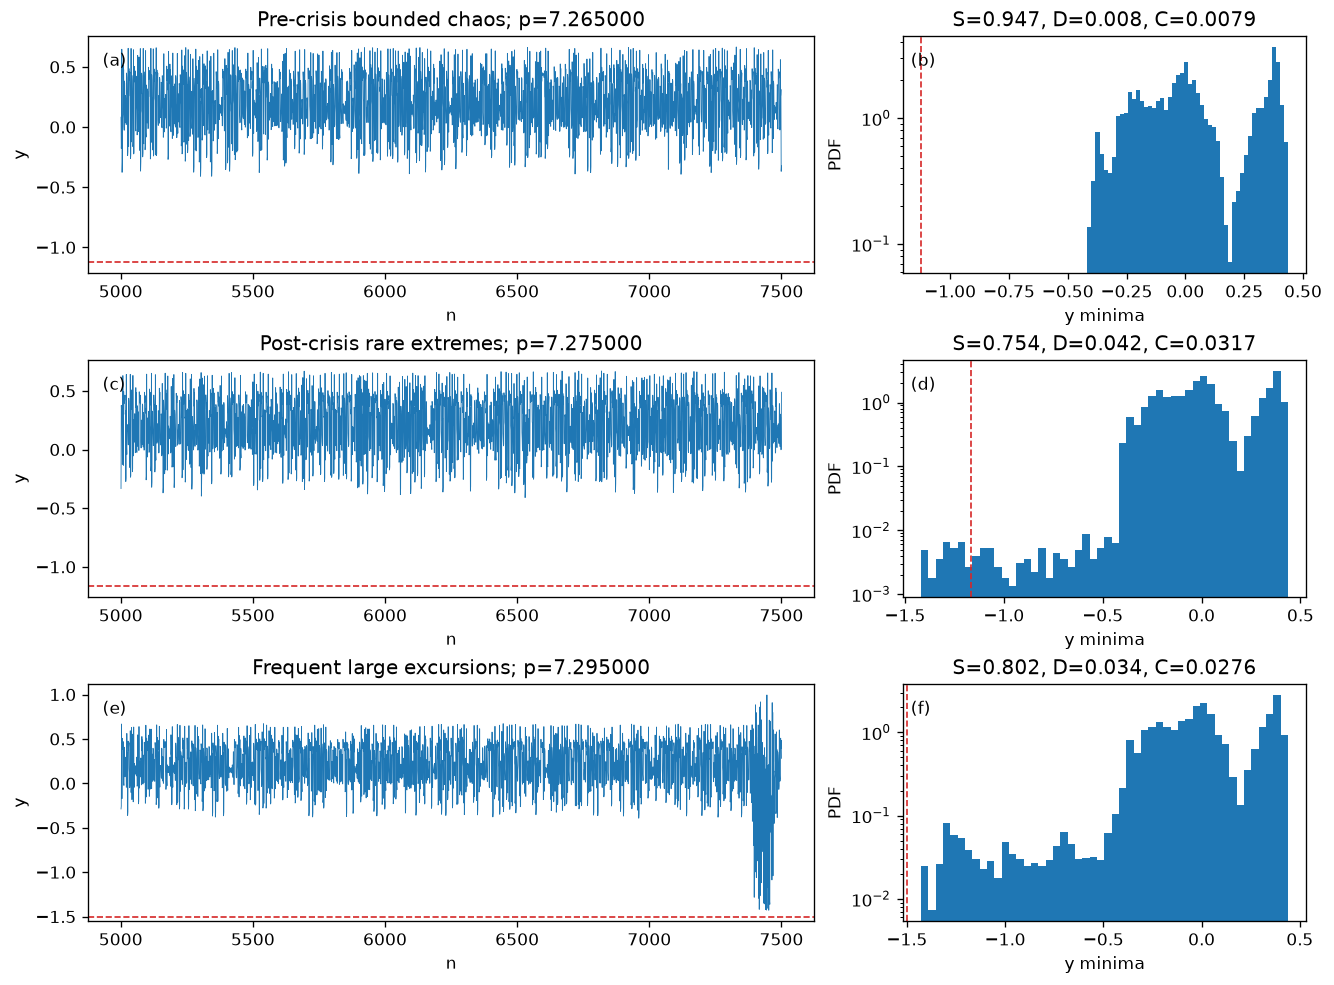

In [46]:
figure4 = []
for p, label in (
    (7.265, "Pre-crisis bounded chaos"),
    (7.275, "Post-crisis rare extremes"),
    (7.295, "Frequent large excursions"),
):
    record = ikeda_examples[p]
    stats = peak_statistics(
        record["extrema"], IKEDA_SETTINGS["retained"], lower_tail=True
    )
    figure4.append(
        {"parameter": p, "label": label, "record": record, "stats": stats}
    )
rows = []
for item in figure4:
    record, stats = item["record"], item["stats"]
    window = (record["extrema_time"] >= record["trace_time"][0]) & (
        record["extrema_time"] <= record["trace_time"][-1]
    )
    shown = record["extrema"][window]
    rows.append(
        [
            item["parameter"],
            int(record["trace_time"][0]),
            int(record["trace_time"][-1]),
            int(np.sum(shown < stats["threshold"])),
            stats["count"],
            int(np.sum(shown < -0.8)),
        ]
    )
show_table(
    [
        "p",
        "Display start",
        "Display end",
        "Shown minima < full T",
        "Full minima < T",
        "Shown minima < -0.8",
    ],
    rows,
)
plot_temporal_pdfs(figure4, "p", "n")

**Figure:** Fig. 4(a–f).
**Observation:** full-record C is 0.00791, 0.03166, and 0.02764 at the three
reported p values, while the fixed p = 7.275 display segment contains zero
threshold crossings despite 67 in the full 200,000-iterate record.
**Scientific meaning:** the rare tail affects the full amplitude distribution
even when a short display misses it; frequent large excursions redistribute
probabilities and can lower C and move the lower-tail threshold.
**Reproduction status:** **partially reproduced**; the full PDFs and complexity
ordering agree qualitatively, but the preselected temporal segments do not
reproduce the published timing or density of bursts and have not been replaced.

## 13. Final numerical audit

Check normalizations, bounds, peak direction, resolution sensitivity, and cache
provenance for all plotted sweep conditions. The counts below distinguish
unique control-parameter values from distinct numerical/initial-state protocols.
A cache entry is an integration or map record, not a new physical realization.
Sparse or absent threshold exceedances are explicitly reported rather than
silently equated with a converged rare-event probability.

In [47]:
resolution_sensitive = []
for model, records, duration, resolution, lower_tail in (
    ("PM", pm_sweep, 50_000, AMPLITUDE_RESOLUTION, False),
    ("Crisis", crisis_sweep, 50_000, AMPLITUDE_RESOLUTION, False),
    ("Ikeda", ikeda_sweep, IKEDA_SETTINGS["retained"], 0.0, True),
):
    for parameter, record in records.items():
        peaks = record["extrema"]
        stats = peak_statistics(
            peaks, duration, resolution=resolution, lower_tail=lower_tail
        )
        np.testing.assert_allclose(stats["probabilities"].sum(), 1, atol=1e-14)
        np.testing.assert_allclose(
            stats["c"], stats["s"] * stats["d"], atol=1e-14
        )
        assert stats["n"] > N_BINS
        assert all(-1e-14 <= stats[k] <= 1 + 1e-14 for k in ("s", "d", "c"))
        if model != "Ikeda":
            alternatives = [
                complexity_measures(
                    resolved_histogram(peaks, f * resolution)[0]
                )[2]
                for f in (0.1, 1.0, 10.0)
            ]
            if np.ptp(alternatives) > 1e-12:
                resolution_sensitive.append(
                    [
                        model,
                        f"{parameter:.10f}",
                        f"{stats['span']:.3e}",
                        *(f"{value:.6f}" for value in alternatives),
                    ]
                )
    total_extrema = sum(r["extrema"].size for r in records.values())
    print(f"{model}: {len(records)} conditions; {total_extrema:,} extrema")
show_table(
    [
        "Route",
        "Parameter",
        "Peak range",
        "C at delta/10",
        "C at delta",
        "C at 10 delta",
    ],
    resolution_sensitive,
)
print("Resolution-sensitive conditions:", len(resolution_sensitive))
cache_files = sorted(CACHE_DIR.glob("*.npz"))
active_files = [p for p in cache_files if p.name in CACHE_USED]
cache_protocols = set()
for file in active_files:
    with np.load(file, allow_pickle=False) as saved:
        metadata = json.loads(saved["metadata"].item())
        assert metadata["parameters"] == (
            MODEL if metadata["model"] == "lienard" else IKEDA
        )
        assert np.all(np.isfinite(saved["extrema"]))
        cache_protocols.add(
            (
                metadata["model"],
                metadata["parameter"],
                json.dumps(metadata["settings"], sort_keys=True),
            )
        )
print(
    "Active cache files:",
    len(active_files),
    "; protocols:",
    len(cache_protocols),
)
print("Total cache files including prior protocols:", len(cache_files))
print(
    f"Cache size: {sum(p.stat().st_size for p in cache_files) / 2**20:.2f} MiB"
)
print("Cache activity during this execution:", CACHE_ACTIVITY)
print("All plotted records passed normalization and measure-bound checks.")
print("Resolution sensitivity is reported as a finding, not forced to vanish.")

PM: 24 conditions; 129,149 extrema
Crisis: 24 conditions; 145,171 extrema
Ikeda: 56 conditions; 3,391,143 extrema


| Route | Parameter | Peak range | C at delta/10 | C at delta | C at 10 delta |
|---|---|---|---|---|---|
| PM | 0.6421953125 | 1.218e-07 | 0.070296 | 0.070296 | -0.000000 |

Resolution-sensitive conditions: 1


Active cache files: 134 ; protocols: 134
Total cache files including prior protocols: 134
Cache size: 68.31 MiB
Cache activity during this execution: {'hits': 152, 'computed': 0}
All plotted records passed normalization and measure-bound checks.
Resolution sensitivity is reported as a finding, not forced to vanish.


### Phase 2 Conclusions and Phase 3 Handoff

1. **Numerical findings verified.** The original Phase 1 equations, functions,
   analytical tests, and source cells are preserved. Refinement gives empirical
   δ ≈ 9.54 × 10⁻⁸; it resolves baseline period-1 integration noise and leaves
   genuine broad rare tails unchanged. It does not solve every transient problem:
   ω = 0.6421953125 has a 1.22 × 10⁻⁷ peak drift after a 5,000-time-unit discard,
   produces C ≈ 0.0703, and is resolution-sensitive. Discarding 50,000 removes
   this drift, while large excursions at the other checked near-onset frequencies
   persist. The main sweep is not silently replaced with the longer-discard data.
2. **Figures 1–4 status: partially reproduced.** Every requested panel and fixed
   representative condition is implemented. The broad increases and subsequent
   decreases of C are observed, and the Ikeda full-record PDFs and representative
   complexity ordering agree qualitatively. Exact trajectories and the published
   smooth curves are not matched. The fixed Fig. 4 window at p = 7.275 has no
   threshold crossing despite 67 in the full record; it has not been cherry-picked.
3. **Quantitative transition comparison.** The main PM excursion bracket is
   [0.6421953125, 0.6422031250], width 7.81 × 10⁻⁶, midpoint 1.28 × 10⁻⁵ below
   the printed 0.642212. Reading toward decreasing ω, the crisis records give two
   expansion intervals: [0.7324375, 0.7325] and [0.7321875, 0.73225]; neither
   contains 0.73242, and the intervening bounded behavior prevents a single
   monotone transition claim. The Ikeda main records give several intermittent
   detection intervals rather than one stable p_c. The longer check has no
   observed excursion at p_c + 10⁻⁶ and only one threshold-crossing minimum at
   p_c + 10⁻⁵; the printed eight-decimal critical value is **not quantitatively
   verified**. These are finite-observation brackets, never confidence intervals.
4. **Observed discrepancies versus possible causes.** PM C changes with retained
   length (about 0.164, 0.157, 0.153) and initial state (about 0.142–0.157).
   The selected crisis pair has C = 0.0983 (rare) versus 0.1164 (frequent), so those
   two points alone do not establish a universal ordering. Negative local maxima
   remain in the Liénard PDFs although the published plots show nonnegative axes.
   Unknown author protocols, continuation, competing attractors, residual
   transients, and rare-tail undersampling are **hypotheses** for differences,
   not proven explanations. The targeted tighter-solver test and initial-state
   comparisons are reported explicitly above.
5. **Remaining limitations.** All sweeps are independent-start records with
   documented finite lengths. A local error calibration is not a uniform global
   bound; a small grid spacing is not statistical convergence. Particularly near
   the Ikeda crisis, a single sampled excursion changes the min–max support and
   C substantially. Moving sample-derived thresholds can also alter exceedance
   rates without changing what enters the complexity estimate. The initial-state
   tests cannot establish the complete basin structure or prove multistability.
6. **Scientific understanding.** S has different responses across the two
   Liénard routes, while C combines distribution spread and concentration.
   Complexity is a distribution statistic, not a threshold input, proof of a
   bifurcation, or forecast. Rare and frequent excursions can have different C,
   but sharp complexity changes also arise from numerical drift and finite-record
   support changes. The cache records provenance for every expensive computation.
7. **Prepare Phase 3 only.** Carry forward these numerical conventions and
   unresolved transition/statistical discrepancies. Before a coupled Hindmarsh–Rose
   run, verify the paper's coupling-sign convention; then plan its Fig. 6 bin-count
   robustness analysis with adequate rare-event observations and multiple initial
   states. No Hindmarsh–Rose implementation, Figs. 5–6, or sliding-window extension
   is included in this phase.

# Phase 3 — Final reproduction and scientific audit

The first **91 cells, including their saved outputs and interpretations**, are
preserved as the Phase 1–2 record. This final phase adds the six-dimensional HR
model, Fig. 5, controlled bin-count comparisons for Fig. 6, and an assessment of
Figs. 1–6. The primary reference remains the supplied PDF, Section III.C,
Eqs. (7)–(10), Fig. 5, Appendix B, and Fig. 6; the existing research discussion
provides supporting context. No separate summary document is created.

Phase 3 was executed in a fresh kernel using the verified definitions and
metadata-matched Phase 2 caches; expensive earlier trajectories were not rerun.
The complete notebook remains ordered for a top-to-bottom run. Earlier execution
counts belong to their saved sessions. Numerical values in interpretations refer
to the saved experiments and must be reassessed if their settings change.

The empirical Liénard resolution ≈ 9.54 × 10⁻⁸ is **not** transferred to HR as a
universal error bound. Unverified transition values, finite-record excursion
brackets, residual transients, and the nonmonotone Phase 2 observations remain
part of the evidence rather than being overwritten.

## 14. Stage A — HR equations, coupling sign, and observable

State ordering is **(x₁, y₁, z₁, x₂, y₂, z₂)**. The printed model is
\[
\dot x_i=y_i+b x_i^2-a x_i^3-z_i+I
-\epsilon(x_i-v_s)\Gamma(x_j),\quad
\dot y_i=c-d x_i^2-y_i,\quad
\dot z_i=r[s(x_i-x_R)-z_i],
\]
\[
\Gamma(x)=\frac{1}{1+\exp[-\lambda(x-\theta)]},\qquad i\ne j.
\]
The observable is **x_parallel = x₁ + x₂**, without division by two or replacement
by a norm or difference. Its maxima are downward zeros of dx₁/dt + dx₂/dt.

**Sign audit (journal pages 5–6):** Eq. (7) has a leading minus on ε, the prose
calls ε positive and inhibitory, but Fig. 5 labels ε < 0, including −0.07127 and
−0.1431. We follow the **printed equation with signed negative ε**, with no
absolute value or sign reversal. When xᵢ < v_s and Γ(xⱼ) > 0, ε < 0 gives a
negative contribution to dxᵢ/dt; ε > 0 gives a positive one. The instantaneous
sign reverses above the reversal potential, so this algebra does not prove the
network's dynamical mechanism. Fig. 5 spans [−0.20, −0.05]; the reported growth
of excursions is read toward decreasing ε, from weaker to stronger magnitude.

**Threshold provenance:** Section III gives T = μ + dσ with d in [4, 8], but
neither Section III.C nor the Fig. 5 caption specifies an HR-specific d. We use
**d_HR = 6 as an implementation assumption**, population σ, and all maxima.
The parameter d = 5 in the neuron equation is a different quantity. A targeted
4/6/8 threshold comparison is reported later; none of these markers enters C.

In [20]:
from scipy.special import expit

HR = {
    "a": 1.0,
    "b": 3.0,
    "c": 1.0,
    "d": 5.0,
    "x_r": -1.6,
    "r": 0.01,
    "s": 5.0,
    "current": 4.0,
    "v_s": 2.0,
    "lambda": 10.0,
    "theta": -0.25,
}
HR_HEIGHT_FACTOR = 6.0
assert HR_HEIGHT_FACTOR == HEIGHT_FACTOR
HR_INITIALS = (
    (-1.0, -5.0, 3.0, -1.2, -6.0, 3.1),
    (-1.5, -10.0, 2.0, 0.5, -4.0, 3.0),
    (-1.0, -5.0, 3.0, -1.0, -5.0, 3.0),
)
HR_SETTINGS = {
    "initial_state": HR_INITIALS[0],
    "transient": 10_000.0,
    "duration": 20_000.0,
    "method": "DOP853",
    "rtol": 1e-8,
    "atol": 1e-10,
    "max_step": 0.5,
    "sample_dt": 0.05,
    "trace_start": 40_000.0,
    "trace_duration": 0.0,
}
HR_BASELINE = {
    **HR_SETTINGS,
    "transient": 5_000.0,
    "duration": 10_000.0,
    "trace_start": 0.0,
    "trace_duration": 1_000.0,
}
HR_CASES = {"weak": -0.06, "A": -0.07127, "B": -0.1431}
HR_CACHE_ACTIVITY = {"hits": 0, "computed": 0}
HR_CACHE_USED = set()
print("HR state order: x1, y1, z1, x2, y2, z2")
print("Main sweep numerical assumptions:", HR_SETTINGS)
print("No random numbers are used.")
PHASE2_COMPUTATIONS_AT_PHASE3_START = CACHE_ACTIVITY["computed"]

HR state order: x1, y1, z1, x2, y2, z2
Main sweep numerical assumptions: {'initial_state': (-1.0, -5.0, 3.0, -1.2, -6.0, 3.1), 'transient': 10000.0, 'duration': 20000.0, 'method': 'DOP853', 'rtol': 1e-08, 'atol': 1e-10, 'max_step': 0.5, 'sample_dt': 0.05, 'trace_start': 40000.0, 'trace_duration': 0.0}
No random numbers are used.


In [21]:
def hr_rhs(time, state, epsilon):
    """Printed HR equations (7)-(10), with signed epsilon."""
    x1, y1, z1, x2, y2, z2 = state
    gate1 = expit(HR["lambda"] * (x1 - HR["theta"]))
    gate2 = expit(HR["lambda"] * (x2 - HR["theta"]))
    dx1 = (
        y1
        + HR["b"] * x1**2
        - HR["a"] * x1**3
        - z1
        + HR["current"]
        - epsilon * (x1 - HR["v_s"]) * gate2
    )
    dx2 = (
        y2
        + HR["b"] * x2**2
        - HR["a"] * x2**3
        - z2
        + HR["current"]
        - epsilon * (x2 - HR["v_s"]) * gate1
    )
    return (
        dx1,
        HR["c"] - HR["d"] * x1**2 - y1,
        HR["r"] * (HR["s"] * (x1 - HR["x_r"]) - z1),
        dx2,
        HR["c"] - HR["d"] * x2**2 - y2,
        HR["r"] * (HR["s"] * (x2 - HR["x_r"]) - z2),
    )


def hr_sum_maximum(time, state, epsilon):
    """Locate downward crossings of the derivative of x1 + x2."""
    derivative = hr_rhs(time, state, epsilon)
    return derivative[0] + derivative[3]


hr_sum_maximum.direction = -1
hr_sum_maximum.terminal = False

In [22]:
state = np.array([-1.0, -5.0, 3.0, 0.5, -4.0, 3.0])
uncoupled = np.array(hr_rhs(0.0, state, 0.0))
np.testing.assert_allclose(
    uncoupled, (0, 1, 0, -2.375, 3.75, 0.075), atol=1e-14
)
for epsilon in (-0.1, 0.1):
    derivative = np.array(hr_rhs(0.0, state, epsilon))
    expected = uncoupled.copy()
    expected[0] -= epsilon * (-1.0 - 2.0) * expit(10 * (0.5 + 0.25))
    expected[3] -= epsilon * (0.5 - 2.0) * expit(10 * (-1.0 + 0.25))
    np.testing.assert_allclose(derivative, expected)
    swapped = np.r_[state[3:], state[:3]]
    np.testing.assert_allclose(
        hr_rhs(0, swapped, epsilon), np.r_[derivative[3:], derivative[:3]]
    )
    shift = derivative[[0, 3]] - uncoupled[[0, 3]]
    assert np.all(shift < 0) if epsilon < 0 else np.all(shift > 0)
synchronous = np.array(HR_INITIALS[2])
np.testing.assert_array_equal(
    np.array(hr_rhs(0, synchronous, -0.1))[:3],
    np.array(hr_rhs(0, synchronous, -0.1))[3:],
)
print(
    "Component values, neuron exchange, coupling signs, and symmetry verified."
)

Component values, neuron exchange, coupling signs, and symmetry verified.


## 15. Stage B — Baseline integration and numerical checks

DOP853 settings, initial conditions, data lengths, and sample intervals are
implementation assumptions, not reported author settings. The baseline discards
5,000 and retains 10,000 time units at three coupling values: weak
ε = −0.06 and the two reported Fig. 5 conditions A/B. The main sweep will discard
10,000 and retain 20,000; the representative records retain 50,000 after the same
10,000 discard. These protocols are kept separate in tables and metadata.

Initial state 1 is asymmetric and was chosen before the pilot integrations.
State 2 is another asymmetric state; state 3 is **exactly synchronous**, an
invariant subspace used as a deliberate control, not a generic attractor sample.
Exact equations preserve synchrony, but long floating-point integrations may
amplify roundoff and leave this subspace; the final mismatch is measured below.
No initial state is substituted into the main sweep to make a published panel fit.

In [23]:
def run_hr(epsilon, settings):
    """Integrate HR and retain extrema, displays, and a local audit state."""
    started = perf_counter()
    transient = settings["transient"]
    stop = transient + settings["duration"]
    if settings["trace_duration"]:
        trace_end = settings["trace_start"] + settings["trace_duration"]
        if trace_end > stop:
            raise ValueError("HR display interval exceeds the integration.")
        intervals = round(settings["trace_duration"] / settings["sample_dt"])
        trace_times = settings["trace_start"] + settings[
            "sample_dt"
        ] * np.arange(intervals + 1)
        times = np.unique(np.r_[trace_times, stop])
    else:
        trace_end, times = 0.0, [stop]
    solution = solve_ivp(
        hr_rhs,
        (0.0, stop),
        settings["initial_state"],
        args=(epsilon,),
        events=hr_sum_maximum,
        t_eval=times,
        method=settings["method"],
        rtol=settings["rtol"],
        atol=settings["atol"],
        max_step=settings["max_step"],
    )
    if not solution.success or not np.all(np.isfinite(solution.y)):
        raise RuntimeError(f"epsilon={epsilon}: {solution.message}")
    event_time, event_state = solution.t_events[0], solution.y_events[0]
    keep = (event_time > transient) & (event_time < stop)
    peaks = event_state[keep, 0] + event_state[keep, 3]
    if peaks.size == 0:
        raise RuntimeError("No HR maxima in the retained interval.")
    anchor = max(0, int(np.argmax(peaks)) - 3)
    display = (
        ((solution.t >= settings["trace_start"]) & (solution.t <= trace_end))
        if settings["trace_duration"]
        else np.zeros(solution.t.size, dtype=bool)
    )
    early = (event_time > 0) & (event_time < transient)
    return {
        "extrema_time": event_time[keep],
        "extrema": peaks,
        "trace_time": solution.t[display],
        "trace_y": solution.y[0, display] + solution.y[3, display],
        "transient_time": event_time[early],
        "transient_peaks": event_state[early, 0] + event_state[early, 3],
        "anchor_time": np.array(event_time[keep][anchor]),
        "anchor_state": event_state[keep][anchor],
        "final_state": solution.y[:, -1],
        "nfev": np.array(solution.nfev),
        "seconds": np.array(perf_counter() - started),
    }

In [24]:
def cached_hr(epsilon, settings):
    """Keep the existing cache format without modifying Phase 2 functions."""
    if hr_sum_maximum.direction != -1 or hr_sum_maximum.terminal:
        raise ValueError("HR requires nonterminal maxima of x1 + x2.")
    source = "\n".join(
        inspect.getsource(f) for f in (hr_rhs, hr_sum_maximum, run_hr)
    )
    metadata = {
        "schema": 1,
        "model": "hr",
        "parameter": float(epsilon),
        "parameters": HR,
        "settings": settings,
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "python": platform.python_version(),
        "source_sha256": hashlib.sha256(source.encode()).hexdigest(),
        "extremum": "x1 + x2 maximum",
        "event_direction": -1,
    }
    serialized = json.dumps(metadata, sort_keys=True)
    key = hashlib.sha256(serialized.encode()).hexdigest()[:20]
    path = CACHE_DIR / f"hr_{epsilon:.9f}_{key}.npz"
    if path.exists():
        with np.load(path, allow_pickle=False) as saved:
            if saved["metadata"].item() != serialized:
                raise RuntimeError(f"HR cache metadata mismatch: {path}")
            record = {
                name: saved[name].copy()
                for name in saved.files
                if name != "metadata"
            }
        HR_CACHE_ACTIVITY["hits"] += 1
    else:
        record = run_hr(epsilon, settings)
        if not np.all(np.isfinite(record["extrema"])):
            raise RuntimeError("Nonfinite HR extrema cannot be cached.")
        temporary = path.with_suffix(".tmp")
        with temporary.open("wb") as stream:
            np.savez_compressed(stream, metadata=serialized, **record)
        temporary.replace(path)
        HR_CACHE_ACTIVITY["computed"] += 1
    HR_CACHE_USED.add(path.name)
    return record

In [25]:
hr_baseline = {}
rows = []
for label, epsilon in HR_CASES.items():
    record = cached_hr(epsilon, HR_BASELINE)
    hr_baseline[label] = record
    stats = peak_statistics(record["extrema"], HR_BASELINE["duration"])
    rows.append(
        [
            label,
            epsilon,
            int(HR_BASELINE["transient"]),
            int(HR_BASELINE["duration"]),
            stats["n"],
            f"{record['extrema'].min():.5f}",
            f"{record['extrema'].max():.5f}",
            f"{stats['s']:.5f}",
            f"{stats['d']:.5f}",
            f"{stats['c']:.5f}",
            stats["count"],
            f"{1_000 * stats['rate']:.3f}",
        ]
    )
    print(
        f"HR baseline {label}: {stats['n']} maxima; "
        f"{record['seconds'].item():.1f} s",
        flush=True,
    )
show_table(
    [
        "Case",
        "epsilon",
        "Discarded",
        "Retained",
        "Peaks",
        "Min peak",
        "Max peak",
        "S",
        "D",
        "C",
        "Peaks > assumed T",
        "Rate / 1000 t",
    ],
    rows,
)

HR baseline weak: 721 maxima; 6.7 s


HR baseline A: 718 maxima; 6.8 s


HR baseline B: 704 maxima; 7.0 s


| Case | epsilon | Discarded | Retained | Peaks | Min peak | Max peak | S | D | C | Peaks > assumed T | Rate / 1000 t |
|---|---|---|---|---|---|---|---|---|---|---|---|
| weak | -0.06 | 5000 | 10000 | 721 | 0.38164 | 1.12761 | 0.84089 | 0.02751 | 0.02313 | 0 | 0.000 |
| A | -0.07127 | 5000 | 10000 | 718 | 0.31694 | 3.30028 | 0.57345 | 0.12080 | 0.06927 | 5 | 0.500 |
| B | -0.1431 | 5000 | 10000 | 704 | 0.18994 | 2.93819 | 0.69303 | 0.06203 | 0.04299 | 2 | 0.200 |

### 15.1 Solver and sampling refinement

Restart an 80-time-unit interval from an identical saved state just before the
largest baseline maximum. Compare baseline tolerances with rtol = 10⁻¹⁰,
atol = 10⁻¹² and half max_step. Common timestamps measure local state error;
event roots measure peak-amplitude error. Sampling at 0.05 and 0.025 is compared
on the tighter solution, excluding a one-sample margin at both boundaries.
This is local numerical convergence, not long-time statistical convergence.

In [26]:
hr_errors, convergence_rows = [], []
for label, record in hr_baseline.items():
    start = float(record["anchor_time"])
    times = start + np.arange(3_201) * 0.025
    solutions = []
    for rtol, atol, step in ((1e-8, 1e-10, 0.5), (1e-10, 1e-12, 0.25)):
        solution = solve_ivp(
            hr_rhs,
            (start, float(times[-1])),
            record["anchor_state"],
            args=(HR_CASES[label],),
            method="DOP853",
            events=hr_sum_maximum,
            t_eval=times,
            rtol=rtol,
            atol=atol,
            max_step=step,
        )
        if not solution.success:
            raise RuntimeError(solution.message)
        solutions.append(solution)
    baseline, refined = solutions
    paired = []
    for solution in solutions:
        keep = (solution.t_events[0] > start + 0.05) & (
            solution.t_events[0] < times[-1] - 0.05
        )
        paired.append(
            (
                solution.t_events[0][keep],
                solution.y_events[0][keep, 0] + solution.y_events[0][keep, 3],
            )
        )
    assert paired[0][0].size == paired[1][0].size > 0
    error = float(np.max(np.abs(paired[0][1] - paired[1][1])))
    state_error = float(np.max(np.abs(baseline.y - refined.y)))
    assert state_error < 1e-3, "Investigate local HR integration accuracy."
    hr_errors.append(error)
    sample_errors = []
    signal = refined.y[0] + refined.y[3]
    for stride in (2, 1):
        ts, ys = local_extrema(times[::stride], signal[::stride])
        keep = (ts > start + 0.05) & (ts < times[-1] - 0.05)
        ts, ys = ts[keep], ys[keep]
        assert ts.size == paired[1][0].size
        nearest = np.argmin(
            np.abs(ts[:, None] - paired[1][0][None, :]), axis=1
        )
        sample_errors.append(np.max(np.abs(ys - paired[1][1][nearest])))
    convergence_rows.append(
        [
            label,
            paired[0][0].size,
            f"{state_error:.3e}",
            f"{error:.3e}",
            *(f"{value:.3e}" for value in sample_errors),
        ]
    )
HR_RESOLUTION = 10 * max(max(hr_errors), 100 * np.finfo(float).eps)
show_table(
    [
        "Case",
        "Paired maxima",
        "Max state error",
        "Max peak error",
        "Sample error 0.05",
        "Sample error 0.025",
    ],
    convergence_rows,
)
print(f"Local empirical HR resolution scale: {HR_RESOLUTION:.3e}")
print("HR primary estimates remain literal; this scale is a diagnostic only.")

| Case | Paired maxima | Max state error | Max peak error | Sample error 0.05 | Sample error 0.025 |
|---|---|---|---|---|---|
| weak | 5 | 6.200e-06 | 3.507e-08 | 1.420e-03 | 3.963e-04 |
| A | 4 | 9.547e-06 | 2.023e-07 | 3.961e-03 | 7.690e-04 |
| B | 4 | 1.844e-05 | 3.323e-07 | 3.699e-03 | 4.732e-04 |

Local empirical HR resolution scale: 3.323e-06
HR primary estimates remain literal; this scale is a diagnostic only.


### 15.2 Transients and initial conditions

The diagnostic figure compares initial dynamics and maxima before/after the
baseline discard. Large initial peaks are not counted as stationary extreme
events. The table repeats A and B from two additional states with exactly the
same baseline protocol. Exact synchrony is an invariant-subspace control;
different finite-record distributions do not prove multistability or chaos.

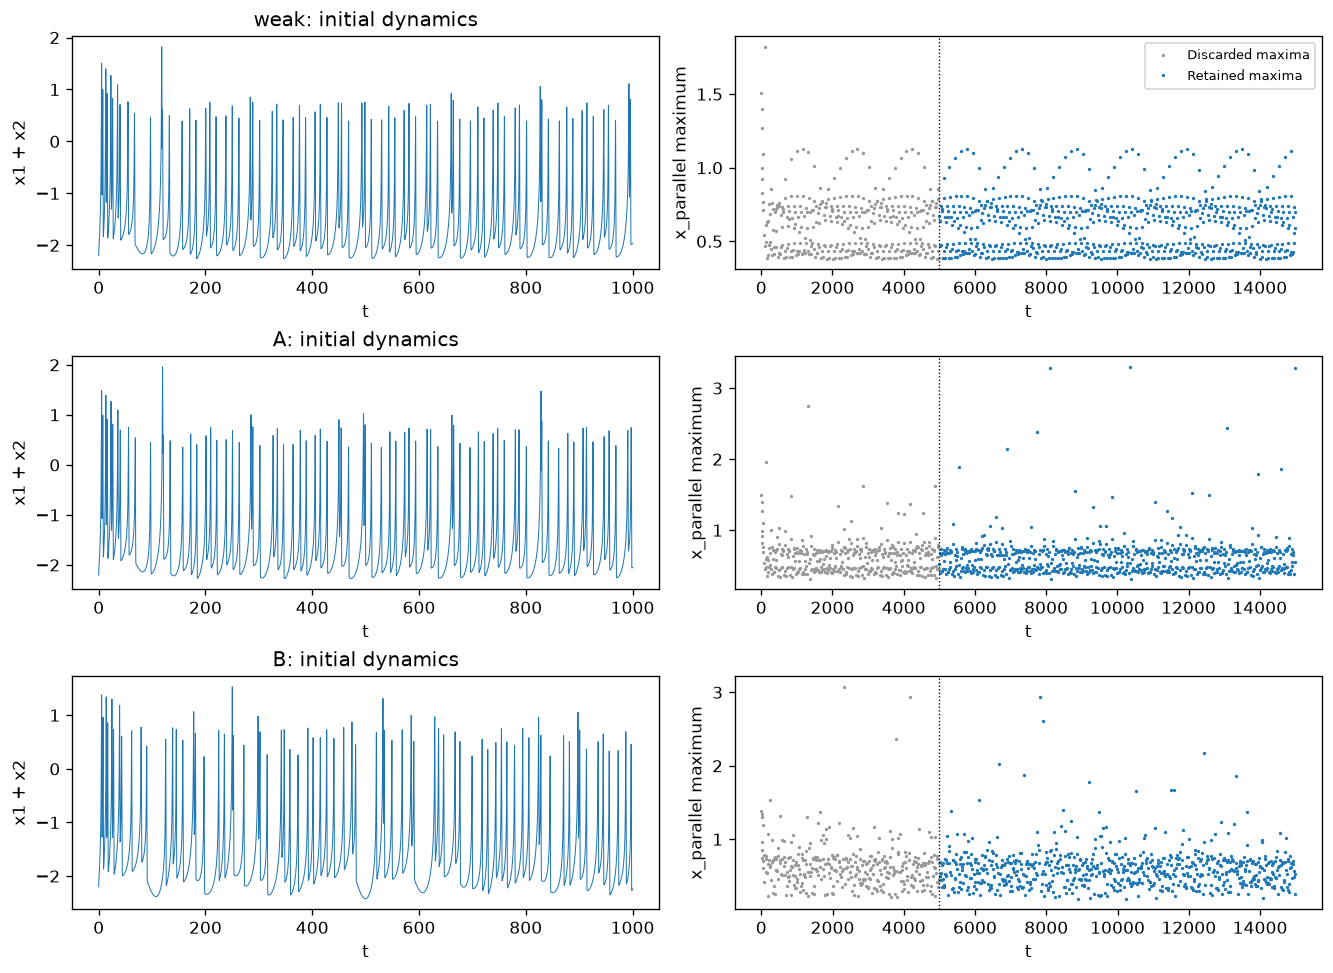

In [27]:
fig, axes = plt.subplots(3, 2, figsize=(11, 8), layout="constrained")
for row, (label, record) in enumerate(hr_baseline.items()):
    axes[row, 0].plot(record["trace_time"], record["trace_y"], lw=0.6)
    axes[row, 0].set(
        xlabel="t", ylabel="x1 + x2", title=f"{label}: initial dynamics"
    )
    axes[row, 1].plot(
        record["transient_time"],
        record["transient_peaks"],
        ".",
        ms=2,
        color="0.6",
        label="Discarded maxima",
    )
    axes[row, 1].plot(
        record["extrema_time"],
        record["extrema"],
        ".",
        ms=2,
        label="Retained maxima",
    )
    axes[row, 1].axvline(HR_BASELINE["transient"], color="k", ls=":", lw=0.8)
    axes[row, 1].set(xlabel="t", ylabel="x_parallel maximum")
axes[0, 1].legend(fontsize=8)
plt.show()

**Diagnostic purpose:** distinguish the initial adaptation and coupled transient
from the retained observable's amplitude distribution. Event maxima are checked
against direct uniformly sampled extrema in the preceding numerical audit.
Persistent differences between initial and late records motivate a longer
discard for the main sweep, but a fixed discard alone does not establish stationarity.

In [28]:
hr_initial_records, initial_rows = {}, []
for label in ("A", "B"):
    for index, initial in enumerate(HR_INITIALS):
        if index == 0:
            record = hr_baseline[label]
        else:
            settings = {**HR_BASELINE, "initial_state": initial}
            record = cached_hr(HR_CASES[label], settings)
        hr_initial_records[(label, index)] = record
        stats = peak_statistics(record["extrema"], HR_BASELINE["duration"])
        final_mismatch = np.max(
            np.abs(record["final_state"][:3] - record["final_state"][3:])
        )
        initial_rows.append(
            [
                label,
                index + 1,
                "symmetric start" if index == 2 else "asymmetric",
                stats["n"],
                f"{record['extrema'].max():.5f}",
                f"{stats['c']:.5f}",
                stats["count"],
                f"{1_000 * stats['rate']:.3f}",
                f"{final_mismatch:.3e}",
            ]
        )
        print(f"HR initial-state check {label}, state {index + 1}", flush=True)
show_table(
    [
        "Case",
        "State",
        "Type",
        "Peaks",
        "Highest peak",
        "C",
        "Peaks > own assumed T",
        "Rate / 1000 t",
        "Final neuron-state mismatch",
    ],
    initial_rows,
)

HR initial-state check A, state 1


HR initial-state check A, state 2


HR initial-state check A, state 3


HR initial-state check B, state 1


HR initial-state check B, state 2


HR initial-state check B, state 3


| Case | State | Type | Peaks | Highest peak | C | Peaks > own assumed T | Rate / 1000 t | Final neuron-state mismatch |
|---|---|---|---|---|---|---|---|---|
| A | 1 | asymmetric | 718 | 3.30028 | 0.06927 | 5 | 0.500 | 1.956e+00 |
| A | 2 | asymmetric | 717 | 3.32441 | 0.07155 | 6 | 0.600 | 3.106e+00 |
| A | 3 | symmetric start | 718 | 3.34007 | 0.07019 | 7 | 0.700 | 3.933e+00 |
| B | 1 | asymmetric | 704 | 2.93819 | 0.04299 | 2 | 0.200 | 3.207e+00 |
| B | 2 | asymmetric | 702 | 3.20315 | 0.04479 | 3 | 0.300 | 3.258e+00 |
| B | 3 | symmetric start | 700 | 2.93882 | 0.04052 | 4 | 0.400 | 2.974e+00 |

### Numerical symmetry control

The two exactly identical neuron triples give identical derivatives in the
component test, so exact ODE solutions remain synchronous. However, the saved
long integrations from this state have a nonzero neuron-state difference:
this is numerical symmetry breaking, not evidence for two physical solutions
from identical exact initial conditions. The following short integrations
measure departure from synchrony under two solver settings. Their first crossing
of a small mismatch level is a numerical diagnostic, not a transverse Lyapunov
exponent or a proof of the subspace's stability. The main sweep uses the declared
asymmetric state throughout.

In [29]:
symmetry_rows = []
for rtol, atol, step in ((1e-8, 1e-10, 0.5), (1e-10, 1e-12, 0.25)):
    solution = solve_ivp(
        hr_rhs,
        (0.0, 1_000.0),
        HR_INITIALS[2],
        args=(HR_CASES["A"],),
        method="DOP853",
        t_eval=np.arange(0, 1_000.5, 0.5),
        rtol=rtol,
        atol=atol,
        max_step=step,
    )
    if not solution.success:
        raise RuntimeError(solution.message)
    mismatch = np.max(np.abs(solution.y[:3] - solution.y[3:]), axis=0)
    crossed = solution.t[mismatch > 1e-6]
    symmetry_rows.append(
        [
            rtol,
            step,
            f"{mismatch.max():.3e}",
            f"{crossed[0]:.1f}" if crossed.size else "not within 1000 t",
        ]
    )
show_table(
    [
        "rtol",
        "Max step",
        "Largest neuron-state mismatch",
        "First mismatch > 1e-6",
    ],
    symmetry_rows,
)

| rtol | Max step | Largest neuron-state mismatch | First mismatch > 1e-6 |
|---|---|---|---|
| 1e-08 | 0.5 | 6.281e+00 | 507.0 |
| 1e-10 | 0.25 | 6.367e+00 | 507.0 |

### 15.3 Record length and representative-data protocol

Generate one longer record at each reported A/B condition, discarding 10,000
and retaining 50,000 time units. Nested 10,000 / 25,000 / 50,000 prefixes assess
S, D, C and threshold counts without rerunning a trajectory for each length.
Each prefix defines its own T; a common longest-record T is also counted.
All statistical events are maxima, not independently identified burst episodes.
The display interval is fixed now at **t = 40,000–45,000**, independent of whether
it contains a burst. Only this short trace, extrema, and a few audit states are cached.

In [30]:
hr_representatives, length_rows = {}, []
for label in ("A", "B"):
    settings = {
        **HR_SETTINGS,
        "duration": 50_000.0,
        "trace_start": 40_000.0,
        "trace_duration": 5_000.0,
    }
    record = cached_hr(HR_CASES[label], settings)
    hr_representatives[label] = record
    longest = peak_statistics(record["extrema"], settings["duration"])
    for length in (10_000.0, 25_000.0, 50_000.0):
        keep = record["extrema_time"] < settings["transient"] + length
        peaks = record["extrema"][keep]
        stats = peak_statistics(peaks, length)
        common_count = np.count_nonzero(peaks > longest["threshold"])
        length_rows.append(
            [
                label,
                int(length),
                stats["n"],
                f"{stats['s']:.5f}",
                f"{stats['d']:.5f}",
                f"{stats['c']:.5f}",
                stats["count"],
                f"{1_000 * stats['rate']:.3f}",
                common_count,
            ]
        )
    print(
        f"HR long record {label}: {record['extrema'].size} maxima; "
        f"{record['seconds'].item():.1f} s",
        flush=True,
    )
show_table(
    [
        "Case",
        "Retained t",
        "Maxima",
        "S",
        "D",
        "C",
        "Peaks > own T",
        "Rate / 1000 t",
        "Peaks > longest T",
    ],
    length_rows,
)

HR long record A: 3590 maxima; 27.4 s


HR long record B: 3488 maxima; 28.1 s


| Case | Retained t | Maxima | S | D | C | Peaks > own T | Rate / 1000 t | Peaks > longest T |
|---|---|---|---|---|---|---|---|---|
| A | 10000 | 718 | 0.55870 | 0.12713 | 0.07102 | 6 | 0.600 | 6 |
| A | 25000 | 1795 | 0.58236 | 0.11696 | 0.06812 | 12 | 0.480 | 12 |
| A | 50000 | 3590 | 0.57775 | 0.12112 | 0.06997 | 25 | 0.500 | 25 |
| B | 10000 | 705 | 0.67661 | 0.06642 | 0.04494 | 2 | 0.200 | 2 |
| B | 25000 | 1752 | 0.67243 | 0.07114 | 0.04784 | 8 | 0.320 | 8 |
| B | 50000 | 3488 | 0.67855 | 0.06957 | 0.04721 | 21 | 0.420 | 21 |

### 15.4 Validation checkpoint before the HR sweep

The component-value, coupling-sign, neuron-exchange, and synchronous-subspace
checks verify implementation of the printed equations and state order. The
local tolerance/step/sampling table quantifies solver reliability and gives an
HR-specific empirical resolution used only as a diagnostic. The primary HR
histograms remain literal min–max histograms with m = 50; T uses the explicitly
assumed multiplier 6 and remains independent of C.

Proceed with independent asymmetric state-1 starts, a 10,000 discard and 20,000
retained time units for every sweep point, event-refined maxima, and the declared
DOP853 settings. The initial-state and nested-length tables are the evidence
for unresolved basin, transient, and sampling sensitivity. They do not certify
statistical convergence or prove periodicity, quasiperiodicity, chaos, or a crisis.
The main sweep will be inspected before local refinement; no coupling sign,
parameter, initial state, or histogram is tuned to force a published trend.

## 16. Stage C — Figure 5: coarse HR sweep

Start with **13 uniformly spaced ε values in [−0.20, −0.05]**, each from the
same asymmetric initial state and with the same 10,000 discard / 20,000 retained
protocol. Interpret the sequence toward decreasing ε. The table shows all
observations before local refinement: support, S, D, C, the assumed significant-
height marker, and event rates. Counts above the fixed height 2 are an auxiliary
large-excursion diagnostic, not the significant-height definition or an input to C.

The largest adjacent change in observed peak range selects one coarse interval
for nine-point refinement. This is a computational allocation rule, not a claim
that this interval proves a crisis. A finite record may miss a rare excursion,
and initial-state or transient effects can also change the observed support.
No numerical critical ε is quoted in the Fig. 5 caption; A = −0.07127 and
B = −0.1431 are representative conditions, not assumed exact transition locations.

In [31]:
def collect_hr(parameters):
    """Collect equal-length independent-start HR sweep records."""
    records = {}
    for index, epsilon in enumerate(parameters, 1):
        epsilon = float(epsilon)
        record = cached_hr(epsilon, HR_SETTINGS)
        records[epsilon] = record
        stats = peak_statistics(record["extrema"], HR_SETTINGS["duration"])
        print(
            f"HR sweep {index}/{len(parameters)}: epsilon={epsilon:.8f}; "
            f"{stats['n']} maxima; C={stats['c']:.5f}; "
            f"{stats['count']} peaks above assumed T",
            flush=True,
        )
    return records


HR_COARSE = np.linspace(-0.20, -0.05, 13)
hr_coarse = collect_hr(HR_COARSE)

HR sweep 1/13: epsilon=-0.20000000; 1422 maxima; C=0.03848; 6 peaks above assumed T


HR sweep 2/13: epsilon=-0.18750000; 1412 maxima; C=0.03916; 3 peaks above assumed T


HR sweep 3/13: epsilon=-0.17500000; 1404 maxima; C=0.03959; 6 peaks above assumed T


HR sweep 4/13: epsilon=-0.16250000; 1391 maxima; C=0.04102; 6 peaks above assumed T


HR sweep 5/13: epsilon=-0.15000000; 1413 maxima; C=0.04420; 2 peaks above assumed T


...

HR sweep 9/13: epsilon=-0.10000000; 1420 maxima; C=0.05148; 6 peaks above assumed T


HR sweep 10/13: epsilon=-0.08750000; 1411 maxima; C=0.05616; 9 peaks above assumed T


HR sweep 11/13: epsilon=-0.07500000; 1431 maxima; C=0.06243; 12 peaks above assumed T


HR sweep 12/13: epsilon=-0.06250000; 1441 maxima; C=0.02133; 0 peaks above assumed T


HR sweep 13/13: epsilon=-0.05000000; 1435 maxima; C=0.01806; 0 peaks above assumed T


In [32]:
coarse_rows = []
for epsilon, record in sorted(hr_coarse.items()):
    stats = peak_statistics(record["extrema"], HR_SETTINGS["duration"])
    large_count = np.count_nonzero(record["extrema"] > 2)
    coarse_rows.append(
        [
            f"{epsilon:.6f}",
            stats["n"],
            f"{record['extrema'].min():.4f}",
            f"{record['extrema'].max():.4f}",
            f"{stats['s']:.5f}",
            f"{stats['d']:.5f}",
            f"{stats['c']:.5f}",
            f"{stats['threshold']:.4f}",
            stats["count"],
            f"{1_000 * stats['rate']:.3f}",
            large_count,
        ]
    )
show_table(
    [
        "epsilon",
        "Maxima",
        "Lowest peak",
        "Highest peak",
        "S",
        "D",
        "C",
        "Assumed T",
        "Peaks > T",
        "Rate / 1000 t",
        "Peaks > fixed 2",
    ],
    coarse_rows,
)
parameters = np.array(sorted(hr_coarse))
spans = np.array([np.ptp(hr_coarse[p]["extrema"]) for p in parameters])
index = int(np.argmax(np.abs(np.diff(spans))))
HR_REFINEMENT_BRACKET = (parameters[index], parameters[index + 1])
print("Largest observed peak-range change:", HR_REFINEMENT_BRACKET)

| epsilon | Maxima | Lowest peak | Highest peak | S | D | C | Assumed T | Peaks > T | Rate / 1000 t | Peaks > fixed 2 |
|---|---|---|---|---|---|---|---|---|---|---|
| -0.200000 | 1422 | 0.1355 | 3.0161 | 0.72425 | 0.05313 | 0.03848 | 2.4350 | 6 | 0.300 | 12 |
| -0.187500 | 1412 | 0.1394 | 3.1144 | 0.71116 | 0.05507 | 0.03916 | 2.3088 | 3 | 0.150 | 6 |
| -0.175000 | 1404 | 0.1578 | 3.1319 | 0.71067 | 0.05571 | 0.03959 | 2.3903 | 6 | 0.300 | 8 |
| -0.162500 | 1391 | 0.1681 | 3.0007 | 0.71004 | 0.05777 | 0.04102 | 2.4046 | 6 | 0.300 | 11 |
| -0.150000 | 1413 | 0.1853 | 3.1612 | 0.68984 | 0.06407 | 0.04420 | 2.2454 | 2 | 0.100 | 6 |
| -0.137500 | 1392 | 0.1969 | 3.1441 | 0.69377 | 0.06393 | 0.04435 | 2.4450 | 5 | 0.250 | 12 |
| -0.125000 | 1397 | 0.2051 | 3.3113 | 0.66776 | 0.07637 | 0.05100 | 2.5772 | 10 | 0.500 | 17 |
| -0.112500 | 1381 | 0.2241 | 3.3314 | 0.67612 | 0.07278 | 0.04921 | 2.6473 | 9 | 0.450 | 16 |
| -0.100000 | 1420 | 0.2494 | 3.1635 | 0.66220 | 0.07774 | 0.05148 | 2.3233 | 6 | 0.300 | 9 |
| -0.087500 | 1411 | 0.2684 | 3.3141 | 0.64916 | 0.08651 | 0.05616 | 2.8346 | 9 | 0.450 | 22 |
| -0.075000 | 1431 | 0.2897 | 3.3389 | 0.60403 | 0.10336 | 0.06243 | 2.5079 | 12 | 0.600 | 18 |
| -0.062500 | 1441 | 0.3738 | 1.1692 | 0.86117 | 0.02477 | 0.02133 | 1.7627 | 0 | 0.000 | 0 |
| -0.050000 | 1435 | 0.4048 | 0.8676 | 0.87507 | 0.02063 | 0.01806 | 1.4545 | 0 | 0.000 | 0 |

Largest observed peak-range change: (np.float64(-0.07499999999999998), np.float64(-0.06249999999999997))


The preceding table is the coarse numerical checkpoint. Bounded or multilevel
peak sequences, occasional large maxima, and frequent excursions can be described
phenomenologically here; classifying periodicity, quasiperiodicity, or chaos
rigorously would require additional dynamical evidence. In particular, positive C
or a threshold crossing alone does not identify a mechanism. The refined interval
will be kept separate from any claim of a statistically established bifurcation.

### 16.1 Local refinement and HR sweep statistics

Subdivide the inspected peak-range interval into eight intervals and retain its
coarse endpoints from cache. All resulting sweep points keep the same protocol;
longer A/B records are not inserted into the curve as if they had the same length.
The following tables report S, D, C, threshold counts, fixed-height counts, and
sparse observations. A peak compatible with a complex regime is not by itself a
proof of a dynamical transition.

In [33]:
hr_fine = collect_hr(np.linspace(*HR_REFINEMENT_BRACKET, 9))
hr_sweep = {**hr_coarse, **hr_fine}
hr_parameters = np.array(sorted(hr_sweep))
hr_summaries = {
    p: peak_statistics(record["extrema"], HR_SETTINGS["duration"])
    for p, record in hr_sweep.items()
}
rows = []
for epsilon in hr_parameters:
    record, stats = hr_sweep[epsilon], hr_summaries[epsilon]
    large_count = np.count_nonzero(record["extrema"] > 2)
    rows.append(
        [
            f"{epsilon:.8f}",
            stats["n"],
            f"{stats['s']:.5f}",
            f"{stats['d']:.5f}",
            f"{stats['c']:.5f}",
            stats["count"],
            f"{1_000 * stats['rate']:.3f}",
            large_count,
            (
                "sparse tail"
                if 0 < stats["count"] < 20
                else "20+ crossings"
                if stats["count"] >= 20
                else "no T crossing"
            ),
        ]
    )
show_table(
    [
        "epsilon",
        "Peaks",
        "S",
        "D",
        "C",
        "Peaks > assumed T",
        "Rate / 1000 t",
        "Peaks > fixed 2",
        "Sampling note",
    ],
    rows,
)
peak_parameter = max(hr_summaries, key=lambda p: hr_summaries[p]["c"])
print(
    f"HR main sweep: {len(hr_sweep)} conditions; "
    f"{sum(r['extrema'].size for r in hr_sweep.values()):,} maxima"
)
print(
    f"Maximum sampled C = {hr_summaries[peak_parameter]['c']:.6f} "
    f"at epsilon = {peak_parameter:.8f}"
)
print(
    "Toward decreasing epsilon: weak-end C =",
    hr_summaries[max(hr_sweep)]["c"],
    "; strong-end C =",
    hr_summaries[min(hr_sweep)]["c"],
)

HR sweep 1/9: epsilon=-0.07500000; 1431 maxima; C=0.06243; 12 peaks above assumed T


HR sweep 2/9: epsilon=-0.07343750; 1427 maxima; C=0.04409; 0 peaks above assumed T


HR sweep 3/9: epsilon=-0.07187500; 1438 maxima; C=0.06711; 12 peaks above assumed T


HR sweep 4/9: epsilon=-0.07031250; 1440 maxima; C=0.06654; 5 peaks above assumed T


HR sweep 5/9: epsilon=-0.06875000; 1442 maxima; C=0.04168; 2 peaks above assumed T


...

HR sweep 7/9: epsilon=-0.06562500; 1444 maxima; C=0.02733; 0 peaks above assumed T


HR sweep 8/9: epsilon=-0.06406250; 1442 maxima; C=0.02001; 0 peaks above assumed T


HR sweep 9/9: epsilon=-0.06250000; 1441 maxima; C=0.02133; 0 peaks above assumed T


| epsilon | Peaks | S | D | C | Peaks > assumed T | Rate / 1000 t | Peaks > fixed 2 | Sampling note |
|---|---|---|---|---|---|---|---|---|
| -0.20000000 | 1422 | 0.72425 | 0.05313 | 0.03848 | 6 | 0.300 | 12 | sparse tail |
| -0.18750000 | 1412 | 0.71116 | 0.05507 | 0.03916 | 3 | 0.150 | 6 | sparse tail |
| -0.17500000 | 1404 | 0.71067 | 0.05571 | 0.03959 | 6 | 0.300 | 8 | sparse tail |
| -0.16250000 | 1391 | 0.71004 | 0.05777 | 0.04102 | 6 | 0.300 | 11 | sparse tail |
| -0.15000000 | 1413 | 0.68984 | 0.06407 | 0.04420 | 2 | 0.100 | 6 | sparse tail |
| -0.13750000 | 1392 | 0.69377 | 0.06393 | 0.04435 | 5 | 0.250 | 12 | sparse tail |
| -0.12500000 | 1397 | 0.66776 | 0.07637 | 0.05100 | 10 | 0.500 | 17 | sparse tail |
| -0.11250000 | 1381 | 0.67612 | 0.07278 | 0.04921 | 9 | 0.450 | 16 | sparse tail |
| -0.10000000 | 1420 | 0.66220 | 0.07774 | 0.05148 | 6 | 0.300 | 9 | sparse tail |
| -0.08750000 | 1411 | 0.64916 | 0.08651 | 0.05616 | 9 | 0.450 | 22 | sparse tail |
| -0.07500000 | 1431 | 0.60403 | 0.10336 | 0.06243 | 12 | 0.600 | 18 | sparse tail |
| -0.07343750 | 1427 | 0.69766 | 0.06320 | 0.04409 | 0 | 0.000 | 10 | no T crossing |
| -0.07187500 | 1438 | 0.58502 | 0.11472 | 0.06711 | 12 | 0.600 | 12 | sparse tail |
| -0.07031250 | 1440 | 0.58497 | 0.11375 | 0.06654 | 5 | 0.250 | 8 | sparse tail |
| -0.06875000 | 1442 | 0.72060 | 0.05784 | 0.04168 | 2 | 0.100 | 1 | sparse tail |
| -0.06718750 | 1445 | 0.78584 | 0.03993 | 0.03138 | 0 | 0.000 | 0 | no T crossing |
| -0.06562500 | 1444 | 0.82250 | 0.03323 | 0.02733 | 0 | 0.000 | 0 | no T crossing |
| -0.06406250 | 1442 | 0.86214 | 0.02321 | 0.02001 | 0 | 0.000 | 0 | no T crossing |
| -0.06250000 | 1441 | 0.86117 | 0.02477 | 0.02133 | 0 | 0.000 | 0 | no T crossing |
| -0.05000000 | 1435 | 0.87507 | 0.02063 | 0.01806 | 0 | 0.000 | 0 | no T crossing |

HR main sweep: 20 conditions; 28,428 maxima
Maximum sampled C = 0.067114 at epsilon = -0.07187500
Toward decreasing epsilon: weak-end C = 0.018055480035154184 ; strong-end C = 0.038482791218636105


In [34]:
hr_case_summaries, representative_rows = {}, []
for label, record in hr_representatives.items():
    stats = peak_statistics(record["extrema"], 50_000)
    hr_case_summaries[label] = stats
    window = (record["extrema_time"] >= 40_000) & (
        record["extrema_time"] <= 45_000
    )
    shown = record["extrema"][window]
    representative_rows.append(
        [
            label,
            HR_CASES[label],
            50_000,
            stats["n"],
            *(f"{stats[key]:.5f}" for key in ("s", "d", "c", "threshold")),
            stats["count"],
            f"{1_000 * stats['rate']:.3f}",
            int(np.sum(shown > stats["threshold"])),
            int(np.sum(record["extrema"] > 2)),
            int(np.sum(shown > 2)),
        ]
    )
show_table(
    [
        "Case",
        "epsilon",
        "Retained t",
        "Peaks",
        "S",
        "D",
        "C",
        "Assumed T",
        "Full peaks > T",
        "Rate / 1000 t",
        "Shown peaks > T",
        "Full peaks > 2",
        "Shown peaks > 2",
    ],
    representative_rows,
)

| Case | epsilon | Retained t | Peaks | S | D | C | Assumed T | Full peaks > T | Rate / 1000 t | Shown peaks > T | Full peaks > 2 | Shown peaks > 2 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| A | -0.07127 | 50000 | 3590 | 0.57775 | 0.12112 | 0.06997 | 2.33955 | 25 | 0.500 | 4 | 31 | 5 |
| B | -0.1431 | 50000 | 3488 | 0.67855 | 0.06957 | 0.04721 | 2.48214 | 21 | 0.420 | 1 | 27 | 1 |

### 16.2 Figure 5(a–f) — HR bifurcation, complexity, and representative records

Panels (a,b) use the equal-length independent-start sweep (10,000 discarded,
20,000 retained, m = 50). Panels (c–f) use the longer A/B records (10,000
discarded, 50,000 retained); their displayed **40,000–45,000** interval is fixed,
while PDFs and thresholds use the complete retained peak sequence. Every peak
contributes to the PDF and C. Red reference lines use the explicitly **assumed
HR multiplier 6**. The dashed vertical A/B markers locate representative parameters,
not claimed exact bifurcations. Bounded, intermittent, or broad-support behavior
is an observational description; periodic/quasiperiodic/chaotic mechanisms are
not established from the complexity curve alone.

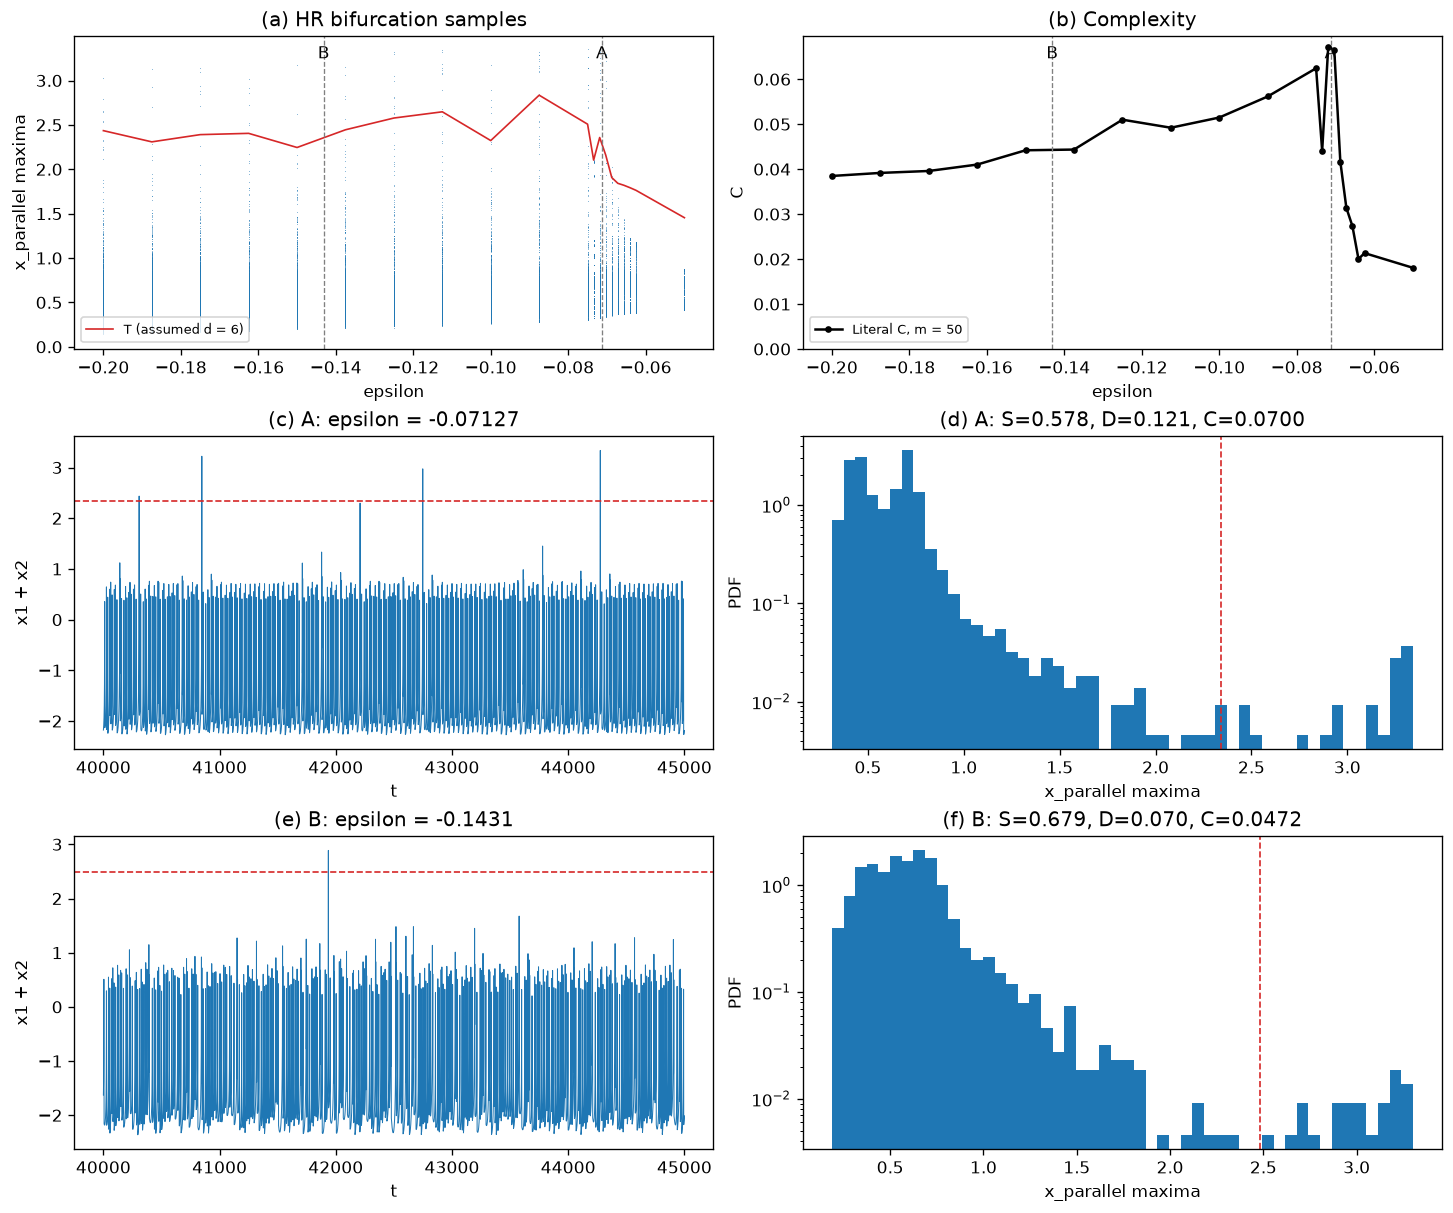

In [35]:
def plot_hr_figure():
    """Plot Fig. 5 from the declared equal-length sweep and longer examples."""
    fig, axes = plt.subplots(3, 2, figsize=(12, 10), layout="constrained")
    for epsilon in hr_parameters:
        peaks = hr_sweep[epsilon]["extrema"]
        axes[0, 0].plot(
            np.full(peaks.size, epsilon),
            peaks,
            ",",
            color="tab:blue",
            alpha=0.5,
        )
    axes[0, 0].plot(
        hr_parameters,
        [hr_summaries[p]["threshold"] for p in hr_parameters],
        color="tab:red",
        lw=1,
        label="T (assumed d = 6)",
    )
    axes[0, 0].set(
        xlabel="epsilon",
        ylabel="x_parallel maxima",
        title="(a) HR bifurcation samples",
    )
    axes[0, 0].legend(fontsize=8, loc="lower left")
    axes[0, 1].plot(
        hr_parameters,
        [hr_summaries[p]["c"] for p in hr_parameters],
        "k.-",
        label="Literal C, m = 50",
    )
    axes[0, 1].set(
        xlabel="epsilon", ylabel="C", title="(b) Complexity", ylim=(0, None)
    )
    axes[0, 1].legend(fontsize=8, loc="lower left")
    for label in ("A", "B"):
        for ax in axes[0]:
            ax.axvline(HR_CASES[label], color="0.5", ls="--", lw=0.8)
            ax.text(
                HR_CASES[label],
                0.97,
                label,
                transform=ax.get_xaxis_transform(),
                ha="center",
                va="top",
            )
    for row, label in enumerate(("A", "B"), 1):
        record, stats = hr_representatives[label], hr_case_summaries[label]
        axes[row, 0].plot(record["trace_time"], record["trace_y"], lw=0.6)
        axes[row, 0].axhline(
            stats["threshold"], color="tab:red", ls="--", lw=1
        )
        axes[row, 0].set(
            xlabel="t",
            ylabel="x1 + x2",
            title=f"({'ce'[row - 1]}) {label}: epsilon = {HR_CASES[label]}",
        )
        widths = np.diff(stats["edges"])
        centers = stats["edges"][:-1] + widths / 2
        occupied = stats["probabilities"] > 0
        density = stats["probabilities"] / widths
        np.testing.assert_allclose(np.sum(density * widths), 1.0)
        axes[row, 1].bar(
            centers[occupied], density[occupied], width=widths[occupied]
        )
        axes[row, 1].axvline(
            stats["threshold"], color="tab:red", ls="--", lw=1
        )
        axes[row, 1].set(
            xlabel="x_parallel maxima",
            ylabel="PDF",
            yscale="log",
            title=f"({'df'[row - 1]}) {label}: S={stats['s']:.3f}, "
            f"D={stats['d']:.3f}, C={stats['c']:.4f}",
        )
    plt.show()


plot_hr_figure()

**Figure:** Fig. 5(a–f).
**Observation:** the 20-point sweep peaks at C ≈ 0.067 near ε = −0.071875;
long A/B records give C ≈ 0.070/0.047, with 25/21 full-record and 4/1 displayed
threshold crossings under the stated d_HR = 6 assumption.
**Scientific meaning:** A/B entropy rises while disequilibrium falls, reducing
C; this alone does not demonstrate more extreme events, and fixed-height counts
31/27 do not establish the paper's increasing-rate interpretation.
**Reproduction status:** **partially reproduced**; broad dynamics, amplitude PDFs,
and the C trend agree qualitatively, while rare counts, the missing HR-specific
threshold factor, sign ambiguity in prose, and unknown author protocols remain.

### 16.3 Threshold and numerical-resolution sensitivity

Since d_HR is unreported, compare 4, 6, and 8 using each **unchanged** A/B peak
sequence. These counts are reference-marker sensitivity, not a change to C.
Separately compare literal m = 50 estimates with the Phase 2 whole-range rule,
using the newly calibrated **HR** resolution only. A broad-amplitude record
must retain its complete probability vector, including rare peaks.

In [36]:
threshold_rows = []
for label, record in hr_representatives.items():
    peaks = record["extrema"]
    c = complexity_measures(amplitude_histogram(peaks)[0])[2]
    for factor in (4, 6, 8):
        threshold = peaks.mean() + factor * peaks.std(ddof=0)
        count = int(np.count_nonzero(peaks > threshold))
        threshold_rows.append(
            [
                label,
                factor,
                f"{threshold:.5f}",
                count,
                f"{1_000 * count / 50_000:.3f}",
                f"{c:.6f}",
            ]
        )
show_table(
    [
        "Case",
        "Assumed d",
        "T",
        "Full peaks > T",
        "Rate / 1000 t",
        "Unchanged C",
    ],
    threshold_rows,
)
resolution_rows = []
for label, records in (
    ("HR main sweep", hr_sweep),
    ("HR long A/B", hr_representatives),
):
    differences, collapsed_count = [], 0
    for record in records.values():
        p = amplitude_histogram(record["extrema"])[0]
        adjusted, _, collapsed = resolved_histogram(
            record["extrema"], HR_RESOLUTION
        )
        if not collapsed:
            np.testing.assert_array_equal(p, adjusted)
        differences.append(
            abs(complexity_measures(p)[2] - complexity_measures(adjusted)[2])
        )
        collapsed_count += int(collapsed)
    resolution_rows.append(
        [label, len(records), collapsed_count, f"{max(differences):.3e}"]
    )
show_table(
    ["Dataset", "Sequences", "Wholly unresolved", "Largest C change"],
    resolution_rows,
)

| Case | Assumed d | T | Full peaks > T | Rate / 1000 t | Unchanged C |
|---|---|---|---|---|---|
| A | 4 | 1.76407 | 38 | 0.760 | 0.069974 |
| A | 6 | 2.33955 | 25 | 0.500 | 0.069974 |
| A | 8 | 2.91503 | 19 | 0.380 | 0.069974 |
| B | 4 | 1.86026 | 29 | 0.580 | 0.047208 |
| B | 6 | 2.48214 | 21 | 0.420 | 0.047208 |
| B | 8 | 3.10401 | 9 | 0.180 | 0.047208 |

| Dataset | Sequences | Wholly unresolved | Largest C change |
|---|---|---|---|
| HR main sweep | 20 | 0 | 0.000e+00 |
| HR long A/B | 2 | 0 | 0.000e+00 |

## 17. Stage D — Figure 6: controlled histogram-bin comparison

For each control value, **one validated peak sequence is reused for m = 25, 50,
75, 100**. S, D, and C are recomputed from probabilities with the corresponding
m in both normalization factors; density heights never enter entropy. Each
array is hashed before and after rebinning to check that it was not replaced
or modified. No new trajectory is generated for a bin count.

Liénard PM/crisis and Ikeda use the exact Phase 2 main-sweep arrays and metadata-
matching numerical protocols (50,000 Liénard time units; 200,000 Ikeda iterates).
HR uses the new **20,000-time-unit main sweep**, restricted to the published
Fig. 6(d) range [−0.15, −0.05]; the longer A/B records are not mixed into this
curve. Different model/time units and protocols are reported separately, not
pooled into a cross-model convergence claim. Cache reloads check equations,
settings, parameters, source hashes, and versions before array identity is checked.

**Solid curves:** the original literal min–max estimator for every model.
**Dashed curves, where different:** the whole-range numerical-resolution
comparison, with Liénard δ from Phase 2 and HR δ from its own local refinement.
The map uses no resolution adjustment. Both estimates are retained; no literal
periodic artifact or unresolved transient is silently removed.

The saved execution reused every input without regeneration. If a required
cache entry is missing during a later run, the documented simulation is rebuilt
once and its equality with the corresponding sweep array is checked. Such
regeneration is counted separately; the four bin counts still cause no simulation.


In [37]:
BIN_COUNTS = (25, 50, 75, 100)
hr_bin_records = {p: r for p, r in hr_sweep.items() if p >= -0.15 - 1e-12}
figure6_sources = {
    "Lienard PM": (
        "lienard",
        pm_sweep,
        LIENARD_SETTINGS,
        AMPLITUDE_RESOLUTION,
    ),
    "Lienard crisis": (
        "lienard",
        crisis_sweep,
        LIENARD_SETTINGS,
        AMPLITUDE_RESOLUTION,
    ),
    "Ikeda": ("ikeda", ikeda_sweep, IKEDA_SETTINGS, 0.0),
    "HR": ("hr", hr_bin_records, HR_SETTINGS, HR_RESOLUTION),
}
previous_computations = CACHE_ACTIVITY["computed"]
previous_hr_computations = HR_CACHE_ACTIVITY["computed"]
provenance_rows = []
for label, (model, records, settings, _resolution) in figure6_sources.items():
    for parameter, record in records.items():
        loaded = (
            cached_hr(parameter, settings)
            if model == "hr"
            else cached_simulation(model, parameter, settings)
        )
        np.testing.assert_array_equal(loaded["extrema"], record["extrema"])
        np.testing.assert_array_equal(
            loaded["extrema_time"], record["extrema_time"]
        )
    duration = (
        settings["retained"] if model == "ikeda" else settings["duration"]
    )
    provenance_rows.append(
        [
            label,
            len(records),
            int(duration),
            "iterates" if model == "ikeda" else "t",
            sum(record["extrema"].size for record in records.values()),
        ]
    )
input_regenerations = CACHE_ACTIVITY["computed"] - previous_computations
hr_input_regenerations = (
    HR_CACHE_ACTIVITY["computed"] - previous_hr_computations
)
show_table(
    [
        "Panel dataset",
        "Control values",
        "Retained / condition",
        "Unit",
        "Total extrema reused",
    ],
    provenance_rows,
)
print("Figure 6 inputs match provenance and the original peak arrays.")
print(
    "Missing input cache entries regenerated:",
    input_regenerations + hr_input_regenerations,
)

| Panel dataset | Control values | Retained / condition | Unit | Total extrema reused |
|---|---|---|---|---|
| Lienard PM | 24 | 50000 | t | 129149 |
| Lienard crisis | 24 | 50000 | t | 145171 |
| Ikeda | 56 | 200000 | iterates | 3391143 |
| HR | 16 | 20000 | t | 22799 |

Figure 6 inputs match provenance and the original peak arrays.
Missing input cache entries regenerated: 0


In [38]:
bin_computations_start = (
    CACHE_ACTIVITY["computed"],
    HR_CACHE_ACTIVITY["computed"],
)
figure6_data = {}
for label, (_, records, _, resolution) in figure6_sources.items():
    parameters = np.array(sorted(records))
    literal = np.empty((parameters.size, len(BIN_COUNTS), 3))
    adjusted = np.empty_like(literal)
    digests, collapsed_flags = [], []
    for row, parameter in enumerate(parameters):
        peaks = records[parameter]["extrema"]
        digest = hashlib.sha256(peaks.tobytes()).hexdigest()
        collapsed = np.ptp(peaks) <= resolution
        values = np.full_like(peaks, peaks.mean()) if collapsed else peaks
        for col, bins in enumerate(BIN_COUNTS):
            p, _ = amplitude_histogram(peaks, bins=bins)
            q, _ = amplitude_histogram(values, bins=bins)
            literal[row, col] = complexity_measures(p)
            adjusted[row, col] = complexity_measures(q)
            np.testing.assert_allclose(p.sum(), 1.0, atol=1e-14)
            np.testing.assert_allclose(q.sum(), 1.0, atol=1e-14)
        assert hashlib.sha256(peaks.tobytes()).hexdigest() == digest
        digests.append(digest)
        collapsed_flags.append(bool(collapsed))
    figure6_data[label] = {
        "parameters": parameters,
        "literal": literal,
        "adjusted": adjusted,
        "peak_sha256": digests,
        "collapsed": collapsed_flags,
    }
print("Computed all S, D, C arrays from identical inputs at four bin counts.")
assert bin_computations_start == (
    CACHE_ACTIVITY["computed"],
    HR_CACHE_ACTIVITY["computed"],
)

Computed all S, D, C arrays from identical inputs at four bin counts.


### 17.1 Figure 6(a–d) — Bin-count sensitivity on fixed trajectories

Panels correspond exactly to the paper: (a) Liénard PM, (b) Liénard crisis,
(c) Ikeda crisis, and (d) HR. All available coarse and refined points of the
stated protocol are plotted without smoothing. Original literal curves remain
visible, with dashed resolution comparisons only where they change C. These
panels isolate bin-count effects conditional on the existing records; they do
not resolve the Phase 2 transition-location or rare-sampling discrepancies.

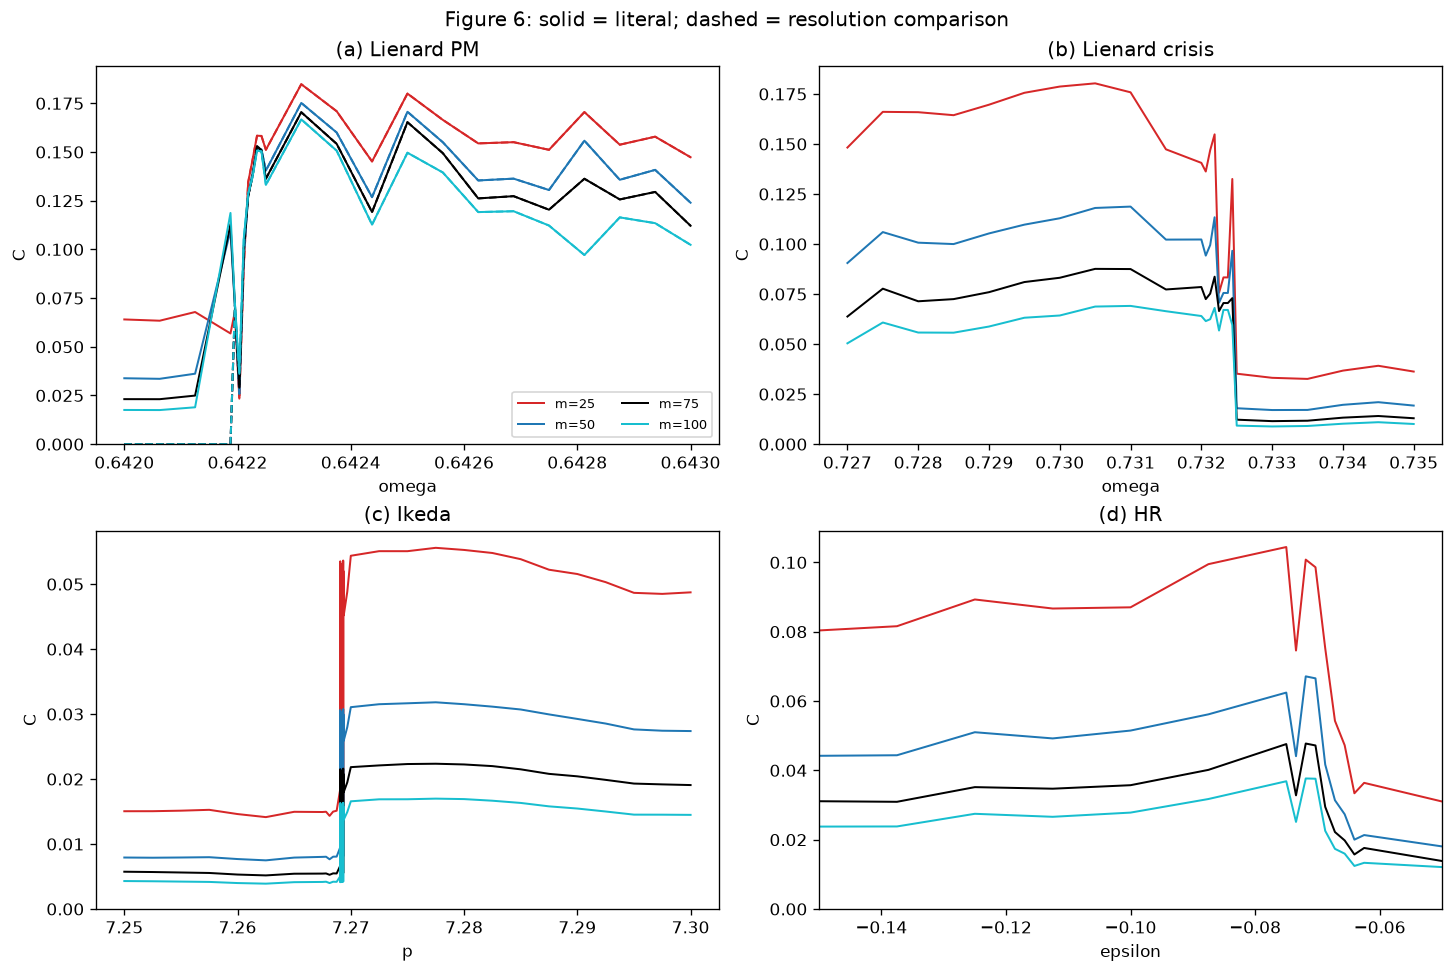

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
colors = ("tab:red", "tab:blue", "black", "tab:cyan")
for ax, (label, data), panel in zip(
    axes.flat, figure6_data.items(), "abcd", strict=True
):
    for index, (bins, color) in enumerate(
        zip(BIN_COUNTS, colors, strict=True)
    ):
        literal = data["literal"][:, index, 2]
        adjusted = data["adjusted"][:, index, 2]
        ax.plot(
            data["parameters"], literal, color=color, lw=1.2, label=f"m={bins}"
        )
        if np.max(np.abs(literal - adjusted)) > 1e-12:
            ax.plot(data["parameters"], adjusted, color=color, lw=1.2, ls="--")
    control = (
        "p" if label == "Ikeda" else "epsilon" if label == "HR" else "omega"
    )
    ax.set(
        xlabel=control, ylabel="C", title=f"({panel}) {label}", ylim=(0, None)
    )
    ax.ticklabel_format(axis="x", useOffset=False)
    if label == "HR":
        ax.set_xlim(-0.15, -0.05)
axes[0, 0].legend(ncol=2, fontsize=8)
fig.suptitle("Figure 6: solid = literal; dashed = resolution comparison")
plt.show()

**Figure:** Fig. 6(a–d), using identical finite peak arrays at all four m.
**Observation:** absolute C varies substantially; the largest adjacent-step
interval changes with m for PM and HR, while it stays in the same recorded
interval for Liénard crisis and Ikeda.
**Scientific meaning:** this is conditional histogram sensitivity, and a stable
curve signature or an m-independent excursion flag does not establish a physical
transition or remove the saved trajectories' sampling and transient biases.
**Reproduction status:** **partially reproduced**; controlled bin-count effects
are verified, with literal and resolution comparisons retained, but quantitative
transition robustness and the published smooth curves are not confirmed.

### 17.2 Quantifying the bin-count dependence

For each curve, report its maximum and the adjacent grid interval with the
largest absolute C change. The latter is only a **numerical curve signature**,
not a new transition detector, confidence interval, or proof of a bifurcation.
Multiple important changes may exist; the full curves and Phase 2 brackets
remain available. Different largest-step intervals across m indicate sensitivity;
identical intervals still inherit the fixed data's temporal and support biases.

In [40]:
bin_rows, bin_audit_rows = [], []
for label, data in figure6_data.items():
    parameters = data["parameters"]
    raw_steps, adjusted_steps = [], []
    for index, bins in enumerate(BIN_COUNTS):
        values = data["literal"][:, index]
        maximum = int(np.argmax(values[:, 2]))
        step = int(np.argmax(np.abs(np.diff(values[:, 2]))))
        adjusted_step = int(
            np.argmax(np.abs(np.diff(data["adjusted"][:, index, 2])))
        )
        raw_steps.append(step)
        adjusted_steps.append(adjusted_step)
        bin_rows.append(
            [
                label,
                bins,
                f"{parameters[maximum]:.7f}",
                *(f"{value:.5f}" for value in values[maximum]),
                f"[{parameters[step]:.7f}, {parameters[step + 1]:.7f}]",
            ]
        )
    spread = np.ptp(data["literal"][:, :, 2], axis=1).max()
    difference = np.max(
        np.abs(data["literal"][:, :, 2] - data["adjusted"][:, :, 2])
    )
    bin_audit_rows.append(
        [
            label,
            len(set(raw_steps)),
            len(set(adjusted_steps)),
            f"{spread:.5f}",
            sum(data["collapsed"]),
            f"{difference:.5f}",
        ]
    )
show_table(
    [
        "Panel",
        "m",
        "Parameter at max C",
        "S there",
        "D there",
        "Max C",
        "Largest literal C-step interval",
    ],
    bin_rows,
)
show_table(
    [
        "Panel",
        "Distinct literal step intervals",
        "Distinct adjusted intervals",
        "Largest C spread across m",
        "Unresolved sequences",
        "Max resolution C change",
    ],
    bin_audit_rows,
)

| Panel | m | Parameter at max C | S there | D there | Max C | Largest literal C-step interval |
|---|---|---|---|---|---|---|
| Lienard PM | 25 | 0.6423125 | 0.37550 | 0.49219 | 0.18482 | [0.6422031, 0.6422109] |
| Lienard PM | 50 | 0.6423125 | 0.36667 | 0.47780 | 0.17520 | [0.6421250, 0.6421875] |
| Lienard PM | 75 | 0.6423125 | 0.36680 | 0.46466 | 0.17044 | [0.6421250, 0.6421875] |
| Lienard PM | 100 | 0.6423125 | 0.37648 | 0.44292 | 0.16675 | [0.6421250, 0.6421875] |
| Lienard crisis | 25 | 0.7305000 | 0.42113 | 0.42816 | 0.18031 | [0.7324375, 0.7325000] |
| Lienard crisis | 50 | 0.7310000 | 0.47764 | 0.24856 | 0.11872 | [0.7324375, 0.7325000] |
| Lienard crisis | 75 | 0.7305000 | 0.54946 | 0.15943 | 0.08760 | [0.7324375, 0.7325000] |
| Lienard crisis | 100 | 0.7310000 | 0.55032 | 0.12555 | 0.06909 | [0.7324375, 0.7325000] |
| Ikeda | 25 | 7.2775000 | 0.71141 | 0.07814 | 0.05559 | [7.2690674, 7.2690723] |
| Ikeda | 50 | 7.2775000 | 0.75390 | 0.04220 | 0.03181 | [7.2690674, 7.2690723] |
| Ikeda | 75 | 7.2775000 | 0.77381 | 0.02889 | 0.02236 | [7.2690674, 7.2690723] |
| Ikeda | 100 | 7.2775000 | 0.78784 | 0.02156 | 0.01699 | [7.2690674, 7.2690723] |
| HR | 25 | -0.0750000 | 0.53712 | 0.19442 | 0.10442 | [-0.0750000, -0.0734375] |
| HR | 50 | -0.0718750 | 0.58502 | 0.11472 | 0.06711 | [-0.0703125, -0.0687500] |
| HR | 75 | -0.0718750 | 0.62043 | 0.07694 | 0.04773 | [-0.0703125, -0.0687500] |
| HR | 100 | -0.0718750 | 0.64124 | 0.05873 | 0.03766 | [-0.0703125, -0.0687500] |

| Panel | Distinct literal step intervals | Distinct adjusted intervals | Largest C spread across m | Unresolved sequences | Max resolution C change |
|---|---|---|---|---|---|
| Lienard PM | 2 | 2 | 0.07337 | 4 | 0.11870 |
| Lienard crisis | 1 | 1 | 0.11441 | 0 | 0.00000 |
| Ikeda | 1 | 1 | 0.03860 | 0 | 0.00000 |
| HR | 2 | 2 | 0.06776 | 0 | 0.00000 |

## 18. Final reproducibility and algorithm audit

The following checks cover the requested four bin counts, all plotted arrays,
and the provenance of every actively reused cache entry. Mathematical bounds
and normalization are assertions; statistical convergence and figure agreement
are assessed separately and are not made to pass by forcing a numerical result.
No expensive Phase 1–2 trajectory was rerun in the saved execution. Missing
cache entries, if encountered later, are regenerated once and reported; earlier
Phase 2 cache creation in a top-to-bottom run is not counted as a Phase 3 rerun.

In [41]:
for bins in BIN_COUNTS:
    concentrated = np.zeros(bins)
    concentrated[0] = 1.0
    uniform = np.full(bins, 1 / bins)
    np.testing.assert_allclose(
        complexity_measures(concentrated), (0, 1, 0), atol=1e-14
    )
    np.testing.assert_allclose(
        complexity_measures(uniform), (1, 0, 0), atol=1e-14
    )
for data in figure6_data.values():
    for key in ("literal", "adjusted"):
        values = data[key]
        assert np.all(np.isfinite(values))
        assert np.all(values >= -1e-14) and np.all(values <= 1 + 1e-14)
        np.testing.assert_allclose(
            values[:, :, 2], values[:, :, 0] * values[:, :, 1]
        )
phase2_regenerated = (
    CACHE_ACTIVITY["computed"] - PHASE2_COMPUTATIONS_AT_PHASE3_START
)
assert phase2_regenerated == input_regenerations
source_sets = {
    "lienard": (MODEL, (lienard, y_maximum, run_lienard_peaks)),
    "ikeda": (IKEDA, (ikeda_real, local_extrema, run_ikeda)),
    "hr": (HR, (hr_rhs, hr_sum_maximum, run_hr)),
}
active_files = CACHE_USED | HR_CACHE_USED
for name in active_files:
    with np.load(CACHE_DIR / name, allow_pickle=False) as saved:
        serialized = saved["metadata"].item()
        metadata = json.loads(serialized)
        parameters, functions = source_sets[metadata["model"]]
        source = "\n".join(inspect.getsource(f) for f in functions)
        assert metadata["parameters"] == parameters
        assert (
            metadata["source_sha256"]
            == hashlib.sha256(source.encode()).hexdigest()
        )
        assert name.endswith(
            hashlib.sha256(serialized.encode()).hexdigest()[:20] + ".npz"
        )
        assert np.all(np.isfinite(saved["extrema"]))
        assert np.all(np.diff(saved["extrema_time"]) > 0)
print("Algorithm bounds and product tests passed for m=25,50,75,100.")
print(
    "Matched source, parameter, metadata hashes and finite extrema:",
    len(active_files),
    "active caches",
)
print(
    "HR main conditions:",
    len(hr_sweep),
    "; HR cache activity:",
    HR_CACHE_ACTIVITY,
)
print("Phase 2 cache regenerations during Phase 3:", phase2_regenerated)
print("All bin comparisons use unchanged, hash-verified peak sequences.")

Algorithm bounds and product tests passed for m=25,50,75,100.
Matched source, parameter, metadata hashes and finite extrema: 133 active caches
HR main conditions: 20 ; HR cache activity: {'hits': 47, 'computed': 0}
Phase 2 cache regenerations during Phase 3: 0
All bin comparisons use unchanged, hash-verified peak sequences.


### Final Reproduction Assessment — Das et al. (2024)

**A. Algorithm correctness.** Interior extrema extraction, zero-probability
handling, normalized amplitude histograms, entropy S, squared-Euclidean
normalized disequilibrium D, and C = SD satisfy the analytical concentrated and
uniform limits. PDF normalization is checked separately from probability
normalization. The four-bin-count comparison reuses identical input arrays and
updates both normalization factors with m. Numerical resolution is an explicitly
labeled diagnostic, not a silent alteration of the original estimator.

**B. Numerical model correctness.** The forced Liénard equations and event
observable y, the equivalent complex/real Ikeda map and local y minima, and the
six-dimensional coupled HR equations and x₁ + x₂ maxima are implemented and
checked. HR uses the printed minus sign with the negative ε of Fig. 5, despite
the contradictory positive-coupling prose. An HR-specific height multiplier is
not supplied by the paper; d_HR = 6 is declared and compared with 4/8. These
ambiguities prevent a claim that the undocumented author code is exactly matched.

**C. Figure reproduction matrix.**

| Figure | Scientific target | Status | Main agreement | Main discrepancy |
|---|---|---|---|---|
| 1 | Liénard bifurcations, S, D, C | Partially reproduced | Both routes exhibit broad support changes and nonmonotone C | Fine-grid onsets differ; residual drift, bounded intervals, and jagged finite statistics remain |
| 2 | Four Liénard temporal/PDF conditions | Partially reproduced | Rare and frequent large excursions, independent thresholds, normalized PDFs | Unknown trajectories; 2 exceedances at ω=0.643; negative-maxima support; selected crisis C ordering differs |
| 3 | Ikeda bifurcation and complexity | Partially reproduced | Broad rise from C≈0.008 to ≈0.032 then decline | Independent finite records alternate detection near crisis; eight-decimal p_c not verified |
| 4 | Three Ikeda temporal/PDF conditions | Partially reproduced | Full-record distributions and C ordering | Fixed rare-event display misses bursts although the full record has 67 threshold crossings |
| 5 | Coupled HR sweep and A/B dynamics/PDFs | Partially reproduced | Signed equations, large excursions, different amplitude distributions and C | Missing HR threshold multiplier, finite tails, initial-state/numerical symmetry sensitivity, no verified critical ε |
| 6 | C at m=25,50,75,100 on four routes | Partially reproduced | Controlled fixed-sequence rebinning and absolute m dependence | Conditional grid signatures do not establish invariant physical transition locations or reproduce smooth original curves |

**D. Numerical uncertainties — four distinct criteria.** Local solver and
sampling refinement supports **numerical accuracy** on the tested short
intervals, not agreement of long chaotic sample paths. Nested-length and
initial-state studies give only partial **statistical convergence**, particularly
for rare tails and near onset. Visible regime/PDF similarities give partial
**figure agreement**. Published transition numbers remain **unverified**:
finite-observation brackets are neither confidence intervals nor dynamical proofs.
Residual transients, min–max support changed by one rare observation, moving
sample thresholds, and bin counts can all affect C. Exact symmetric HR starts
can acquire finite numerical mismatch; this does not prove physical multistability.
The empirically calibrated Liénard and HR resolution scales are local, not
universal accuracy guarantees.

**E. Evidence and interpretation.** The reproduced estimator acts on the
amplitude probability distribution, not event order or the significant-height
marker. Shannon entropy and disequilibrium may move in opposite directions;
their product can rise when a rare tail appears and later fall as probabilities
redistribute. The Liénard routes have different entropy responses, and the HR
A/B records have different S/D balances. However, decreasing C alone does not
prove that extreme-event frequency increased: the observed HR fixed-height
counts do not establish that ordering, and the selected Liénard crisis pair does
not give a universal rare-versus-frequent C ordering. Near the Ikeda crisis, a
single sampled excursion changes histogram support and C substantially. The
physical mechanism behind a sharp C change is a hypothesis until independently
checked; C is not a forecast or a proof of a bifurcation. The largest grid-step interval changes across m for PM and HR in these
records; the HR maximum ranges from about 0.1044 at m = 25 to 0.0377 at m = 100.
The same peak input can therefore give substantially different absolute C.
Permuting the extracted peaks leaves C unchanged because it only uses their
amplitude histogram. Agreement at four bin counts is not universal robustness.

**F. Remaining limits and methodological understanding.** Exact trajectory,
absolute-curve, and transition-precision claims require the original numerical
data or undocumented initial states, integration lengths, continuation protocol,
and clarification of the HR sign/threshold conventions. More independent long
records would be needed to characterize rare rates and basins, but have not been
silently substituted into the main figures. The work is **sufficient to understand
and reproduce the methodological contribution**—complexity from normalized
local-extrema amplitude entropy times disequilibrium—and to examine why it can
distinguish some rare-tail regimes. It is **not sufficient to confirm every
published transition value, curve, or claimed generality**. All requested models
and Figs. 1–6 are assessed; no new method, sliding-window study, reusable Python
package, or additional research phase is begun.